# mini-vLLM, Part 8: A Fused Int8 Kernel, and the Quantized Model as Its Own Draft

**What we will build and measure**

[Stage 8](https://github.com/chizkidd/minivllm/blob/main/07_weight_quantization.ipynb) ended with a no-go. Weight-only int8 halves the bytes a decode step has to read, but none of the three ways PyTorch gave us to multiply by an int8 weight (an eager dequantize, the same under `torch.compile`, `torch._weight_int8pack_mm`) read those bytes as fast as the fp16 layer reads its own, so every int8 decode step was *slower* than fp16, and an int8 draft model raised Stage 7's cost ratio. The 3B model's fp16 step was already at about three quarters of its bandwidth floor, which is exactly where a kernel that reads int8 weights as bytes would matter.

**Stage 9 asks the question Stage 8 left open: write that kernel, and see what it buys, alone and together with speculative decoding.**

1. **Does the quantized model make a good draft for itself?** The int8 copy of a model is nearly the same model (top-1 agreement with fp16 was 98% in Stage 8), so it should guess the fp16 model's next tokens far better than a 0.5B model can. That is a measurement of *acceptance*, which does not depend on any kernel, so we do it first. It tells us whether the idea is worth the rest.
2. **A fused int8 kernel in Triton.** One kernel for a single token, one for a block of tokens (a decode batch, or the checking pass of speculation), both reading the weights as bytes, converting them in registers and accumulating in fp32. Correctness against the dequantize path first, with a control that must fail; then the go/no-go gate on one layer at the real Qwen2.5 shapes, against the fp16 layer and the three ways of Stage 8.
3. **The decode step.** fp16 against int8 for 0.5B, 1.5B and 3B, eager and in a CUDA graph, against the bandwidth floor, and the cost of the checking pass.
4. **Speculation with it.** An int8 target with the n-gram lookup (do the two gains multiply?), and an int8 copy as the draft of the fp16 target (`c`, acceptance, speedup against the n-gram lookup and the 0.5B draft, and the cost model's prediction).

**How to use this notebook.** Same shape as the earlier parts: *Goal, Concept, Code, Result, Takeaway*, with a prediction written down before every benchmark. The "how to read it" notes are written before the numbers exist. The numbers come from your run.

| # | Section | What we learn | Approx. runtime on a Kaggle T4 (estimates) |
| --- | --- | --- | --- |
| 0 | Setup | Reproducible environment, the whole package | seconds |
| 1 | Acceptance of an int8 self-draft | How often the int8 copy guesses the fp16 model's next token, against a 0.5B draft and the n-gram lookup | approx. a few minutes (model loads, short generations) |
| 2 | The kernel | Correctness, tuned block sizes, and whether it beats the fp16 layer | approx. a few minutes (Triton compiles, a tuning grid) |
| 3 | The decode step | fp16 against int8 by size, mode and batch, accuracy unchanged | about ten minutes (five of them on compile warmups) |
| 4 | Speculation with it | Cost ratio, acceptance, speedup, and whether the gains multiply | about half an hour (25 minutes on timed generation) |
| 5 | Save and publish | JSON, figure inventory, GitHub | seconds |
| 6 | Lessons | Summary, questions, exercises | seconds |

**Kaggle setup:** Accelerator = GPU T4 x2 (we use only the first GPU), Internet = On. Run top to bottom and restart the kernel before the final run. Set `QUICK = True` in the setup cell for a pass with the 1.5B target only (a few minutes shorter in each section).

**Self-contained.** Like the earlier parts, the `%%writefile` cells write the whole `minivllm/` and `bench/` packages and the notebook imports them. `minivllm/int8_kernel.py` is new, and `minivllm/quant.py` gained a third path, `"triton"`. `bench/metrics.py` gained `tune_int8_kernel`, the `include_triton` option of `linear_gate`, and a `baseline_runs` option of `sweep_proposers` that times the plain baseline several times and takes the median (Stage 7 timed it once, and one slow baseline moved a whole row).

---
## 0. Setup

**Goal:** one imports cell, one environment record, then the package.

- `CUDA_VISIBLE_DEVICES=0` is set *before* importing torch, so "we only use one GPU" is enforced rather than assumed.
- `ENV` records GPU, torch, transformers, Triton and python versions, saved with the results.
- `QUICK = True` shrinks the run: one target, fewer prompts and repeats.
- After editing a `%%writefile` cell, re-run it and then restart the kernel, because modules that were already imported keep their old code.

In [1]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle T4 x2: use one GPU only

import gc, platform, random, time

import numpy as np
import pandas as pd
import torch, transformers

for d in ("minivllm", "bench", "results"):
    os.makedirs(d, exist_ok=True)
for pkg in ("minivllm", "bench"):
    open(f"{pkg}/__init__.py", "a").close()

assert torch.cuda.is_available(), "Turn on a GPU accelerator in Kaggle settings"
import triton

QUICK = False   # True: the 1.5B target only, fewer prompts and repeats
SEED = 0

ENV = {
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "triton": triton.__version__,
    "python": platform.python_version(),
}
print(ENV)

{'gpu': 'Tesla T4', 'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'triton': '3.6.0', 'python': '3.13.15'}


### The package

What is new in this part (everything else is repeated verbatim from Part 7):

| File | New in this part |
| --- | --- |
| `minivllm/int8_kernel.py` | **new.** The Triton kernels (`gemv1` for one token, `dot` for a block of tokens), the table of tuned block sizes, and `int8_matmul`. Explained in section 2. |
| `minivllm/quant.py` | a third path, `"triton"`, in `qlinear` and `PATHS`. |
| `bench/metrics.py` | `tune_int8_kernel`, `include_triton` in `linear_gate`, `baseline_runs` in `sweep_proposers`. |

In [2]:
%%writefile minivllm/model.py
import torch
import torch.nn.functional as F

from .quant import QWeight, qlinear

def linear(x, w, b=None):
    """F.linear, or the int8 weight-only product (Stage 8) when w is a QWeight. The fp16 path is F.linear itself."""
    if isinstance(w, QWeight):
        return qlinear(x, w, b)
    return F.linear(x, w, b)

def rms_norm(x, weight, eps):
    xf = x.float()
    xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + eps)
    return weight * xf.to(x.dtype)

def rotate_half(x):
    h = x.shape[-1] // 2
    return torch.cat((-x[..., h:], x[..., :h]), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin

class MiniQwen:
    def __init__(self, hf_model, max_pos=2048):
        cfg = hf_model.config
        self.n_layers = cfg.num_hidden_layers
        self.n_heads = cfg.num_attention_heads
        self.n_kv = cfg.num_key_value_heads
        self.hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // self.n_heads
        self.n_rep = self.n_heads // self.n_kv
        self.eps = cfg.rms_norm_eps

        m = hf_model.model
        self.embed = m.embed_tokens.weight
        self.norm_w = m.norm.weight
        self.lm_head = hf_model.lm_head.weight
        self.device, self.dtype = self.embed.device, self.embed.dtype
        self.layers = []
        for l in m.layers:
            a, mlp = l.self_attn, l.mlp
            self.layers.append(dict(
                ln1=l.input_layernorm.weight, ln2=l.post_attention_layernorm.weight,
                q_w=a.q_proj.weight, q_b=a.q_proj.bias,
                k_w=a.k_proj.weight, k_b=a.k_proj.bias,
                v_w=a.v_proj.weight, v_b=a.v_proj.bias,
                o_w=a.o_proj.weight,
                gate=mlp.gate_proj.weight, up=mlp.up_proj.weight, down=mlp.down_proj.weight,
            ))

        theta = getattr(cfg, "rope_theta", None)
        if theta is None:
            theta = cfg.rope_parameters["rope_theta"]
        inv = 1.0 / (theta ** (torch.arange(0, self.hd, 2, device=self.device).float() / self.hd))
        t = torch.arange(max_pos, device=self.device).float()
        emb = torch.cat([torch.outer(t, inv)] * 2, dim=-1)
        self.cos, self.sin = emb.cos().to(self.dtype), emb.sin().to(self.dtype)

    @torch.no_grad()
    def forward(self, ids, cache=None, positions=None, attn_mask=None, all_logits=False):
        """
        ids: [B, T]. Returns logits for the LAST position only: [B, vocab].
        Batching of sequences with different lengths (Stage 3) adds two optional inputs:
          positions: [B, T] RoPE position of every token (default: consecutive from the cache length).
          attn_mask: bool [B, 1, T, L], True = this query may attend to this key, where L is the
                     number of keys after the cache update (default: causal, no padding).
        Speculative decoding (Stage 6) adds all_logits: return the logits of every position, [B, T, vocab], so
        one pass can check several drafted tokens. Feeding T > 1 tokens on top of a non-empty cache (the checking
        pass) needs an explicit attn_mask, because the default causal mask assumes an empty cache.
        """
        B, T = ids.shape
        pos0 = cache.length if cache is not None else 0
        assert not (cache is not None and T > 1 and pos0 > 0 and attn_mask is None), \
            "several tokens on a non-empty cache need an explicit attn_mask"
        if positions is None:
            assert pos0 + T <= self.cos.shape[0], "sequence longer than RoPE table"
            cos = self.cos[pos0:pos0 + T][None, None]
            sin = self.sin[pos0:pos0 + T][None, None]
        else:
            cos = self.cos[positions][:, None]   # [B, 1, T, head_dim]
            sin = self.sin[positions][:, None]

        x = F.embedding(ids, self.embed)
        for i, L in enumerate(self.layers):
            h = rms_norm(x, L["ln1"], self.eps)
            q = linear(h, L["q_w"], L["q_b"]).view(B, T, self.n_heads, self.hd).transpose(1, 2)
            k = linear(h, L["k_w"], L["k_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            v = linear(h, L["v_w"], L["v_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
            if cache is not None:
                k, v = cache.update(i, k, v)
            # Expand KV heads to match query heads (GQA). Wasteful, a known optimization target.
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
            a = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                               is_causal=(attn_mask is None and T > 1))
            a = a.transpose(1, 2).reshape(B, T, -1)
            x = x + linear(a, L["o_w"])
            h = rms_norm(x, L["ln2"], self.eps)
            x = x + linear(F.silu(linear(h, L["gate"])) * linear(h, L["up"]), L["down"])
        if cache is not None:
            cache.advance(T)
        x = rms_norm(x if all_logits else x[:, -1], self.norm_w, self.eps)
        return linear(x, self.lm_head)

Writing minivllm/model.py


In [3]:
%%writefile minivllm/batching.py
import torch

def left_pad(seqs, pad_id, device, pad_to=None):
    """
    Stack variable-length token lists into one [B, T] tensor, padding on the LEFT so that the
    last column is a real token for every sequence (generation reads the last position).
    Returns (ids [B, T], lens [B]) where lens are the real prompt lengths. `pad_to` forces a
    longer T than the longest prompt (e.g. to round up to a multiple of 8). 
    
    If you use `pad_to`, build the matching `Layout(..., T=ids.shape[1])` too: Layout assumes 
    the longest prompt otherwise, and its positions and masks would not fit the tensor.
    """
    lens = [len(s) for s in seqs]
    T = max(lens + [pad_to or 0])
    ids = torch.full((len(seqs), T), pad_id, dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, T - len(s):] = torch.as_tensor(s, dtype=torch.long)
    return ids.to(device), torch.tensor(lens, device=device)

class Layout:
    """
    Positions and attention masks for one wave of left-padded sequences.
    
      column:   0 1 2 3 4 5 | 6 7 8 ...      T = longest prompt, then generated tokens follow
      seq A:    . . A A A A | g g g          (. = padding, A = prompt token, g = generated)
      seq B:    . B B B B B | g g g
    
    Every sequence shares the same cache columns, so the cache stays a single rectangle. Padding
    columns are never attended to, and RoPE positions count only real tokens (A starts at 0).
    """                                                                         
    def __init__(self, lens, max_new, device, T=None):
        self.lens = lens.to(device)                         # [B] real prompt lengths
        self.T = T or int(self.lens.max())                  # padded prompt length (columns)
        self.device = device
        self.pad = self.T - self.lens                       # [B] padding columns per sequence
        cols = torch.arange(self.T + max_new, device=device)
        self.key_real = cols[None, :] >= self.pad[:, None]  # [B, T + max_new]: True on real tokens

    def prefill(self):
        """positions [B, T] and mask [B, 1, T, T] for the prompt pass."""
        T, dev = self.T, self.device
        cols = torch.arange(T, device=dev)
        positions = (cols[None, :] - self.pad[:, None]).clamp(min=0)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=dev))
        mask = causal[None] & self.key_real[:, None, :T]
        # A padding query would otherwise have no key to attend to. A fully masked row makes the
        # softmax NaN, and 0 * NaN is NaN, so it would poison real tokens. Let it see itself.
        mask = mask | torch.eye(T, dtype=torch.bool, device=dev)[None]
        return positions, mask[:, None]

    def decode(self, j):
        """
        positions [B, 1] and mask [B, 1, 1, L] for the step that consumes generated token j
        (j = 1 is the token the prompt pass produced). It sits in cache column T + j - 1.
        """
        positions = (self.lens + (j - 1))[:, None]
        mask = self.key_real[:, None, None, :self.T + j]
        return positions, mask

Writing minivllm/batching.py


In [4]:
%%writefile minivllm/block_allocator.py
from collections import deque


class BlockAllocator:
    """
    A pool of `num_blocks` fixed-size KV blocks, handed out and taken back by id.

    The allocator knows nothing about tensors or tokens: it only tracks which block ids are free. A sequence
    that needs `n` blocks gets a list of `n` ids (its block table) and gives them back when it finishes, so
    memory freed by one request is immediately usable by the next, whatever their lengths.

    Free ids are kept in a FIFO queue. That is not required for correctness, but it recycles blocks in
    release order, so after some churn a sequence's blocks are scattered over the pool instead of forming one
    contiguous run, which is exactly the situation a block table exists to handle.
    """
    def __init__(self, num_blocks):
        assert num_blocks > 0
        self.num_blocks = num_blocks
        self._free = deque(range(num_blocks))
        self._in_use = [False] * num_blocks

    @property
    def num_free(self):
        return len(self._free)

    @property
    def num_used(self):
        return self.num_blocks - len(self._free)

    def can_allocate(self, n):
        return n <= len(self._free)

    def allocate(self, n):
        """Take `n` free blocks. Returns their ids; raises if the pool cannot supply them."""
        if not self.can_allocate(n):
            raise MemoryError(f"need {n} blocks, only {len(self._free)} free")
        ids = [self._free.popleft() for _ in range(n)]
        for b in ids:
            self._in_use[b] = True
        return ids

    def free(self, ids):
        """Give blocks back. Freeing a block that is not in use is a bug (a double free), so it raises."""
        for b in ids:
            if not self._in_use[b]:
                raise ValueError(f"block {b} is not in use")
            self._in_use[b] = False
            self._free.append(b)

Writing minivllm/block_allocator.py


In [5]:
%%writefile minivllm/kv_cache.py
import torch
import torch.nn.functional as F

from .block_allocator import BlockAllocator

class KVCache:
    """
    Contiguous, preallocated cache for a batch of sequences.
    Each tensor has shape [n_layers, batch, n_kv_heads, max_len, head_dim].
    """
    def __init__(self, n_layers, batch, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, batch, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.length = 0
        self.max_len = max_len

    def update(self, layer, k, v):
        """k, v: [batch, n_kv_heads, T, head_dim]. Returns everything cached so far."""
        T = k.shape[2]
        end = self.length + T
        assert end <= self.max_len, "KV cache overflow"
        self.k[layer, :, :, self.length:end] = k
        self.v[layer, :, :, self.length:end] = v
        return self.k[layer, :, :, :end], self.v[layer, :, :, :end]

    def advance(self, T):
        """Called once per forward pass, after all layers have written."""
        self.length += T

    def truncate(self, length):
        """Forget everything after the first `length` tokens (Stage 6: drop the rejected draft tokens).
        The old keys stay in memory but are never read, and the next write overwrites them."""
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()

    @staticmethod
    def bytes_per_token(n_layers, n_kv_heads, head_dim, dtype_bytes=2):
        return 2 * n_layers * n_kv_heads * head_dim * dtype_bytes


class SlotCache:
    """
    A fixed pool of `slots` sequence slots, each with room for `max_len` tokens, for continuous batching.
    Shape [n_layers, slots, n_kv_heads, max_len, head_dim], like KVCache, but every slot has its OWN length
    (`lens`). A finished sequence frees its slot at once and a waiting request is prefilled into it, while
    the other slots keep decoding. Each slot is still one contiguous worst-case rectangle (Stage 5 replaces
    that with blocks).

    model.forward only needs `length`, `update` and `advance`, so two small views plug the pool into it:
      prefill_view(slot): one new prompt (batch 1, no padding) written into one free slot.
      decode_view():      one token for EVERY slot at its own column. Slots that are free decode a dummy
                          token that is masked and overwritten later, which keeps the batch shape fixed.
    """
    def __init__(self, n_layers, slots, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, slots, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.slots, self.max_len, self.device = slots, max_len, device
        self.lens = [0] * slots     # tokens stored per slot; plain ints, so reading them never syncs the GPU

    def prefill_view(self, slot):
        return _PrefillView(self, slot)

    def decode_view(self):
        return _DecodeView(self)

    def free(self, slot):
        self.lens[slot] = 0

    @property
    def used_tokens(self):
        return sum(self.lens)

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty slot

    def __init__(self, cache, slot):
        assert cache.lens[slot] == 0, "slot is not free"
        self.c, self.slot = cache, slot

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]."""
        T = k.shape[2]
        assert T <= self.c.max_len, "KV slot overflow"
        self.c.k[layer, self.slot, :, :T] = k[0]
        self.c.v[layer, self.slot, :, :T] = v[0]
        return self.c.k[layer, self.slot:self.slot + 1, :, :T], self.c.v[layer, self.slot:self.slot + 1, :, :T]

    def advance(self, T):
        self.c.lens[self.slot] = T


class _DecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache):
        self.c = cache
        self.rows = torch.arange(cache.slots, device=cache.device)
        self.cols = torch.tensor(cache.lens, device=cache.device)   # the column each slot writes its new token to
        self.end = max(cache.lens) + 1                               # columns that can matter this step
        assert self.end <= cache.max_len, "KV slot overflow"

    def update(self, layer, k, v):
        """k, v: [slots, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every slot."""
        self.c.k[layer, self.rows, :, self.cols] = k[:, :, 0]
        self.c.v[layer, self.rows, :, self.cols] = v[:, :, 0]
        return self.c.k[layer, :, :, :self.end], self.c.v[layer, :, :, :self.end]

    def advance(self, T):
        pass     # the scheduler advances only the slots that are actually running


class PagedCache:
    """
    A KV cache made of fixed-size blocks drawn from one shared pool (Stage 5).
    Each tensor has shape [n_layers, num_blocks, n_kv_heads, block_size, head_dim]. A sequence does not own a
    rectangle: it owns a list of block ids (its block table) and a length, and token t of the sequence lives in
    block table[t // block_size] at offset t % block_size. Blocks are handed out by a BlockAllocator when a
    sequence is added and returned the moment it is freed, so a request holds memory for the tokens it needs,
    not for the longest request the server might ever see.

    Sequences are named by any hashable id (we use the request id). `add(seq, tokens)` reserves enough blocks
    for the whole request, `tokens` = prompt + generated tokens that will be stored, so a running sequence can
    never run out of blocks half way (Stage 5 keeps admission simple; reserving lazily needs preemption,
    which is exercise 1).

    model.forward only needs `length`, `update` and `advance`, so two views plug the pool into it, as for SlotCache:
      prefill_view(seq):  one new prompt (batch 1, no padding) written into the sequence's blocks.
      decode_view(seqs):  one token for each listed sequence, each written at its own position. The keys and
                          values of those sequences are gathered through their block tables into one dense
                          tensor, then ordinary attention runs on it.
    """
    def __init__(self, n_layers, num_blocks, block_size, n_kv_heads, head_dim, device, dtype):
        shape = (n_layers, num_blocks, n_kv_heads, block_size, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.num_blocks, self.block_size, self.device = num_blocks, block_size, device
        self.n_kv_heads, self.head_dim = n_kv_heads, head_dim
        self.allocator = BlockAllocator(num_blocks)
        self.tables = {}     # seq -> list of block ids
        self.lens = {}       # seq -> tokens stored (plain ints, so reading them never syncs the GPU)
        self.cap = {}        # seq -> tokens reserved for it

    def blocks_for(self, tokens):
        return -(-tokens // self.block_size)

    def can_admit(self, tokens):
        return self.allocator.can_allocate(self.blocks_for(tokens))

    def add(self, seq, tokens):
        """Reserve blocks for a sequence that will store up to `tokens` tokens."""
        assert seq not in self.tables, "sequence already in the cache"
        self.tables[seq] = self.allocator.allocate(self.blocks_for(tokens))
        self.lens[seq], self.cap[seq] = 0, tokens

    def free(self, seq):
        """Give the sequence's blocks back to the pool. Their contents are not erased, only forgotten."""
        self.allocator.free(self.tables.pop(seq))
        del self.lens[seq], self.cap[seq]

    def prefill_view(self, seq):
        return _PagedPrefillView(self, seq)

    def decode_view(self, seqs):
        return _PagedDecodeView(self, list(seqs))

    @property
    def used_tokens(self):
        """Tokens actually stored."""
        return sum(self.lens.values())

    @property
    def reserved_tokens(self):
        """Tokens the running sequences will have stored when they finish."""
        return sum(self.cap.values())

    @property
    def allocated_tokens(self):
        """Token capacity of the blocks handed out (reserved tokens rounded up to whole blocks)."""
        return self.allocator.num_used * self.block_size

    @property
    def bytes_per_block(self):
        return 2 * self.k.shape[0] * self.k[0, 0].numel() * self.k.element_size()

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PagedPrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty sequence

    def __init__(self, cache, seq):
        assert cache.lens[seq] == 0, "sequence already has tokens"
        self.c, self.seq = cache, seq

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes them block by block and returns them unchanged."""
        c, T = self.c, k.shape[2]
        assert T <= c.cap[self.seq], "KV reservation overflow"
        nb = c.blocks_for(T)
        blocks = torch.tensor(c.tables[self.seq][:nb], device=c.device)
        pad = nb * c.block_size - T
        for cache_t, x in ((c.k, k), (c.v, v)):
            # [n_kv, T, hd] -> pad the last block with zeros -> [nb, n_kv, block_size, hd]
            x = F.pad(x[0], (0, 0, 0, pad)).view(c.n_kv_heads, nb, c.block_size, c.head_dim).transpose(0, 1)
            cache_t[layer, blocks] = x
        return k, v   # a prefill attends to the prompt it just computed, so there is nothing to gather

    def advance(self, T):
        self.c.lens[self.seq] = T


class _PagedDecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache, seqs):
        self.c = cache
        bs = cache.block_size
        lens = [cache.lens[s] for s in seqs]
        assert all(l < cache.cap[s] for s, l in zip(seqs, lens)), "KV reservation overflow"
        self.end = max(lens) + 1                      # columns that can matter this step
        nb = cache.blocks_for(self.end)
        # Block table of the batch, [n, nb]. A sequence with fewer blocks is padded with block 0: those columns
        # lie beyond its position, so the attention mask hides whatever they hold.
        table = [(cache.tables[s] + [0] * nb)[:nb] for s in seqs]
        self.table = torch.tensor(table, device=cache.device)
        self.wblk = torch.tensor([cache.tables[s][l // bs] for s, l in zip(seqs, lens)], device=cache.device)
        self.woff = torch.tensor([l % bs for l in lens], device=cache.device)

    def update(self, layer, k, v):
        """k, v: [n, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every sequence, gathered."""
        c = self.c
        c.k[layer, self.wblk, :, self.woff] = k[:, :, 0]
        c.v[layer, self.wblk, :, self.woff] = v[:, :, 0]
        n, nb = self.table.shape
        out = []
        for cache_t in (c.k, c.v):
            g = cache_t[layer][self.table]                                    # [n, nb, n_kv, block_size, hd]
            g = g.permute(0, 2, 1, 3, 4).reshape(n, c.n_kv_heads, nb * c.block_size, c.head_dim)
            out.append(g[:, :, :self.end])
        return out[0], out[1]

    def advance(self, T):
        pass     # the scheduler advances only the sequences that are actually running

Writing minivllm/kv_cache.py


In [6]:
%%writefile minivllm/speculative.py
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class PromptLookup:
    """
    A draft that needs no model: look for an earlier place in the context where the last few tokens occurred
    before, and propose the tokens that followed them there. It works when the output repeats the input
    (copying, quoting, code that repeats itself) and proposes nothing when it does not.

    Longer n-grams are tried first (the most recent match of the longest one that matches wins), down to
    `ngram_min`. `__call__(context, k)` returns up to `k` token ids, or [] if nothing matches.
    """
    def __init__(self, ngram_max=3, ngram_min=1):
        assert 1 <= ngram_min <= ngram_max
        self.ngram_max, self.ngram_min = ngram_max, ngram_min

    def __call__(self, context, k):
        n_ctx = len(context)
        if k <= 0:
            return []
        for n in range(min(self.ngram_max, n_ctx - 1), self.ngram_min - 1, -1):
            tail = context[-n:]
            for i in range(n_ctx - n - 1, -1, -1):       # most recent earlier occurrence first
                if context[i] == tail[0] and context[i:i + n] == tail:
                    return list(context[i + n:i + n + k])  # not empty: i + n <= n_ctx - 1
        return []


@torch.no_grad()
def generate_speculative(model, prompt_ids, max_new, k=4, proposer=None, rollback=True):
    """
    Greedy generation of one sequence, several tokens per forward pass when the draft is right.

    Each iteration the draft proposes up to k tokens. One forward pass feeds the last generated token and the
    draft, [last, d1, ..., dk], on top of the cache, with a causal mask over the cache, and returns the model's
    own greedy choice after every one of them: c0 (after last), c1 (after d1), ... The draft is accepted while it
    agrees with the model: d1 is right if c0 == d1, d2 is right if c1 == d2, and so on. If `a` drafts are right,
    the pass has produced a + 1 tokens (c0 .. ca, the last one is a free "bonus"), and the cache keeps the first
    a + 1 of the fed tokens. Because every token comes from the model's own greedy choice, the output is the same
    as plain greedy decoding, just in fewer passes. If the draft is empty or wrong, the pass is an ordinary
    decode step.

    rollback=False skips the cache truncation, which makes the output wrong as soon as a draft is rejected. It
    exists only for the negative control in the notebook.

    prompt_ids: list of token ids. Returns (generated token ids, stats), stats = {"ttft": seconds,
    "steps": [{"drafted": n, "accepted": a, "step_s": seconds} per pass after the prefill]}.
    """
    proposer = proposer or PromptLookup()
    device = model.device
    ids = torch.tensor([list(prompt_ids)], device=device)
    P = ids.shape[1]
    room = k + 1 if rollback else max_new * (k + 1)       # without rollback the rejected tokens pile up in the cache
    cache = KVCache(model.n_layers, 1, model.n_kv, P + max_new + room, model.hd, device, model.dtype)
    t0 = _tick()
    tokens = [int(model.forward(ids, cache).argmax(-1))]
    ttft = _tick() - t0
    steps = []
    while len(tokens) < max_new:
        remaining = max_new - len(tokens)
        draft = proposer(list(prompt_ids) + tokens, min(k, remaining - 1)) if remaining > 1 else []
        feed = torch.tensor([[tokens[-1]] + draft], device=device)
        pos0, T = cache.length, feed.shape[1]
        mask = None
        if T > 1:    # query j sits at position pos0 + j and may attend to every key up to and including its own
            mask = (torch.arange(pos0 + T, device=device)[None, :] <= (pos0 + torch.arange(T, device=device))[:, None])[None, None]
        t1 = _tick()
        choice = model.forward(feed, cache, attn_mask=mask, all_logits=True).argmax(-1)[0].tolist()
        dt = _tick() - t1
        a = 0
        while a < len(draft) and choice[a] == draft[a]:
            a += 1
        tokens += choice[:a + 1]
        if rollback:
            cache.truncate(pos0 + a + 1)
        steps.append(dict(drafted=len(draft), accepted=a, step_s=dt))
    return tokens[:max_new], {"ttft": ttft, "steps": steps}

Writing minivllm/speculative.py


In [7]:
%%writefile minivllm/draft.py
import statistics
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class StaticKVCache:
    """
    A KV cache whose tensors never change shape: [n_layers, 1, n_kv_heads, max_len, head_dim], one sequence.
    A forward pass writes its new keys at explicit positions (a device tensor set with `set_write`) and returns
    the WHOLE buffer, so the attention mask, not a slice, decides which keys count. That is what lets a decode
    step be captured in a CUDA graph: every shape, and every address, is the same on every step. `length` is a
    plain Python int that the owner keeps up to date, because the model's own length bookkeeping is not used.
    """
    def __init__(self, n_layers, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, 1, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.max_len = max_len
        self.length = 0
        self.pos = None

    def set_write(self, positions):
        """positions: long tensor [T], where the next forward pass writes its T new keys."""
        self.pos = positions

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes at the positions set by set_write, returns every key."""
        self.k[layer].index_copy_(2, self.pos, k)
        self.v[layer].index_copy_(2, self.pos, v)
        return self.k[layer], self.v[layer]

    def advance(self, T):
        pass     # the owner moves `length`

    def truncate(self, length):
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length


class DraftModel:
    """
    A small model used as the guesser of speculative decoding (Stage 7). It has the same interface as
    PromptLookup, `proposer(context, k) -> list of up to k token ids`, so generate_speculative can use either.

    The draft model keeps its own KV cache of the context it has seen. On each call:
      1. SYNC. The context grew since the last call (the target accepted some drafts and added a bonus token),
         so the draft's cache is truncated to the longest prefix it shares with the new context, never longer
         than len(context) - 1, so there is always at least one new token to feed and fresh logits to read.
         The keys of drafted tokens the target accepted are kept (no recompute), the rest are dropped.
      2. FEED the tokens of the context the cache does not have yet (the whole prompt on the first call, then
         the bonus token, or the last drafted token and the bonus after a fully accepted draft) in ONE pass,
         and read the logits after the last one: that is the first guess.
      3. GUESS k - 1 more tokens greedily, one single-token step each, feeding each guess back in.
    So a call costs k draft forward passes, the unit the cost model of Stage 7 uses.

    mode:
      "eager":  an ordinary KVCache and one forward pass per step, as the target runs.
      "static": the same steps over a StaticKVCache (fixed shapes), run eagerly. It exists so the benefit of
                a CUDA graph can be told apart from the cost of the fixed-shape path.
      "graph":  the single-token step is captured once in a CUDA graph and replayed, which removes the
                per-kernel launch cost that dominates a small model's step. Needs a CUDA device. If capture is
                not possible the model falls back to "static" and `graph_error` says why.
    sync=False is the negative control: it does not truncate (it forgets to roll back after a rejection), so the
    stale keys of rejected guesses stay in the cache and its guesses get worse. The target still checks every
    token, so the OUTPUT stays correct, only the acceptance collapses.
    """
    def __init__(self, model, max_len, mode="eager", sync=True):
        assert mode in ("eager", "static", "graph")
        self.model, self.max_len, self.sync = model, max_len, sync
        self.device, self.mode = model.device, mode
        self.graph_error, self._graph = None, None
        self.tokens = []                 # the context tokens whose keys are in the cache (sync=True)
        self._ctx_fed = 0                # sync=False only: how much of the context has been fed
        if mode == "eager":
            self.cache = KVCache(model.n_layers, 1, model.n_kv, max_len, model.hd, self.device, model.dtype)
        else:
            self.cache = StaticKVCache(model.n_layers, model.n_kv, max_len, model.hd, self.device, model.dtype)
            self._tok = torch.zeros((1, 1), dtype=torch.long, device=self.device)
            self._posv = torch.zeros((1,), dtype=torch.long, device=self.device)
            self._cols = torch.arange(max_len, device=self.device)
        if mode == "graph":
            self._try_capture()

    # ---- the single-token step over the static cache, the part a CUDA graph captures ---------------------------
    def _step(self):
        """Feed self._tok at position self._posv, write its keys, and leave the next guess in self._tok."""
        self.cache.set_write(self._posv)
        mask = (self._cols[None, :] <= self._posv[:, None])[None, None]            # [1, 1, 1, max_len]
        logits = self.model.forward(self._tok, self.cache, positions=self._posv[None, :], attn_mask=mask)
        nxt = logits.argmax(-1, keepdim=True)
        self._tok.copy_(nxt)
        self._posv.add_(1)
        return nxt

    def _try_capture(self):
        if self.device.type != "cuda" or not torch.cuda.is_available():
            self.graph_error, self.mode = "CUDA graphs need a CUDA device", "static"
            return
        try:
            stream = torch.cuda.Stream()
            stream.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(stream):
                for _ in range(3):                      # warm-up on a side stream, as CUDA graph capture requires
                    self._posv.zero_()
                    self._tok.zero_()
                    self._step()
            torch.cuda.current_stream().wait_stream(stream)
            torch.cuda.synchronize()
            graph = torch.cuda.CUDAGraph()
            self._posv.zero_()
            self._tok.zero_()
            with torch.cuda.graph(graph):
                self._step()
            self._graph = graph
            self.cache.k.zero_()                        # the warm-up wrote junk at the first positions
            self.cache.v.zero_()
        except Exception as e:                          # capture can fail for reasons that depend on the torch build
            self._graph = None
            self.graph_error, self.mode = f"{type(e).__name__}: {e}", "static"

    # ---- feeding tokens ------------------------------------------------------------------------------------
    def _feed(self, new):
        """Append the tokens `new` (a list) to the cache and return the logits after the last one, [1, vocab]."""
        T, n0 = len(new), self.cache.length
        assert n0 + T <= self.max_len, f"the draft cache holds {self.max_len} tokens, needs {n0 + T}"
        ids = torch.tensor([new], device=self.device)
        if self.mode == "eager":
            mask = None
            if T > 1 and n0 > 0:     # several tokens on top of a non-empty cache need an explicit causal mask
                mask = (torch.arange(n0 + T, device=self.device)[None, :]
                        <= (n0 + torch.arange(T, device=self.device))[:, None])[None, None]
            return self.model.forward(ids, self.cache, attn_mask=mask)
        positions = torch.arange(n0, n0 + T, device=self.device)
        self.cache.set_write(positions)
        mask = (self._cols[None, :] <= positions[:, None])[None, None]            # [1, 1, T, max_len]
        logits = self.model.forward(ids, self.cache, positions=positions[None, :], attn_mask=mask)
        self.cache.length = n0 + T
        return logits

    # ---- the proposer interface ----------------------------------------------------------------------------
    @torch.no_grad()
    def __call__(self, context, k):
        context = list(context)
        n_ctx = len(context)
        if k <= 0 or n_ctx == 0:
            return []
        assert n_ctx + k <= self.max_len, f"the draft cache holds {self.max_len} tokens, needs {n_ctx + k}"
        if self.sync:
            lcp, limit = 0, min(len(self.tokens), n_ctx - 1)
            while lcp < limit and self.tokens[lcp] == context[lcp]:
                lcp += 1
            self.cache.truncate(lcp)
            self.tokens = self.tokens[:lcp]
            new = context[lcp:]
            self.tokens += new
        else:                                   # the broken control: never roll back, only append what is new
            new = context[self._ctx_fed:] or context[-1:]
            self._ctx_fed = n_ctx
        logits = self._feed(new)
        if self.mode == "eager":
            guesses = [int(logits.argmax(-1))]
            for _ in range(k - 1):
                logits = self.model.forward(torch.tensor([[guesses[-1]]], device=self.device), self.cache)
                guesses.append(int(logits.argmax(-1)))
        else:
            self._tok.copy_(logits.argmax(-1, keepdim=True))
            self._posv.fill_(self.cache.length)
            picked = [self._tok.clone()]
            for _ in range(k - 1):
                if self._graph is not None:
                    self._graph.replay()
                else:
                    self._step()
                picked.append(self._tok.clone())
            self.cache.length += k - 1
            guesses = torch.cat(picked, dim=1)[0].tolist()                        # one sync for the whole draft
        if self.sync:
            self.tokens += guesses[:-1]         # the last guess was never fed, so it has no keys
        return guesses

    def reset(self):
        """Forget everything cached (a new unrelated sequence). Not needed between calls: the sync handles it."""
        self.cache.length = 0
        self.tokens, self._ctx_fed = [], 0

    # ---- cost ----------------------------------------------------------------------------------------------
    @torch.no_grad()
    def time_step(self, context_len, iters=20, warmup=3):
        """
        Milliseconds (median) of one single-token draft step, argmax included, on top of `context_len` cached
        tokens (whatever the cache holds there, which does not change the work), in this model's own mode. This is
        the numerator of c, the draft step time over the target step time. The cache is left exactly as it was.
        """
        assert context_len < self.max_len, "the draft cache has no room for a step at this length"
        saved = (self.cache.length, self.tokens, self._ctx_fed)
        slot = (self.cache.k[..., context_len, :].clone(), self.cache.v[..., context_len, :].clone())   # the only keys a step here writes
        times = []
        for i in range(warmup + iters):
            self.cache.length = context_len
            if self.mode == "eager":
                tok = torch.zeros((1, 1), dtype=torch.long, device=self.device)
                t0 = _tick()
                int(self.model.forward(tok, self.cache).argmax(-1))
            else:
                self._tok.zero_()
                self._posv.fill_(context_len)
                t0 = _tick()
                if self._graph is not None:
                    self._graph.replay()
                else:
                    self._step()
            dt = _tick() - t0
            if i >= warmup:
                times.append(dt)
        self.cache.length, self.tokens, self._ctx_fed = saved
        self.cache.k[..., context_len, :] = slot[0]
        self.cache.v[..., context_len, :] = slot[1]
        return 1000 * statistics.median(times)


class TimedProposer:
    """Wraps any proposer and records the wall time of every call, so the cost of guessing can be separated from
    the cost of checking. Works the same for PromptLookup and DraftModel."""
    def __init__(self, proposer):
        self.proposer, self.times = proposer, []

    def __call__(self, context, k):
        t0 = _tick()
        out = self.proposer(context, k)
        self.times.append(_tick() - t0)
        return out

Writing minivllm/draft.py


In [8]:
%%writefile minivllm/quant.py
import copy

import torch
import torch.nn.functional as F


class QWeight:
    """
    A weight-only int8 matrix (Stage 8): q is int8 [out, in] and scale holds one value per output channel
    ([out]), or a single value for the per-tensor control. The matrix it stands for is q * scale per row, and a
    linear layer computes x @ q.T * scale, so the activations stay in fp16 and only the weights are small.
    `path` picks how the product is computed (see qlinear).
    """
    def __init__(self, q, scale, dtype, path="dequant"):
        assert q.dtype == torch.int8 and q.dim() == 2
        assert scale.numel() in (1, q.shape[0])
        self.q, self.scale, self.dtype, self.path = q, scale, dtype, path

    @property
    def shape(self):
        return self.q.shape

    @property
    def device(self):
        return self.q.device

    @property
    def nbytes(self):
        return self.q.numel() * self.q.element_size() + self.scale.numel() * self.scale.element_size()


@torch.no_grad()
def quantize_weight(w, per_channel=True, path="dequant"):
    """
    Symmetric int8 quantization of a [out, in] matrix. One scale per output channel (a row) by default, so a row with large
    weights does not coarsen the steps of every other row; per_channel=False uses one scale for the whole matrix (the control
    that shows why). Values map to [-127, 127], so zero stays exactly zero.

    Runs without autograd, as do dequantize, reconstruction_error and channel_errors. A Hugging Face weight is an nn.Parameter
    that requires grad, and a scale computed from one outside no_grad would carry a graph that keeps two fp32 copies of the
    whole matrix alive (8 bytes per weight), enough to fill a 16 GB GPU while quantizing a 0.5B model three times.
    """
    assert w.dim() == 2
    wf = w.float()
    amax = wf.abs().amax(dim=1, keepdim=True) if per_channel else wf.abs().amax().reshape(1, 1)
    scale = (amax / 127.0).clamp(min=1e-8)
    q = torch.round(wf / scale).clamp(-127, 127).to(torch.int8)
    return QWeight(q, scale.reshape(-1).to(w.dtype), w.dtype, path=path)


@torch.no_grad()
def dequantize(qw):
    """The matrix a QWeight stands for, in its original dtype (a copy: this is what the eager path materializes)."""
    s = qw.scale if qw.scale.numel() == 1 else qw.scale[:, None]
    return qw.q.to(qw.dtype) * s


@torch.no_grad()
def reconstruction_error(w, qw):
    """(relative Frobenius error, largest absolute error) of the quantized matrix against the original."""
    diff = dequantize(qw).float() - w.float()
    return (diff.norm() / w.float().norm()).item(), diff.abs().max().item()


@torch.no_grad()
def channel_errors(w, qw):
    """Relative error of every output channel (row): ||dequantized row - row|| / ||row||. The Frobenius error of the whole
    matrix is dominated by its large rows and hides what happens to the small ones, which this shows."""
    diff = dequantize(qw).float() - w.float()
    return diff.norm(dim=1) / w.float().norm(dim=1).clamp(min=1e-12)


PATHS = ("dequant", "intpack", "triton")

# The int8 product x @ q.T is about 127 / amax(row) times bigger than the real output, and fp16 stops at 65504. Outputs of a
# few hundred (Qwen has such activations) times a factor of a hundred or more would overflow to infinity. Scaling the input by
# a power of two first costs nothing in precision and keeps the unscaled product inside the range; the scale undoes it.
PRE = 2.0 ** -7


def qlinear(x, qw, bias=None):
    """
    x @ W.T + bias for a quantized W. Three paths compute the same thing:
      "dequant":  F.linear(x * PRE, q.to(x.dtype)) * (scale / PRE). Eagerly this writes a full fp copy of the weights and reads
                  it back, which moves MORE bytes than the fp16 layer it replaces; it only pays if a compiler fuses the
                  int8-to-fp16 conversion into the matmul. The scale is applied to the small output, not to the weights.
      "intpack":  torch._weight_int8pack_mm, a fused weight-only int8 matmul that accumulates in fp32 and applies the scales
                  itself, where this build provides one.
      "triton":   the fused Triton kernel of minivllm/int8_kernel.py (Stage 9): reads the weights as bytes, converts them in
                  registers, accumulates in fp32 and applies the scale to the fp32 result. Needs Triton.
    """
    if qw.path == "triton":
        from .int8_kernel import int8_matmul
        y = int8_matmul(x, qw.q, qw.scale)
    elif qw.path == "intpack":
        y = torch._weight_int8pack_mm(x.reshape(-1, x.shape[-1]), qw.q, qw.scale.to(x.dtype)).reshape(*x.shape[:-1], qw.q.shape[0])
    else:
        y = F.linear(x * PRE, qw.q.to(x.dtype)) * (qw.scale.to(x.dtype) * (1.0 / PRE))
    return y if bias is None else y + bias


_LINEAR_KEYS = ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down")


def quantize_model(model, per_channel=True, path="dequant", quantize_lm_head=True, inplace=False):
    """
    A MiniQwen whose linear weights (and, by default, lm_head) are QWeights. The embedding table, the norm weights,
    the biases and the RoPE tables stay as they are. With inplace=False the original model is left alone and the
    result shares everything but the replaced matrices; with inplace=True the original's matrices are replaced too,
    so the fp16 copies can be freed (after dropping any other references to them, such as the Hugging Face model).
    A tied lm_head (the same tensor as the embedding table) is quantized into its own int8 copy: the table stays fp16
    for the lookup, and the matmul reads the small copy.
    """
    new = model if inplace else copy.copy(model)
    layers = []
    for L in model.layers:
        nl = dict(L)
        for key in _LINEAR_KEYS:
            nl[key] = quantize_weight(L[key], per_channel, path)
        layers.append(nl)
    new.layers = layers
    if quantize_lm_head:
        new.lm_head = quantize_weight(model.lm_head, per_channel, path)
    return new


def set_path(model, path):
    """Switch every QWeight of a quantized model to another matmul path (no copy)."""
    assert path in PATHS
    for L in model.layers:
        for key in _LINEAR_KEYS:
            if isinstance(L[key], QWeight):
                L[key].path = path
    if isinstance(model.lm_head, QWeight):
        model.lm_head.path = path
    return model


def _nbytes(t):
    return t.nbytes if isinstance(t, QWeight) else t.numel() * t.element_size()


def weight_bytes_stored(model):
    """Bytes of weights the model holds in memory (a tensor shared by the embedding and a tied lm_head counts once)."""
    seen, total = set(), 0
    def add(t):
        nonlocal total
        key = (t.q.data_ptr(), t.scale.data_ptr()) if isinstance(t, QWeight) else t.data_ptr()
        if key not in seen:
            seen.add(key)
            total += _nbytes(t)
    add(model.embed); add(model.norm_w); add(model.lm_head)
    for L in model.layers:
        for t in L.values():
            if t is not None:
                add(t)
    return total


def weight_bytes_read(model):
    """
    Bytes a batch-1 decode step has to read from the weights: every matrix, bias and norm once, plus one embedding
    row. This is the number a bandwidth ceiling divides, and it differs from the stored bytes when the embedding
    table is kept for lookup next to a quantized lm_head (the table is stored but only one row of it is read).
    """
    total = model.embed.shape[1] * model.embed.element_size() + _nbytes(model.norm_w) + _nbytes(model.lm_head)
    for L in model.layers:
        for t in L.values():
            if t is not None:
                total += _nbytes(t)
    return total

Writing minivllm/quant.py


In [9]:
%%writefile minivllm/int8_kernel.py
"""
A fused weight-only int8 matmul in Triton (Stage 9): y = (x @ q.T) * scale, with q an int8 [N, K] matrix and one scale per
output row. The weights are read from memory as bytes, converted to the activation dtype in registers and multiplied there,
so the only traffic is one byte per weight. Stage 8 found that every way PyTorch offers to multiply by an int8 weight
(an eager dequantize, the same under torch.compile, torch._weight_int8pack_mm) is slower than the fp16 layer on a T4,
because none of them reads the weights as bytes at the rate fp16 reads its own. This kernel is the fix being tested.

Two kernels, because a decode step and a checking block ask for different things:
  gemv1: one token (M == 1). A tile of BLOCK_N weight rows by BLOCK_K weights is multiplied by the matching slice of x on the
         FMA units and the products are kept in a [BLOCK_N, BLOCK_K] accumulator, reduced once at the end.
  dot:   M tokens (a checking block of k + 1 tokens, a prompt). The x rows are tiled by BLOCK_M (16 for up to 16 rows, as tl.dot
         needs, and 64 beyond), the int8 tile is converted to the activation dtype and a tensor-core dot accumulates in fp32.
Both accumulate in fp32 and apply the scale to the fp32 result, so unlike the eager dequantize there is no fp16 overflow to
guard against (no input prescale) and the scale never touches the weights. Block sizes come from an explicit table filled by a
tuning run (bench.metrics.tune_int8_kernel) and not from Triton's autotuner, which times candidate launches and so cannot run
inside CUDA-graph capture; an untuned shape falls back to a heuristic.

Triton is optional. Without it HAVE_TRITON is False and int8_matmul raises; the rest of the package never imports this module
unless a QWeight has path "triton". With TRITON_INTERPRET=1 (set before the first import) the kernels run on the CPU in Triton's
interpreter, which is how the tests check them without a GPU.
"""
import torch

try:
    import triton
    import triton.language as tl
    HAVE_TRITON = True
except Exception:                       # no Triton on this machine
    triton = tl = None
    HAVE_TRITON = False


if HAVE_TRITON:
    @triton.jit
    def _gemv1_kernel(x_ptr, q_ptr, s_ptr, y_ptr, N, K, stride_qn, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr):
        pid = tl.program_id(0)
        offs_n = pid * BLOCK_N + tl.arange(0, BLOCK_N)
        n_mask = offs_n < N
        acc = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            k_mask = k < K
            w = tl.load(q_ptr + offs_n[:, None] * stride_qn + k[None, :], mask=n_mask[:, None] & k_mask[None, :], other=0)
            x = tl.load(x_ptr + k, mask=k_mask, other=0.0)
            acc += w.to(tl.float32) * x.to(tl.float32)[None, :]
        s = tl.load(s_ptr + offs_n, mask=n_mask, other=0.0).to(tl.float32)
        y = tl.sum(acc, axis=1) * s
        tl.store(y_ptr + offs_n, y.to(y_ptr.dtype.element_ty), mask=n_mask)

    @triton.jit
    def _dot_kernel(x_ptr, q_ptr, s_ptr, y_ptr, M, N, K, stride_xm, stride_qn, stride_ym,
                    BLOCK_M: tl.constexpr, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr):
        pid_n = tl.program_id(0)
        pid_m = tl.program_id(1)
        offs_m = pid_m * BLOCK_M + tl.arange(0, BLOCK_M)
        offs_n = pid_n * BLOCK_N + tl.arange(0, BLOCK_N)
        m_mask = offs_m < M
        n_mask = offs_n < N
        acc = tl.zeros((BLOCK_M, BLOCK_N), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            k_mask = k < K
            x = tl.load(x_ptr + offs_m[:, None] * stride_xm + k[None, :], mask=m_mask[:, None] & k_mask[None, :], other=0.0)
            w = tl.load(q_ptr + offs_n[None, :] * stride_qn + k[:, None], mask=n_mask[None, :] & k_mask[:, None], other=0)
            acc += tl.dot(x, w.to(x.dtype))
        s = tl.load(s_ptr + offs_n, mask=n_mask, other=0.0).to(tl.float32)
        y = acc * s[None, :]
        tl.store(y_ptr + offs_m[:, None] * stride_ym + offs_n[None, :], y.to(y_ptr.dtype.element_ty), mask=m_mask[:, None] & n_mask[None, :])


VARIANTS = ("gemv1", "dot")
NUM_SMS = 40            # the T4's multiprocessors; only used to size the default tile so that every SM gets work

_CONFIGS = {}           # (N, K, m_bucket) -> config, filled by a tuning run

# The candidates a tuning run times (bench.metrics.tune_int8_kernel). Many of them share a compiled kernel across shapes, since
# block sizes are compile-time constants and nothing else about a shape changes the code, so tuning many shapes compiles few kernels.
GEMV1_GRID = [{"variant": "gemv1", "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw} for bn in (2, 4, 8, 16) for bk in (128, 256, 512) for nw in (2, 4, 8)]
DOT_GRID = [{"variant": "dot", "BLOCK_M": 16, "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw, "num_stages": 2}
            for bn in (32, 64, 128) for bk in (64, 128) for nw in (4, 8)]


def m_bucket(M):
    """The row counts that share a tuned configuration: one token, a small block (a decode batch or a checking block), a prompt."""
    return 1 if M == 1 else (16 if M <= 16 else 64)


def default_config(N, K, M):
    """A configuration for a shape that was not tuned. The tile is sized so the grid has at least a couple of programs per SM."""
    if M == 1:
        bn = 16
        while bn > 1 and -(-N // bn) < 2 * NUM_SMS:
            bn //= 2
        return {"variant": "gemv1", "BLOCK_N": bn, "BLOCK_K": 256, "num_warps": 4}
    return {"variant": "dot", "BLOCK_M": 16 if M <= 16 else 64, "BLOCK_N": 64 if N >= 1024 else 32, "BLOCK_K": 64, "num_warps": 4, "num_stages": 2}


def set_configs(table):
    """Install a tuned table {(N, K, m_bucket): config}; it replaces whatever was there."""
    _CONFIGS.clear()
    _CONFIGS.update(table)


def get_configs():
    return dict(_CONFIGS)


def config_for(N, K, M):
    return _CONFIGS.get((N, K, m_bucket(M))) or default_config(N, K, M)


def int8_matmul(x, q, scale, config=None):
    """
    x [..., K] (fp16 on a GPU; fp32 or fp16 in the interpreter), q int8 [N, K], scale [N] (or one value) -> [..., N] in x's dtype.
    `config` overrides the table, for tuning and tests: {"variant": "gemv1", "BLOCK_N", "BLOCK_K", "num_warps"} or
    {"variant": "dot", "BLOCK_M", "BLOCK_N", "BLOCK_K", "num_warps", "num_stages"}.
    """
    if not HAVE_TRITON:
        raise RuntimeError("Triton is not available on this machine, so the 'triton' path cannot run")
    N, K = q.shape
    assert x.shape[-1] == K and q.dtype == torch.int8 and q.is_contiguous()
    x2 = x.reshape(-1, K)
    if not x2.is_contiguous():
        x2 = x2.contiguous()
    M = x2.shape[0]
    s = scale.reshape(-1)
    if s.numel() == 1:
        s = s.expand(N).contiguous()
    y = torch.empty((M, N), dtype=x.dtype, device=x.device)
    cfg = config or config_for(N, K, M)
    if cfg["variant"] == "gemv1":
        assert M == 1, "the gemv1 kernel handles one token; use the dot kernel for more"
        grid = (triton.cdiv(N, cfg["BLOCK_N"]),)
        _gemv1_kernel[grid](x2, q, s, y, N, K, q.stride(0), BLOCK_N=cfg["BLOCK_N"], BLOCK_K=cfg["BLOCK_K"], num_warps=cfg.get("num_warps", 4))
    else:
        assert cfg["variant"] == "dot", cfg
        grid = (triton.cdiv(N, cfg["BLOCK_N"]), triton.cdiv(M, cfg["BLOCK_M"]))
        _dot_kernel[grid](x2, q, s, y, M, N, K, x2.stride(0), q.stride(0), y.stride(0), BLOCK_M=cfg["BLOCK_M"], BLOCK_N=cfg["BLOCK_N"],
                          BLOCK_K=cfg["BLOCK_K"], num_warps=cfg.get("num_warps", 4), num_stages=cfg.get("num_stages", 2))
    return y.reshape(*x.shape[:-1], N)

Writing minivllm/int8_kernel.py


In [10]:
%%writefile minivllm/scheduler.py
import time
from collections import deque
from dataclasses import dataclass, field
import torch
from .kv_cache import KVCache, SlotCache, PagedCache
from .batching import left_pad, Layout

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@dataclass
class Request:
    id: int
    prompt_ids: list      # token ids of the prompt
    max_new: int          # tokens to generate (stands in for "until EOS" with synthetic prompts)
    arrival_s: float = 0.0   # when the request arrives, seconds from run start (Stage 4 load; Stage 3 uses 0 for all)

@dataclass
class RequestResult:
    id: int
    wave: int
    prompt_len: int
    max_new: int
    tokens: list          # the max_new generated token ids
    first_token_s: float  # seconds from run start to the first token
    finish_s: float       # seconds from run start to this request's own last token
    release_s: float      # seconds from run start until its wave ends and the batch returns

@dataclass
class StaticRun:
    results: list
    waves: list           # one dict per wave (see run_static)
    total_s: float

@torch.no_grad()
def run_static(model, requests, batch_size, pad_id=0):
    """
    Static batching: take the next `batch_size` requests, left-pad them into one batch, prefill
    once, then decode until the LONGEST request in the batch is done. A request that finishes
    early keeps its slot and keeps being computed (wasted work) until the whole batch ends.
    All requests arrive at t = 0 and waves run back to back.
    """
    results, waves = [], []
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd,
                                  torch.empty((), dtype=model.dtype).element_size())
    t_run = _tick()
    for w, start in enumerate(range(0, len(requests), batch_size)):
        wave = requests[start:start + batch_size]
        B = len(wave)
        max_new = max(r.max_new for r in wave)
        ids, lens = left_pad([r.prompt_ids for r in wave], pad_id, model.device)
        T = ids.shape[1]
        assert T + max_new <= model.cos.shape[0], "wave longer than the RoPE table"
        layout = Layout(lens, max_new, model.device)
        # The last generated token is never fed back in, so it is never stored: T + max_new - 1 columns.
        cache = KVCache(model.n_layers, B, model.n_kv, T + max_new - 1, model.hd, model.device, model.dtype)

        t0 = _tick()
        positions, mask = layout.prefill()
        nxt = model.forward(ids, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
        prev = _tick()
        ttft = prev - t0
        out, step_times = [nxt], []
        for j in range(1, max_new):
            positions, mask = layout.decode(j)
            nxt = model.forward(nxt, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
            now = _tick()
            step_times.append(now - prev)
            prev = now
            out.append(nxt)
        toks = torch.cat(out, dim=1).cpu()
        t_end = _tick()

        # When did each request produce its own last token?
        cum = [ttft]
        for s in step_times:
            cum.append(cum[-1] + s)
        for i, r in enumerate(wave):
            results.append(RequestResult(
                id=r.id, wave=w, prompt_len=len(r.prompt_ids), max_new=r.max_new,
                tokens=toks[i, :r.max_new].tolist(),
                first_token_s=(t0 - t_run) + ttft,
                finish_s=(t0 - t_run) + cum[r.max_new - 1],
                release_s=t_end - t_run))
        lens_l = [len(r.prompt_ids) for r in wave]
        waves.append(dict(
            wave=w, B=B, T=T, max_new=max_new,
            prompt_real=sum(lens_l), prompt_slots=B * T,
            decode_slot_steps=B * (max_new - 1),
            decode_useful=sum(r.max_new - 1 for r in wave),
            useful_tokens=sum(r.max_new for r in wave),
            ttft_s=ttft, step_times=step_times, wave_s=t_end - t0,
            kv_alloc_bytes=cache.nbytes,
            kv_used_bytes=bpt * sum(l + r.max_new - 1 for l, r in zip(lens_l, wave))))   # real tokens actually stored
    return StaticRun(results=results, waves=waves, total_s=_tick() - t_run)


# ---------------------------------------------------------------------------------------------
# Stage 4: requests arrive over time, and the server either batches them statically or continuously.
# Both policies run on a virtual clock: it advances by the measured GPU time of each step and jumps
# over idle gaps, so a low-load run takes seconds, not minutes, and latency is still exact.

@dataclass
class OnlineResult:
    id: int
    prompt_len: int
    max_new: int
    arrival_s: float       # when the request arrived
    admit_s: float         # when its prefill (or its batch) started: arrival to admit is queueing
    first_token_s: float   # when its first token existed
    finish_s: float        # when its own last token existed
    release_s: float       # when the caller got the answer (static: its batch ended; continuous: finish_s)
    tokens: list

@dataclass
class OnlineRun:
    results: list          # one OnlineResult per request, ordered by request id
    steps: list            # continuous: one dict per decode step (start_s, step_s, active, kv_tokens, gap_s); paged adds
                           # kv_alloc_tokens, kv_need_tokens, waiting, mem_blocked; static: empty
    prefills: list         # continuous: one dict per prefill (id, start_s, prefill_s, prompt_len); static: empty
    makespan_s: float      # virtual time when the last request was released
    busy_s: float          # time the GPU was working (makespan minus idle gaps)
    policy: str
    slots: int             # concurrency limit: batch size (static), slot count (continuous) or max sequences (paged)
    max_len: int = 0       # tokens each slot can hold (continuous)
    pool_tokens: int = 0   # token capacity of the whole KV pool (paged: blocks * block_size)
    block_size: int = 0    # tokens per block (paged)

@torch.no_grad()
def run_static_online(model, requests, batch_size, pad_id=0):
    """
    Static batching under arrivals. Whenever the GPU is free it takes the requests that have already
    arrived, up to `batch_size` (it does not wait for a full batch), and runs them as one static wave
    exactly as run_static does. If nothing is waiting it idles until the next arrival.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    results, now, busy = [], 0.0, 0.0
    while pending:
        now = max(now, pending[0].arrival_s)                       # idle until someone arrives
        wave = []
        while pending and pending[0].arrival_s <= now and len(wave) < batch_size:
            wave.append(pending.popleft())
        sub = run_static(model, wave, batch_size=len(wave), pad_id=pad_id)
        for r, res in zip(wave, sub.results):
            results.append(OnlineResult(
                id=r.id, prompt_len=res.prompt_len, max_new=r.max_new, arrival_s=r.arrival_s, admit_s=now,
                first_token_s=now + res.first_token_s, finish_s=now + res.finish_s,
                release_s=now + res.release_s, tokens=res.tokens))
        now += sub.total_s
        busy += sub.total_s
    results.sort(key=lambda x: x.id)
    return OnlineRun(results=results, steps=[], prefills=[], makespan_s=now, busy_s=busy,
                     policy="static", slots=batch_size)

@torch.no_grad()
def run_continuous(model, requests, slots, pad_id=0, max_prefills=None):
    """
    Continuous (iteration-level) batching with a pool of `slots` sequence slots. Every iteration:
      1. requests that have arrived join a FIFO queue,
      2. free slots are filled from the queue: each new request is prefilled alone into its slot (no
         padding), up to `max_prefills` per iteration (None = fill every free slot),
      3. one decode step runs for all slots, each at its own position,
      4. a request that reached its max_new is released at once and its slot is free for step 2.
    So nothing waits for a stranger's long answer, and no slot idles while someone is queued.
    Free slots decode a dummy token that is masked out, which keeps the batch shape fixed.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in pending)
    assert max_len + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = SlotCache(model.n_layers, slots, model.n_kv, max_len, model.hd, model.device, model.dtype)
    waiting, running = deque(), {}                 # running: slot -> state of the request in it
    last = [pad_id] * slots                        # the token each slot feeds into its next decode step
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0     # end time of the last decode step, and how many requests it left running

    def finish(slot, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(slot)
        last[slot] = pad_id
        running.pop(slot, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        for slot in range(slots):
            if not waiting or (max_prefills is not None and admitted >= max_prefills):
                break
            if slot in running:
                continue
            r = waiting.popleft()
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(slot)).argmax(-1))     # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(slot, st, now)
            else:
                running[slot] = st
                last[slot] = tok

        if running:
            t0 = _tick()
            lens = list(cache.lens)
            view = cache.decode_view()
            positions = torch.tensor(lens, device=model.device)[:, None]                        # [slots, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            nxt = model.forward(torch.tensor(last, device=model.device)[:, None], view,
                                positions=positions, attn_mask=mask).argmax(-1).tolist()      # .tolist() waits
            dt = _tick() - t0
            # gap_s: what a request that was already running sees between two tokens, i.e. this step plus any
            # prefills that ran in between (None if nothing was running after the previous step)
            steps.append(dict(start_s=now, step_s=dt, active=len(running), kv_tokens=sum(lens) + len(running),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for slot, st in list(running.items()):
                cache.lens[slot] += 1
                st["tokens"].append(nxt[slot])
                last[slot] = nxt[slot]
                if len(st["tokens"]) == st["req"].max_new:
                    finish(slot, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="continuous", slots=slots, max_len=max_len)


@torch.no_grad()
def run_paged(model, requests, num_blocks, block_size=16, max_seqs=32, pad_id=0, max_prefills=None):
    """
    Continuous batching on a paged KV cache (Stage 5). It is run_continuous with two differences:
      memory:  there are no slots. A request is admitted when a free block can hold everything it will store
               (prompt + max_new - 1 tokens), and its blocks go back to the pool when it finishes. The head of
               the queue waits for memory and nobody jumps ahead of it (first come, first served).
      batch:   a decode step runs only the sequences that are running, gathering their keys and values through
               their block tables, so there are no dummy rows. `max_seqs` caps how many run at once.
    Everything else (virtual clock, prefill per request, release at once) is as in run_continuous.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    need = {r.id: len(r.prompt_ids) + r.max_new - 1 for r in pending}
    assert max(need.values()) + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = PagedCache(model.n_layers, num_blocks, block_size, model.n_kv, model.hd, model.device, model.dtype)
    assert cache.blocks_for(max(need.values())) <= num_blocks, "the pool cannot hold the largest request"
    waiting, running = deque(), {}                 # running: request id -> state (insertion order = admission order)
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0

    def finish(seq, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(seq)
        running.pop(seq, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        while (waiting and len(running) < max_seqs and (max_prefills is None or admitted < max_prefills)
               and cache.can_admit(need[waiting[0].id])):
            r = waiting.popleft()
            cache.add(r.id, need[r.id])
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(r.id)).argmax(-1))      # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(r.id, st, now)
            else:
                running[r.id] = st

        if running:
            t0 = _tick()
            seqs = list(running)
            lens = [cache.lens[s] for s in seqs]
            view = cache.decode_view(seqs)
            positions = torch.tensor(lens, device=model.device)[:, None]                         # [n, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            last = torch.tensor([running[s]["tokens"][-1] for s in seqs], device=model.device)[:, None]
            nxt = model.forward(last, view, positions=positions, attn_mask=mask).argmax(-1).tolist()   # waits
            dt = _tick() - t0
            steps.append(dict(start_s=now, step_s=dt, active=len(seqs), kv_tokens=sum(lens) + len(seqs),
                              kv_alloc_tokens=cache.allocated_tokens, kv_need_tokens=cache.reserved_tokens,
                              waiting=len(waiting),
                              mem_blocked=bool(waiting) and len(running) < max_seqs and not cache.can_admit(need[waiting[0].id]),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for seq, tok in zip(seqs, nxt):
                st = running[seq]
                cache.lens[seq] += 1
                st["tokens"].append(tok)
                if len(st["tokens"]) == st["req"].max_new:
                    finish(seq, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="paged", slots=max_seqs,
                     pool_tokens=num_blocks * block_size, block_size=block_size)

Writing minivllm/scheduler.py


In [11]:
%%writefile minivllm/engine.py
import time
import torch
from .kv_cache import KVCache

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@torch.no_grad()
def generate_naive(model, ids, n_new):
    """No cache: recompute the full sequence for every new token."""
    for _ in range(n_new):
        nxt = model.forward(ids).argmax(-1, keepdim=True)
        ids = torch.cat([ids, nxt], dim=1)
    return ids

@torch.no_grad()
def generate_cached(model, ids, n_new, decode_fn=None):
    """
    Prefill once, then decode one token at a time using the cache.
    decode_fn(ids, cache) -> logits replaces model.forward for the decode steps only
    (e.g. a torch.compile'd forward). Prefill always runs eagerly.
    Returns (all_ids, {"ttft": seconds, "itl": [seconds per decode step]}).
    """
    decode = decode_fn or model.forward
    B, T = ids.shape
    cache = KVCache(model.n_layers, B, model.n_kv, T + n_new, model.hd, ids.device, model.dtype)
    t0 = _tick()
    nxt = model.forward(ids, cache).argmax(-1, keepdim=True)
    prev = _tick()
    ttft = prev - t0
    out, itl = [nxt], []
    for _ in range(n_new - 1):
        nxt = decode(nxt, cache).argmax(-1, keepdim=True)
        now = _tick()
        itl.append(now - prev)
        prev = now
        out.append(nxt)
    return torch.cat([ids] + out, dim=1), {"ttft": ttft, "itl": itl}

Writing minivllm/engine.py


In [12]:
%%writefile minivllm/utils.py
def first_mismatch(a, b):
    """Index of the first position where two token lists differ, or None if they match."""
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None

Writing minivllm/utils.py


In [13]:
%%writefile bench/workload.py
import random
from dataclasses import replace

from minivllm.scheduler import Request

# Named workloads. Prompt lengths are drawn from `prompt_lens`; each request is "long" with
# probability p_long (output length drawn from long_out) and "short" otherwise (from short_out).
WORKLOADS = {
    "equal": dict(prompt_lens=(128,), short_out=(64, 64), long_out=(64, 64), p_long=0.0),
    "mixed": dict(prompt_lens=(32, 64, 128, 256, 512), short_out=(16, 48), long_out=(128, 256), p_long=0.25),
}

def spread_prompt_lens(base, factor, k=5):
    """
    k prompt lengths spread geometrically from base to base * factor (factor 1 = all equal).
    Lengths are rounded to integers, so with a small base or factor several can collide and the
    result has fewer than k distinct lengths (spread_prompt_lens(10, 1.2) gives 3 values).
    """
    assert k >= 2, "need at least two lengths to spread between base and base * factor"
    return tuple(sorted({round(base * factor ** (i / (k - 1))) for i in range(k)}))

def make_requests(n, seed=0, vocab=(1000, 20000), **spec):
    """
    `spec` is a WORKLOADS entry (or the same keys); returns n Requests with random token ids.
    Fixed seeds make every run (and every batch size) see the same requests.
    Careful with the bounds: `vocab` is a half-open range (the upper id is excluded), while the
    `short_out` and `long_out` ranges for max_new are inclusive on both ends.
    """
    rng = random.Random(seed)
    reqs = []
    for i in range(n):
        plen = rng.choice(spec["prompt_lens"])
        out = spec["long_out"] if rng.random() < spec["p_long"] else spec["short_out"]
        reqs.append(Request(i, [rng.randrange(*vocab) for _ in range(plen)], rng.randint(*out)))
    return reqs

def padding_pct(spread, seed, batch=8, base=64, n_new=64):
    """
    Padding share (in %) of the prompt slots of ONE static batch of `batch` requests drawn with this seed:
    100 * (1 - real prompt tokens / (batch * longest prompt)). CPU only: it needs prompt lengths, not a model.
    It builds the requests exactly like the benchmark does, so seed=SEED reproduces the measured batch.
    """
    reqs = make_requests(batch, seed=seed, prompt_lens=spread_prompt_lens(base, spread),
                         short_out=(n_new, n_new), long_out=(n_new, n_new), p_long=0.0)
    lens = [len(r.prompt_ids) for r in reqs]
    return 100 * (1 - sum(lens) / (len(lens) * max(lens)))


def poisson_arrivals(n, rate, seed=0):
    """
    n arrival times (seconds from run start) of a Poisson process with `rate` requests per second.
    The gaps are exponential, so arrivals are bursty the way real traffic is. Fixed seed, same trace every time.
    """
    rng = random.Random(seed)
    t, times = 0.0, []
    for _ in range(n):
        t += rng.expovariate(rate)
        times.append(t)
    return times


def with_arrivals(requests, rate, seed=0):
    """
    The same requests with Poisson arrival times, in request order. Use the same trace for every policy
    you compare, so the only difference between runs is the scheduler.
    """
    times = poisson_arrivals(len(requests), rate, seed)
    return [replace(r, arrival_s=t) for r, t in zip(requests, times)]

Writing bench/workload.py


In [14]:
%%writefile bench/texts.py
"""Small hand-written text workloads for speculative decoding (Stage 6).

Prompt-lookup drafting only helps when the output repeats something that is already in the context, so how much it
helps depends on the text. Three workloads with a different amount of repetition, all ending where the model has to
continue:
  copy: the prompt contains a passage and the model is asked to repeat it, so the output is a copy of the context.
  code: code that repeats its own patterns (similar functions, similar tests), continued in the same style.
  open: open-ended writing, where the context offers little to copy.
The acceptance rate and the speedup are measured, not assumed: these are only the inputs.
"""

_PASSAGES = [
    "The harbor town of Veldmark sits at the mouth of a narrow river. Every morning the fishing boats leave before "
    "sunrise and return in the afternoon with their nets full of herring and cod. The market opens as soon as the "
    "first crates are unloaded, and by noon most of the catch has been sold to restaurants and families from the "
    "surrounding villages. In winter the harbor freezes at the edges, and the town council pays for a small ice "
    "breaker to keep the channel open for the larger ships that bring grain and timber from the north.",
    "A compiler turns source code into something a machine can run. It reads the text, checks that it follows the "
    "rules of the language, and builds an internal tree that describes what the program means. Then it simplifies "
    "that tree, removes work that is not needed, and finally writes instructions for a particular processor. Good "
    "compilers report errors in plain words, point at the exact line that caused them, and never silently change "
    "what a correct program does.",
    "To make a simple tomato soup, start by softening a chopped onion in olive oil over low heat. Add two cloves of "
    "garlic, a spoonful of tomato paste, and a tin of whole tomatoes with their juice. Pour in a cup of vegetable "
    "stock, season with salt and pepper, and let everything simmer for twenty minutes. Blend the soup until it is "
    "smooth, taste it, and add a pinch of sugar if it is too sharp. Serve hot with bread and a little cream.",
    "The library on Mill Street was built in 1904 and has been extended twice since then. The reading room on the "
    "ground floor is open to everyone, while the archive in the basement can only be visited by appointment. Last "
    "year the volunteers catalogued more than three thousand letters written by local families, and the oldest of "
    "them describes the arrival of the first railway in the valley. The catalogue is now searchable from any "
    "computer in the building.",
]

_CODE = [
    '''def area_square(side):
    return side * side


def area_rectangle(width, height):
    return width * height


def area_triangle(base, height):
    return base * height / 2


def perimeter_square(side):
    return 4 * side


def perimeter_rectangle(width, height):
    return 2 * (width + height)


def perimeter_triangle(a, b, c):
    return a + b + c


def area_circle(radius):''',
    '''class Config:
    def __init__(self, path):
        self.path = path
        self.values = {}

    def get_name(self):
        return self.values["name"]

    def get_port(self):
        return self.values["port"]

    def get_host(self):
        return self.values["host"]

    def get_user(self):
        return self.values["user"]

    def get_password(self):''',
    '''def test_add():
    assert add(1, 2) == 3
    assert add(-1, 1) == 0
    assert add(0, 0) == 0


def test_subtract():
    assert subtract(3, 2) == 1
    assert subtract(1, 1) == 0
    assert subtract(0, 5) == -5


def test_multiply():
    assert multiply(2, 3) == 6
    assert multiply(-1, 4) == -4
    assert multiply(0, 9) == 0


def test_divide():''',
    '''import json


def load_users(path):
    with open(path) as f:
        return json.load(f)


def load_orders(path):
    with open(path) as f:
        return json.load(f)


def load_products(path):
    with open(path) as f:
        return json.load(f)


def load_reviews(path):''',
]

_OPEN = [
    "The best way to spend a quiet rainy afternoon is",
    "In the early days of aviation, pilots had to",
    "One surprising fact about the deep ocean is that",
    "When I first learned to program, the hardest part was",
]


def workloads():
    """{name: [prompt text, ...]} for the three workloads."""
    copy = [f"Copy the text below exactly, word for word.\n\nText:\n{p}\n\nExact copy:\n" for p in _PASSAGES]
    return {"copy": copy, "code": list(_CODE), "open": list(_OPEN)}


def corpus():
    """Plain text with no instruction wrapper, for perplexity (Stage 8): the four prose passages and the four code snippets."""
    return list(_PASSAGES) + list(_CODE)

Writing bench/texts.py


In [15]:
%%writefile bench/metrics.py
import math, time, statistics
import torch
import torch.nn.functional as F

def sync_time(fn, warmup=1, iters=3):
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        fn()
        torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

def pct(xs, q):
    xs = sorted(xs)
    return xs[min(len(xs) - 1, int(q / 100 * len(xs)))]

def bench_cached(generate_cached, model, ids, n_new, runs=3):
    """
    generate_cached: the engine's generate_cached function (passed in, not imported,
    to avoid a circular import between bench/ and minivllm/).
    """
    generate_cached(model, ids, n_new)  # warm-up
    ttfts, itls, totals = [], [], []
    for _ in range(runs):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        _, m = generate_cached(model, ids, n_new)
        torch.cuda.synchronize()
        totals.append(time.perf_counter() - t0)
        ttfts.append(m["ttft"])
        itls.extend(m["itl"])
    return {
        "n_new": n_new,
        "cached_s": statistics.median(totals),
        "cached_tok_s": n_new / statistics.median(totals),
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * pct(itls, 50),
        "itl_p99_ms": 1000 * pct(itls, 99),
    }


def bench_naive(generate_naive, model, ids, n_new, iters=3):
    t = sync_time(lambda: generate_naive(model, ids, n_new), warmup=1, iters=iters)
    return {"n_new": n_new, "naive_s": t, "naive_tok_s": n_new / t}


def sweep_lengths(model, ids, n_new_list, naive_iters=3, cached_runs=3, verbose=True):
    """
    Naive vs cached generation over several output lengths, one DataFrame row per length.
    Columns: n_new, naive_s, naive_tok_s, cached_s, cached_tok_s, ttft_ms, itl_p50_ms,
    itl_p99_ms, speedup_x (= naive_s / cached_s).
    """
    import pandas as pd
    from minivllm.engine import generate_naive, generate_cached
    rows = []
    for n_new in n_new_list:
        t0 = time.perf_counter()
        row = bench_naive(generate_naive, model, ids, n_new, iters=naive_iters)
        row.update(bench_cached(generate_cached, model, ids, n_new, runs=cached_runs))
        row["speedup_x"] = row["naive_s"] / row["cached_s"]
        if verbose:
            print(f"  n_new={n_new}: naive {row['naive_tok_s']:.1f} tok/s, "
                  f"cached {row['cached_tok_s']:.1f} tok/s, speedup {row['speedup_x']:.3f}x "
                  f"[{time.perf_counter() - t0:.1f}s]")
        rows.append(row)
    return pd.DataFrame(rows)


def sweep_prompts(model, prompt_lens, bytes_per_token, n_new=16, runs=3):
    """
    TTFT (prefill latency) and decode ITL vs prompt length on random token ids.
    Columns: prompt_len, ttft_ms, itl_p50_ms, ttft_s, prefill_tok_s, kv_mib.
    """
    import pandas as pd
    from minivllm.engine import generate_cached
    rows = []
    for pl in prompt_lens:
        ids = torch.randint(1000, 20000, (1, pl), device=model.device)
        generate_cached(model, ids, n_new)  # warm-up
        ms = [generate_cached(model, ids, n_new)[1] for _ in range(runs)]
        ttfts = [m["ttft"] for m in ms]
        itls = [x for m in ms for x in m["itl"]]   # flatten per-step latencies
        rows.append({"prompt_len": pl,
                     "ttft_ms": 1000 * statistics.median(ttfts),
                     "itl_p50_ms": 1000 * pct(itls, 50)})
    df = pd.DataFrame(rows)
    df["ttft_s"] = df["ttft_ms"] / 1000
    df["prefill_tok_s"] = df["prompt_len"] / df["ttft_s"]
    df["kv_mib"] = df["prompt_len"] * bytes_per_token / 2**20
    return df


def bench_batch(model, B, prompt_len, n_new, runs=3, seed=0):
    """
    Batch of B equal-length prompts (no padding), n_new tokens each, all decoded together.
    Aggregate decode tok/s is B / ITL: one step produces one token for each of the B sequences.
    """
    from minivllm.scheduler import Request, run_static
    g = torch.Generator().manual_seed(seed)
    reqs = [Request(i, torch.randint(1000, 20000, (prompt_len,), generator=g).tolist(), n_new)
            for i in range(B)]
    run_static(model, reqs, B)  # warm-up
    ttfts, itls, kv = [], [], 0
    for _ in range(runs):
        w = run_static(model, reqs, B).waves[0]
        ttfts.append(w["ttft_s"])
        itls.extend(w["step_times"])
        kv = w["kv_alloc_bytes"]
    itl = statistics.median(itls)
    return {
        "B": B,
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * itl,
        "itl_p99_ms": 1000 * pct(itls, 99),
        "agg_tok_s": B / itl,
        "per_req_tok_s": 1 / itl,
        "kv_mib": kv / 2**20,
    }


def sweep_batch_sizes(model, batch_sizes, prompt_len, n_new, runs=3, verbose=True):
    """
    One row per batch size. scaling_eff = aggregate tok/s / (B x aggregate tok/s at B = 1),
    so 1.0 means perfect linear scaling. Stops cleanly at the first out-of-memory batch size.
    """  
    import pandas as pd
    oom = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)
    rows = []
    for B in batch_sizes:
        try:
            row = bench_batch(model, B, prompt_len, n_new, runs=runs)
        except oom:
            torch.cuda.empty_cache()
            if verbose:
                print(f"  B={B}: out of memory, stopping the sweep")
            break
        if verbose:
            print(f"  B={B}: ITL p50 {row['itl_p50_ms']:.1f} ms, {row['agg_tok_s']:.0f} tok/s aggregate")
        rows.append(row)
    df = pd.DataFrame(rows)
    base = df.loc[df["B"] == 1, "agg_tok_s"]
    df["scaling_eff"] = df["agg_tok_s"] / (df["B"] * base.iloc[0]) if len(base) else float("nan")
    df["ideal_tok_s"] = df["B"] * (base.iloc[0] if len(base) else float("nan"))
    return df

def summarize_static(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.StaticRun to the numbers the notebook reports.
    All times are seconds from run start; "short" means max_new <= short_max_new.
      n_requests:      total requests served in this run
      n_waves:         number of batches the requests were split into
      makespan_s:      wall time from run start until the last wave is released
      goodput_tok_s:   useful tokens (each request's own max_new) per second of wall time
      raw_tok_s:       tokens computed per second, including slots that were already finished
      pad_frac:        share of prompt slots that are padding (PREFILL PAD %)
      idle_frac:       share of decode slot-steps spent on already-finished requests (DECODE WASTE %)
      kv_util:         KV bytes actually used / KV bytes allocated
      lat_p50_s/p99_s: latency (median/tail) a caller sees (release_s), includes queueing behind earlier waves
      short_mean_s:    mean release_s of short requests (max_new <= short_max_new); NaN if there are none
      long_mean_s:     mean release_s of long requests (max_new > short_max_new)
      short_blocked_s: mean time a short request sat finished, waiting for its batch to end
      finish_mean_s:   mean latency if every answer were returned the moment it was ready
    """
    res, waves = run.results, run.waves
    useful = sum(w["useful_tokens"] for w in waves)
    slots = sum(w["B"] * w["max_new"] for w in waves)
    dec_slots = sum(w["decode_slot_steps"] for w in waves)
    dec_useful = sum(w["decode_useful"] for w in waves)
    lat = [r.release_s for r in res]
    short = [r.release_s for r in res if r.max_new <= short_max_new]
    long = [r.release_s for r in res if r.max_new > short_max_new]
    blocked = [r.release_s - r.finish_s for r in res if r.max_new <= short_max_new]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    return {
        "n_requests": len(res),
        "n_waves": len(waves),
        "makespan_s": run.total_s,
        "goodput_tok_s": useful / run.total_s,
        "raw_tok_s": slots / run.total_s,
        "pad_frac": 1 - sum(w["prompt_real"] for w in waves) / sum(w["prompt_slots"] for w in waves),
        "idle_frac": 1 - dec_useful / dec_slots if dec_slots else 0.0,
        "kv_util": sum(w["kv_used_bytes"] for w in waves) / sum(w["kv_alloc_bytes"] for w in waves),
        "lat_p50_s": pct(lat, 50),
        "lat_p99_s": pct(lat, 99),
        "short_mean_s": mean(short),
        "long_mean_s": mean(long),
        "short_blocked_s": mean(blocked),
        "finish_mean_s": mean([r.finish_s for r in res]),
    }


def summarize_online(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.OnlineRun (requests arriving over time) to the numbers the notebook reports.
    All times are seconds on the run's virtual clock; "span" runs from the first arrival to the last release.
      req_s / goodput_tok_s: requests, and useful tokens (each request's own max_new), served per second of span
      utilization:           share of the span the GPU was working (the rest was idle, waiting for arrivals)
      lat_*_s:               response time the caller sees, release_s - arrival_s (mean, median, tail)
      ttft_*_s:              time to first token, first_token_s - arrival_s
      queue_mean_s:          arrival until the request's prefill (or batch) starts
      tpot_*_s:              time per output token the caller sees, (release - first token) / (max_new - 1)
      blocked_mean_s:        finished but not yet released (static batching only; continuous releases at once)
      short_lat_mean_s:      mean response time of short (max_new <= short_max_new) requests
      long_lat_mean_s:       mean response time of long (max_new > short_max_new) requests

    Continuous and paged runs add: 
      slot_occupancy:        mean running sequences / slots (paged: / max_seqs)
      mean_running:          mean running sequences per decode step
      kv_slot_util:          KV tokens in use / token capacity of the slot pool, averaged over decode steps
                             (paged runs: None, see kv_fill)
      kv_peak_tokens:        the most KV tokens in use at once
      slot_max_len:          tokens one slot can hold
      itl_p[50/99]_ms:       decode step time
      prefill_share:         share of GPU time spent in prefills
      gap_p[50/99/max]_ms:   the time a running request actually waits between tokens, which includes prefills that ran in between
    They are None for static runs. Runs that report the KV pool (continuous and paged) also add, as means over
    decode steps, in tokens:
      kv_stored_mean:        tokens actually stored
      kv_alloc_mean:         tokens of memory handed to sequences (slots: the whole pool; paged: whole blocks held)
      kv_need_mean:          tokens the running sequences will hold when they finish (paged only)
      pool_tokens:           token capacity of the pool
      kv_fill:               kv_stored_mean / kv_alloc_mean, the share of handed-out memory that holds tokens
      mem_blocked_frac:      share of decode steps where the first waiting request was held back by memory (paged only)
    """
    res = run.results
    first_arrival = min(r.arrival_s for r in res)
    span = run.makespan_s - first_arrival
    lat = [r.release_s - r.arrival_s for r in res]
    ttft = [r.first_token_s - r.arrival_s for r in res]
    tpot = [(r.release_s - r.first_token_s) / (r.max_new - 1) for r in res if r.max_new > 1]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    out = {
        "n_requests": len(res),
        "span_s": span,
        "busy_s": run.busy_s,
        "utilization": run.busy_s / span if span > 0 else 1.0,
        "req_s": len(res) / span,
        "goodput_tok_s": sum(r.max_new for r in res) / span,
        "lat_mean_s": mean(lat), "lat_p50_s": pct(lat, 50), "lat_p99_s": pct(lat, 99),
        "ttft_mean_s": mean(ttft), "ttft_p50_s": pct(ttft, 50), "ttft_p99_s": pct(ttft, 99),
        "queue_mean_s": mean([r.admit_s - r.arrival_s for r in res]),
        "tpot_p50_s": pct(tpot, 50) if tpot else float("nan"), "tpot_p99_s": pct(tpot, 99) if tpot else float("nan"),
        "blocked_mean_s": mean([r.release_s - r.finish_s for r in res]),
        "short_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new <= short_max_new]),
        "long_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new > short_max_new]),
        "slot_occupancy": None, "kv_slot_util": None, "kv_peak_tokens": None, "slot_max_len": None,
        "itl_p50_ms": None, "itl_p99_ms": None,
        "gap_p50_ms": None, "gap_p99_ms": None, "gap_max_ms": None, "prefill_share": None,
        "mean_running": None, "kv_stored_mean": None, "kv_alloc_mean": None, "kv_need_mean": None,
        "pool_tokens": None, "kv_fill": None, "mem_blocked_frac": None,
    }
    if run.steps:
        paged = run.policy == "paged"
        out["slot_occupancy"] = mean([s["active"] for s in run.steps]) / run.slots
        out["mean_running"] = mean([s["active"] for s in run.steps])
        out["kv_peak_tokens"] = max(s["kv_tokens"] for s in run.steps)
        out["slot_max_len"] = run.max_len or None
        pool = run.pool_tokens or run.slots * run.max_len
        alloc = mean([s["kv_alloc_tokens"] for s in run.steps]) if paged else float(pool)
        out["kv_stored_mean"] = mean([s["kv_tokens"] for s in run.steps])
        out["kv_alloc_mean"] = alloc
        out["pool_tokens"] = pool
        out["kv_fill"] = out["kv_stored_mean"] / alloc
        if paged:
            out["kv_need_mean"] = mean([s["kv_need_tokens"] for s in run.steps])
            out["mem_blocked_frac"] = mean([1.0 if s["mem_blocked"] else 0.0 for s in run.steps])
        else:
            out["kv_slot_util"] = out["kv_fill"]
        out["itl_p50_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 50)
        out["itl_p99_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 99)
        gaps = [s["gap_s"] for s in run.steps if s["gap_s"] is not None]
        if gaps:
            out["gap_p50_ms"], out["gap_p99_ms"], out["gap_max_ms"] = (1000 * pct(gaps, 50), 1000 * pct(gaps, 99), 1000 * max(gaps))
        out["prefill_share"] = sum(p["prefill_s"] for p in run.prefills) / run.busy_s if run.busy_s else 0.0
    return out


def sweep_load(model, requests, rates, static_batch, slots, pad_id=0, arrival_seed=1, verbose=True):
    """
    The same requests under Poisson arrivals at each rate (requests per second), served by static batching
    (batches of up to `static_batch`) and by continuous batching (`slots` slots). Both policies see the same
    arrival trace at each rate, so the only difference is the scheduler. Returns one summary dict per
    (rate, policy), with the keys of summarize_online plus "rate" and "policy", and "offered_req_s", the arrival
    rate the random trace actually realized (it scatters around the nominal rate, by roughly 1/sqrt(n)).
    """
    from bench.workload import with_arrivals
    from minivllm.scheduler import run_continuous, run_static_online
    rows = []
    for rate in rates:
        reqs = with_arrivals(requests, rate, seed=arrival_seed)
        arrivals = [r.arrival_s for r in reqs]
        offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else float("nan")
        for policy, run in (("static", lambda: run_static_online(model, reqs, static_batch, pad_id)),
                            ("continuous", lambda: run_continuous(model, reqs, slots, pad_id))):
            s = summarize_online(run())
            rows.append({"rate": rate, "policy": policy, "offered_req_s": offered, **s})
            if verbose:
                print(f"rate {rate:5.2f}/s  {policy:10s} p50 {s['lat_p50_s']:6.1f} s  p99 {s['lat_p99_s']:6.1f} s  "
                      f"served {s['req_s']:.2f}/s")
    return rows


def sweep_memory(model, requests, budgets, block_size, max_seqs, pad_id=0, rate=None, arrival_seed=1, verbose=True):
    """
    The same requests served from the same amount of KV memory by two caches, for each memory budget.
    A budget is given in "worst-case slots": `b` slots of the largest request the requests can produce
    (prompt + max_new - 1 tokens), so the memory is b * max_len tokens whichever cache uses it.
      "contiguous": b slots (run_continuous), each reserving max_len tokens whatever the request needs.
      "paged":      the same memory cut into blocks of `block_size` tokens (run_paged), at most `max_seqs` running.
    `rate` None: every request arrives at t = 0 (a closed batch). Otherwise requests arrive as a Poisson process
    at `rate` requests per second, the same trace for both caches. Returns one summary dict per (budget, policy),
    with the keys of summarize_online plus "budget_slots", "policy", "pool_mib" (the memory the budget stands for),
    "num_blocks", "rate" and "offered_req_s" (the arrival rate the random trace actually realized; None if closed).
    """
    from bench.workload import with_arrivals
    from minivllm.kv_cache import KVCache
    from minivllm.scheduler import run_continuous, run_paged
    reqs = requests if rate is None else with_arrivals(requests, rate, seed=arrival_seed)
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in reqs)
    arrivals = [r.arrival_s for r in reqs]
    offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else None
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd, torch.empty((), dtype=model.dtype).element_size())
    rows = []
    for b in budgets:
        num_blocks = b * max_len // block_size
        for policy, run in (("contiguous", lambda: run_continuous(model, reqs, b, pad_id)),
                            ("paged", lambda: run_paged(model, reqs, num_blocks, block_size, max_seqs, pad_id))):
            s = summarize_online(run())
            rows.append({"budget_slots": b, "policy": policy, "pool_mib": b * max_len * bpt / 2**20,
                         "num_blocks": num_blocks if policy == "paged" else None,
                         "rate": rate, "offered_req_s": offered, **s})
            if verbose:
                print(f"memory = {b:2d} worst-case slots  {policy:10s} {s['span_s']:6.1f} s  goodput {s['goodput_tok_s']:6.0f} tok/s  "
                      f"running {s['mean_running']:4.1f}  fill {s['kv_fill']:.2f}")
    return rows


def _sync_clock():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


def verify_cost(model, batch_sizes, tokens_per_seq, context_len, iters=5):
    """
    How much does a forward pass cost when every sequence feeds `t` new tokens instead of one? That is what
    speculative decoding does when it checks a draft. For each batch size and each t in `tokens_per_seq`,
    time one forward pass on top of `context_len` cached tokens (the cache is not filled with real keys, which
    does not change the work). Returns one dict per (batch, tokens_per_seq): ms (median of `iters`),
    rel_to_one_token (ms divided by the ms of t = 1 at the same batch size, so 1.0 means the extra tokens
    were free) and ms_per_token (ms / (batch * t)).
    """
    from minivllm.kv_cache import KVCache
    rows = []
    for B in batch_sizes:
        base = None
        for t in tokens_per_seq:
            cache = KVCache(model.n_layers, B, model.n_kv, context_len + t + 1, model.hd, model.device, model.dtype)
            ids = torch.randint(0, min(1000, model.embed.shape[0]), (B, t), device=model.device)
            mask = None
            if t > 1:
                L = context_len + t
                mask = (torch.arange(L, device=model.device)[None, :]
                        <= (context_len + torch.arange(t, device=model.device))[:, None])[None, None].expand(B, 1, t, L)
            times = []
            for i in range(iters + 1):                      # the first pass is a warm-up
                cache.length = context_len
                t0 = _sync_clock()
                model.forward(ids, cache, attn_mask=mask)
                times.append(_sync_clock() - t0)
            ms = 1000 * statistics.median(times[1:])
            base = ms if base is None else base
            rows.append({"batch": B, "tokens_per_seq": t, "ms": ms, "rel_to_one_token": ms / base,
                         "ms_per_token": ms / (B * t), "context_len": context_len})
            del cache
    return rows


def sweep_speculative(model, prompts, max_new, ks, proposer=None, verbose=True):
    """
    Plain greedy decoding against speculative decoding with prompt lookup, for several draft lengths k, on named
    workloads. `prompts` is {workload name: [list of token ids, ...]}. Every number covers the whole workload
    (all its prompts, prefill included, wall time including the draft). One dict per (workload, k), k = 0 being
    plain greedy decoding (generate_cached):
      tok_s, speedup_x:    generated tokens per second, and that over the k = 0 row of the same workload
      tokens_per_step:     tokens produced per forward pass after the prefill (1.0 = no gain)
      acceptance:          accepted draft tokens / drafted tokens (0 when nothing was drafted)
      draft_found_frac:    share of passes in which the draft proposed anything
      step_ms:             mean time of a forward pass after the prefill (k = 0: a plain decode step)
      exact, n_exact:      every output equals the k = 0 output (it must, up to fp16 near-ties), and for how many prompts
    """
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative
    rows = []
    for name, plist in prompts.items():
        # warm-up, so the first timed run does not pay for kernel selection
        generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)
        generate_speculative(model, plist[0], 4, k=max(ks), proposer=proposer)
        truth, t_plain, itl = [], 0.0, []
        for ids in plist:
            t0 = _sync_clock()
            full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
            t_plain += _sync_clock() - t0
            truth.append(full[0, len(ids):].tolist())
            itl += st["itl"]
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0, "tokens_per_step": 1.0,
                     "acceptance": 0.0, "draft_found_frac": 0.0, "step_ms": 1000 * statistics.fmean(itl) if itl else float("nan"),
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok})
        for k in ks:
            t_spec, steps, n_exact = 0.0, [], 0
            for ids, ref in zip(plist, truth):
                t0 = _sync_clock()
                out, stats = generate_speculative(model, ids, max_new, k=k, proposer=proposer)
                t_spec += _sync_clock() - t0
                steps += stats["steps"]
                n_exact += (out == ref)
            drafted = sum(s["drafted"] for s in steps)
            rows.append({"workload": name, "k": k, "tok_s": n_tok / t_spec, "speedup_x": t_plain / t_spec,
                         "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                         "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                         "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                         "step_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                         "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
            if verbose:
                r = rows[-1]
                print(f"{name:6s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  {r['tokens_per_step']:.2f} tokens/step  "
                      f"acceptance {r['acceptance']:.2f}  exact {r['exact']}")
    return rows


# ---- Stage 7: draft-model speculation ---------------------------------------------------------------------------

def acceptance_alpha(steps):
    """
    The per-token acceptance rate a of a draft, from the steps of generate_speculative. A round with k drafted
    tokens and `accepted` right ones examined accepted + 1 positions (the first wrong one ends it) unless every
    draft was right, so a = accepted / examined. This is the maximum-likelihood estimate when each position is
    accepted independently with probability a, the assumption behind expected_tokens_per_round. (The plain ratio
    accepted / drafted underestimates it, because positions after the first wrong draft are never examined.)
    """
    acc = sum(s["accepted"] for s in steps)
    examined = sum(s["accepted"] + (1 if s["accepted"] < s["drafted"] else 0) for s in steps if s["drafted"])
    return acc / examined if examined else 0.0


def expected_tokens_per_round(a, k):
    """Tokens produced by one round of speculation with k drafted tokens and per-token acceptance a: the accepted
    prefix plus the one token the checking pass adds, (1 - a^(k+1)) / (1 - a) (Leviathan et al.)."""
    return k + 1.0 if abs(1.0 - a) < 1e-9 else (1.0 - a ** (k + 1)) / (1.0 - a)


def predicted_speedup(a, k, c, v=1.0):
    """
    Speedup of speculative over plain decoding predicted from the three quantities that determine it:
    tokens per round / cost per round, in units of one plain target step. A round costs k draft steps (each c
    target steps, c = draft step time / target step time) plus one checking pass (v target steps, v = 1 if feeding
    k + 1 tokens costs the same as feeding one, a little more in practice).
    """
    return expected_tokens_per_round(a, k) / (k * c + v)


def step_time_ms(model, context_len, iters=20, warmup=3):
    """Milliseconds (median) of one single-token eager decode step with argmax on top of `context_len` cached
    tokens: the plain target step, the denominator of c."""
    from minivllm.kv_cache import KVCache
    cache = KVCache(model.n_layers, 1, model.n_kv, context_len + 2, model.hd, model.device, model.dtype)
    tok = torch.zeros((1, 1), dtype=torch.long, device=model.device)
    times = []
    for i in range(warmup + iters):
        cache.length = context_len
        t0 = _sync_clock()
        int(model.forward(tok, cache).argmax(-1))
        dt = _sync_clock() - t0
        if i >= warmup:
            times.append(dt)
    return 1000 * statistics.median(times)


def sweep_proposers(model, prompts, max_new, ks, proposers, verbose=True, baseline_runs=1):
    """
    Plain greedy decoding against speculative decoding with several guessers, on named workloads, in one session.
    `prompts` is {workload: [token id lists]} and `proposers` is {name: proposer}, each a callable
    proposer(context, k) (PromptLookup, DraftModel, ...). Plain decoding (k = 0, proposer "plain") is timed once per
    workload and is the baseline of every row of that workload. One dict per (workload, proposer, k):
      tok_s, speedup_x:     generated tokens per second over the whole workload (prefill, guessing and checking
                            included) and that over the plain baseline
      tokens_per_step:      tokens per checking pass after the prefill
      alpha:                per-token acceptance rate (acceptance_alpha); expected_tokens: the tokens per round
                            that alpha predicts if positions were accepted independently
      acceptance:           accepted / drafted tokens, draft_found_frac: share of rounds with a non-empty draft
      target_ms:            mean time of a checking pass; guess_ms: mean time the guesser took per round
      exact, n_exact:       outputs identical to the plain output (they must be, up to fp16 near-ties)
    baseline_runs times the plain baseline of each workload that many times and uses the median (Stage 9): every speedup divides
    by it, so one slow run of it moves a whole row. The default of one run is the Stage 7 behaviour. The rows of the plain
    baseline then also carry plain_spread, (slowest - fastest) / median over the runs.
    """
    from minivllm.draft import TimedProposer
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative
    rows = []
    for name, plist in prompts.items():
        generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)       # warm-up
        for prop in proposers.values():
            generate_speculative(model, plist[0], 4, k=max(ks), proposer=prop)
        truth, runs, itl = [], [], []
        for _ in range(baseline_runs):
            truth, t_run, itl = [], 0.0, []
            for ids in plist:
                t0 = _sync_clock()
                full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
                t_run += _sync_clock() - t0
                truth.append(full[0, len(ids):].tolist())
                itl += st["itl"]
            runs.append(t_run)
        t_plain = statistics.median(runs)
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "proposer": "plain", "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0,
                     "tokens_per_step": 1.0, "alpha": 0.0, "expected_tokens": 1.0, "acceptance": 0.0, "draft_found_frac": 0.0,
                     "target_ms": 1000 * statistics.fmean(itl) if itl else float("nan"), "guess_ms": 0.0,
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok,
                     "plain_spread": (max(runs) - min(runs)) / t_plain})
        for pname, prop in proposers.items():
            for k in ks:
                timed = TimedProposer(prop)
                t_spec, steps, n_exact = 0.0, [], 0
                for ids, ref in zip(plist, truth):
                    t0 = _sync_clock()
                    out, stats = generate_speculative(model, ids, max_new, k=k, proposer=timed)
                    t_spec += _sync_clock() - t0
                    steps += stats["steps"]
                    n_exact += (out == ref)
                drafted = sum(s["drafted"] for s in steps)
                alpha = acceptance_alpha(steps)
                rows.append({"workload": name, "proposer": pname, "k": k, "tok_s": n_tok / t_spec,
                             "speedup_x": t_plain / t_spec, "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                             "alpha": alpha, "expected_tokens": expected_tokens_per_round(alpha, k),
                             "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                             "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                             "target_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                             "guess_ms": 1000 * sum(timed.times) / max(1, len(steps)),
                             "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
                if verbose:
                    r = rows[-1]
                    print(f"{name:5s} {pname:12s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  a={r['alpha']:.2f}  "
                          f"{r['tokens_per_step']:.2f} tokens/round  guess {r['guess_ms']:.1f} ms + check {r['target_ms']:.1f} ms  exact {r['exact']}")
    return rows


# ---- Stage 8: weight-only int8 quantization ----------------------------------------------------------------------

def time_stats(fn, iters=15, warmup=3):
    """
    Time fn() with the clock synchronized, `iters` times after `warmup` calls. Returns the median in ms and the spread
    (interquartile range over the median), so a number that is stable can be told from one that is not. A single
    timing, as the plain baselines of Stage 7 were, hides that.
    """
    for _ in range(warmup):
        fn()
    ms = []
    for _ in range(iters):
        t0 = _sync_clock()
        fn()
        ms.append(1000 * (_sync_clock() - t0))
    med = statistics.median(ms)
    q = statistics.quantiles(ms, n=4) if len(ms) >= 2 else [ms[0], med, ms[0]]
    return {"median_ms": med, "p25_ms": q[0], "p75_ms": q[2], "spread": (q[2] - q[0]) / med if med else 0.0, "n": iters}


def linear_gate(shapes, batches=(1,), device="cuda", dtype=torch.float16, iters=15, compile_paths=True, include_triton=False):
    """
    The go/no-go gate of Stage 8: one linear layer y = x @ W.T for each (name, out, in) shape, timed with the fp weight
    and with the int8 weight through each way of computing it: the eager dequantize (writes a full fp copy of the
    weights, so it moves more bytes than the layer it replaces), the same function under torch.compile (which may fuse
    the conversion into the matmul), and torch._weight_int8pack_mm where this build has it. A way that does not work
    here gets a row with ok=False and the reason, not an exception. gbps is the bytes of the stored weight over the
    time, so it says how close each way gets to reading its weights at the copy bandwidth; vs_fp is the fp time over
    this time, above one means faster than the fp layer. include_triton (Stage 9) adds the fused Triton kernel as
    "int8 triton", whose row also carries rel_err, its largest difference from the dequantize path relative to the largest output.
    """
    from minivllm.quant import qlinear, quantize_weight
    rows = []
    for name, n, k in shapes:
        w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
        qd, qp = quantize_weight(w, path="dequant"), quantize_weight(w, path="intpack")
        qt = quantize_weight(w, path="triton") if include_triton else None
        for b in batches:
            x = torch.randn(b, k, device=device, dtype=dtype)
            variants = {
                "fp": (lambda: F.linear(x, w), w.numel() * w.element_size()),
                "int8 dequant, eager": (lambda: qlinear(x, qd), qd.nbytes),
                "int8 intpack": (lambda: qlinear(x, qp), qp.nbytes),
            }
            if include_triton:
                variants["int8 triton"] = (lambda: qlinear(x, qt), qt.nbytes)
            if compile_paths:
                variants["int8 dequant, compiled"] = (None, qd.nbytes)
            base = None
            for vname in ("fp", "int8 dequant, eager", "int8 dequant, compiled", "int8 intpack", "int8 triton"):
                if vname not in variants:
                    continue
                fn, nbytes = variants[vname]
                row = {"layer": name, "out": n, "in": k, "batch": b, "variant": vname, "ok": True, "error": None, "stored_bytes": nbytes}
                try:
                    if vname == "int8 dequant, compiled":
                        from torch import _dynamo
                        _dynamo.reset()
                        compiled = torch.compile(lambda xx: qlinear(xx, qd))
                        fn = lambda: compiled(x)
                    if vname == "int8 triton":
                        ref, got = qlinear(x, qd).float(), qlinear(x, qt).float()
                        row["rel_err"] = ((got - ref).abs().max() / ref.abs().max().clamp(min=1e-12)).item()
                    st = time_stats(fn, iters=iters)
                    row.update(st, gbps=nbytes / (st["median_ms"] / 1000) / 1e9)
                except Exception as e:                          # a path this build or GPU lacks is a result, not a crash
                    row.update(ok=False, error=f"{type(e).__name__}: {str(e)[:140]}")
                if vname == "fp" and row["ok"]:
                    base = row["median_ms"]
                row["vs_fp"] = base / row["median_ms"] if (row["ok"] and base) else None
                rows.append(row)
    return rows


def tune_int8_kernel(shapes, ms=(1, 5), device="cuda", dtype=torch.float16, iters=10, gemv1_grid=None, dot_grid=None):
    """
    Choose the block sizes of the Triton int8 kernel (minivllm/int8_kernel.py) for every (name, out, in) shape and every row count
    in `ms`, by timing each candidate of the grids (the median of `iters` calls) and keeping the fastest. One token (ms containing 1)
    is tried with both kernels, a block of tokens with the dot kernel only; a candidate that fails to compile or launch is skipped.
    The winners are installed as the table the kernel reads (int8_kernel.set_configs) and returned with one report row per shape and
    row count: the winner, its time, effective GB/s, and how many candidates ran and failed. Run it before anything is captured in a
    CUDA graph, because it launches and compiles kernels.
    """
    from minivllm import int8_kernel
    from minivllm.quant import quantize_weight
    gemv1_grid = int8_kernel.GEMV1_GRID if gemv1_grid is None else gemv1_grid
    dot_grid = int8_kernel.DOT_GRID if dot_grid is None else dot_grid
    table, rows, seen = {}, [], set()
    for name, n, k in shapes:
        w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
        qw = quantize_weight(w)
        for m in ms:
            key = (n, k, int8_kernel.m_bucket(m))
            if key in seen:
                continue
            seen.add(key)
            x = torch.randn(m, k, device=device, dtype=dtype)
            best, best_ms, ran, failed = None, float("inf"), 0, 0
            for cfg in (list(gemv1_grid) if m == 1 else []) + list(dot_grid):
                try:
                    st = time_stats(lambda: int8_kernel.int8_matmul(x, qw.q, qw.scale, cfg), iters=iters, warmup=2)
                except Exception:
                    failed += 1
                    continue
                ran += 1
                if st["median_ms"] < best_ms:
                    best, best_ms = cfg, st["median_ms"]
            if best is None:
                raise RuntimeError(f"no candidate ran for {name} {n}x{k} with {m} rows")
            table[key] = best
            rows.append({"layer": name, "out": n, "in": k, "batch": m, "median_ms": best_ms, "gbps": qw.nbytes / (best_ms / 1000) / 1e9,
                         "candidates": ran, "failed": failed, **{f"cfg_{a}": b for a, b in best.items()}})
    int8_kernel.set_configs(table)
    return table, rows


def compile_forward(model, mode="reduce-overhead"):
    """model.forward under torch.compile (mode "reduce-overhead" replays CUDA graphs), with the cudagraph chatter silenced
    as in Stage 2. The first call compiles, which takes a while: time it separately."""
    import logging
    import warnings
    from torch import _dynamo
    import torch._inductor.config as inductor_config
    _dynamo.reset()
    logging.getLogger("torch._inductor").setLevel(logging.ERROR)
    logging.getLogger("torch._dynamo").setLevel(logging.ERROR)
    warnings.filterwarnings("ignore", message=".*cudagraph.*")
    inductor_config.triton.cudagraph_dynamic_shape_warn_limit = None
    return torch.compile(model.forward, mode=mode)


def decode_step_stats(model, batch, context_len, forward=None, iters=15, warmup=3):
    """
    One decode step (a token for each of `batch` sequences, argmax included) on top of `context_len` cached tokens, as
    time_stats of repeated steps at the SAME length, so a compiled forward sees one shape. `forward` replaces
    model.forward (for example compile_forward(model)). The cache holds zeros, which does not change the work.
    """
    from minivllm.kv_cache import KVCache
    cache = KVCache(model.n_layers, batch, model.n_kv, context_len + 2, model.hd, model.device, model.dtype)
    tok = torch.zeros((batch, 1), dtype=torch.long, device=model.device)
    fwd = forward or model.forward

    def step():
        cache.length = context_len
        fwd(tok, cache).argmax(-1).cpu()

    return time_stats(step, iters=iters, warmup=warmup)


def logit_error(ref, test):
    """
    How far test logits are from ref logits (both [..., vocab], any leading shape): the largest and the mean absolute
    difference, the mean KL divergence KL(ref || test) in nats over positions, and the share of positions where the
    argmax is the same.
    """
    r, t = ref.float().reshape(-1, ref.shape[-1]), test.float().reshape(-1, test.shape[-1])
    lp_r, lp_t = F.log_softmax(r, -1), F.log_softmax(t, -1)
    return {"max_abs": (r - t).abs().max().item(), "mean_abs": (r - t).abs().mean().item(),
            "kl": (lp_r.exp() * (lp_r - lp_t)).sum(-1).mean().item(), "top1": (r.argmax(-1) == t.argmax(-1)).float().mean().item()}


@torch.no_grad()
def perplexity(model, sequences, max_len=512):
    """exp of the mean negative log-likelihood per predicted token over a list of token id lists (each cut to max_len)."""
    nll, n = 0.0, 0
    for ids in sequences:
        ids = list(ids)[:max_len]
        x = torch.tensor([ids], device=model.device)
        logits = model.forward(x, all_logits=True)[0, :-1].float()
        nll += F.cross_entropy(logits, x[0, 1:], reduction="sum").item()
        n += len(ids) - 1
    return math.exp(nll / n), n


def token_agreement(refs, tests):
    """
    Greedy outputs of a test model against a reference model, prompt by prompt (lists of token lists): how many are
    identical, and the mean share of the reference that matched before the first difference.
    """
    shares, same = [], 0
    for a, b in zip(refs, tests):
        k = next((i for i, (x, y) in enumerate(zip(a, b)) if x != y), min(len(a), len(b)))
        same += (a == b)
        shares.append(k / max(1, len(a)))
    return {"identical": same, "n": len(refs), "mean_prefix_share": sum(shares) / max(1, len(shares))}

Writing bench/metrics.py


In [16]:
%%writefile bench/roofline.py
import time
import torch

SPEC_BW_GBPS = {"T4": 320, "P100": 732, "L4": 300, "A100": 1555, "H100": 3350}

def spec_bandwidth():
    name = torch.cuda.get_device_name(0)
    for key, bw in SPEC_BW_GBPS.items():
        if key in name:
            return name, bw
    return name, None

def measure_bandwidth(n_bytes=512 * 2**20, iters=20):
    """Achievable device memory bandwidth via a big copy (counts read + write)."""
    x = torch.empty(n_bytes // 2, dtype=torch.float16, device="cuda")
    y = torch.empty_like(x)
    for _ in range(3):
        y.copy_(x)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        y.copy_(x)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return 2 * n_bytes * iters / dt / 1e9

def weight_bytes(hf_model):
    """parameters() de-duplicates tied weights, so the embedding is counted once."""
    return sum(p.numel() * p.element_size() for p in hf_model.parameters())

def decode_tok_s_ceiling(bw_gbps, weight_b, kv_b=0):
    """Batch-1 decode reads all weights (plus the KV cache) once per token."""
    return bw_gbps * 1e9 / (weight_b + kv_b)


# Peak FP16 tensor-core TFLOP/s (dense). A ceiling, not something real kernels sustain.
FP16_TFLOPS = {"T4": 65.1, "P100": 18.7, "L4": 121.0, "A100": 312.0, "H100": 989.0}

def compute_peak_tflops(gpu_name):
    for gpu, peak in FP16_TFLOPS.items():
        if gpu in gpu_name:
            return peak
    return None

def pct_of(x, ceiling):
    return 100 * x / ceiling if ceiling else None

def decode_flops_per_token(model, ctx_len):
    """
    FLOPs for one decode token (1 multiply + 1 add = 2 FLOPs): every linear layer
    once (q/k/v/o, SwiGLU gate/up/down, lm_head) plus QK^T and AV over ctx_len keys.
    """
    linear_params = sum(L[name].numel() for L in model.layers
                        for name in ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down"))
    linear_flops = 2 * (linear_params + model.lm_head.numel())
    attention_flops = 4 * model.n_layers * model.n_heads * ctx_len * model.hd
    return linear_flops + attention_flops

def roofline_point(model, ctx_len, weight_b, kv_b, gpu_name, spec_bw, meas_bw,
                   eager_tok_s, compiled_tok_s):
    """
    Everything needed to place batch-1 decode on a roofline chart.
    spec_bw and the compute peak may be None (unknown GPU); dependent fields are then None.
    """
    flops = decode_flops_per_token(model, ctx_len)
    nbytes = weight_b + kv_b
    ai = flops / nbytes
    compute_peak = compute_peak_tflops(gpu_name)
    if compute_peak is None:
        raise ValueError(
            f"No FP16 compute roof registered for GPU: {gpu_name}. "
            "Add its peak TFLOP/s to FP16_COMPUTE_TFLOPS."
        )
    ridge_meas = compute_peak * 1000 / meas_bw if compute_peak else None
    ridge_spec = compute_peak * 1000 / spec_bw if compute_peak and spec_bw else None
    return {
        "decode_flops": flops, 
        "decode_bytes": nbytes, 
        "arithmetic_intensity": ai,
        "eager_tflops": eager_tok_s * flops / 1e12,
        "compiled_tflops": compiled_tok_s * flops / 1e12,
        "compute_peak_tflops": compute_peak,
        "ridge_measured": ridge_meas, 
        "ridge_spec": ridge_spec,
        "bw_roof_measured_tflops": ai * meas_bw / 1000,
        "bw_roof_spec_tflops": ai * spec_bw / 1000 if spec_bw else None,
        "ai_over_measured_ridge": ai / ridge_meas if ridge_meas else None,
        "ai_over_spec_ridge": ai / ridge_spec if ridge_spec else None,
    }

def print_roofline_summary(pt, gpu_name, ctx_len, spec_bw, meas_bw):
    def f(v, spec):
        return "n/a" if v is None else format(v, spec)
    print("Roofline summary\n----------------")
    print(f"GPU:                    {gpu_name}")
    print(f"Context length:         {ctx_len}")
    print(f"Decode FLOPs/token:     {pt['decode_flops']/1e9:.2f} GFLOPs")
    print(f"Decode bytes/token:     {pt['decode_bytes']/2**20:.2f} MiB")
    print(f"Arithmetic intensity:   {pt['arithmetic_intensity']:.2f} FLOPs/byte")
    print(f"Measured bandwidth:     {meas_bw:.1f} GB/s")
    print(f"Spec bandwidth:         {spec_bw} GB/s")
    print(f"Measured BW roof:       {pt['bw_roof_measured_tflops']:.3f} TFLOP/s")
    print(f"Spec BW roof:           {f(pt['bw_roof_spec_tflops'], '.3f')} TFLOP/s")
    print(f"Compute roof:           {f(pt['compute_peak_tflops'], '.1f')} TFLOP/s")
    print(f"Eager achieved:         {pt['eager_tflops']:.4f} TFLOP/s")
    print(f"Compiled achieved:      {pt['compiled_tflops']:.4f} TFLOP/s")
    print(f"Measured ridge:         {f(pt['ridge_measured'], '.1f')} FLOPs/byte")
    print(f"Spec ridge:             {f(pt['ridge_spec'], '.1f')} FLOPs/byte")
    if pt["ai_over_measured_ridge"] is not None:
        print(f"AI / measured ridge AI: {pt['ai_over_measured_ridge']:.3%}")
    if pt["ai_over_spec_ridge"] is not None:
        print(f"AI / spec ridge AI:     {pt['ai_over_spec_ridge']:.3%}")


def decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, batch):
    """One decode step reads the weights ONCE plus every sequence's own KV cache."""
    return weight_b + batch * ctx_len * kv_bytes_per_token

def batch_roofline_points(model, ctx_len, weight_b, kv_bytes_per_token, meas_bw, itl_s_by_batch):
    """
    One roofline point per batch size. itl_s_by_batch maps B -> measured p50 step time (s).
    Arithmetic intensity grows with B because the weight bytes are shared by every sequence.
    ceiling_agg_tok_s is the bandwidth-bound limit: B tokens per (bytes / bandwidth).
    """
    rows = []
    for B, itl in sorted(itl_s_by_batch.items()):
        flops = B * decode_flops_per_token(model, ctx_len)
        nbytes = decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, B)
        ceiling = B / (nbytes / (meas_bw * 1e9))
        rows.append({
            "B": B,
            "arithmetic_intensity": flops / nbytes,
            "achieved_tflops": flops / itl / 1e12,
            "agg_tok_s": B / itl,
            "ceiling_agg_tok_s": ceiling,
            "pct_of_ceiling": 100 * (B / itl) / ceiling,
        })
    return rows

def print_batch_roofline_summary(points, gpu_name, ctx_len, spec_bw, meas_bw, compute_peak):
    ridge = compute_peak * 1000 / meas_bw
    print("Batched roofline summary\n------------------------")
    print(f"GPU:                 {gpu_name}")
    print(f"Context length:      {ctx_len}")
    print(f"Measured bandwidth:  {meas_bw:.1f} GB/s (spec {spec_bw} GB/s)")
    print(f"FP16 compute peak:   {compute_peak:.1f} TFLOP/s, ridge {ridge:.0f} FLOPs/byte")
    print(f"\n{'B':>4} {'FLOPs/byte':>11} {'TFLOP/s':>8} {'tok/s':>8} {'ceiling':>9} {'% ceiling':>10} {'AI/ridge':>9}")
    for p in points:
        print(f"{p['B']:>4} {p['arithmetic_intensity']:>11.2f} {p['achieved_tflops']:>8.3f} "
              f"{p['agg_tok_s']:>8.0f} {p['ceiling_agg_tok_s']:>9.0f} {p['pct_of_ceiling']:>9.1f}% "
              f"{p['arithmetic_intensity'] / ridge:>9.1%}")

# KV cache geometry of a few models, to project how many sequences fit (analytic, not measured).
KV_GEOMETRY = {
    "Qwen2.5-0.5B": dict(layers=24, kv_heads=2, head_dim=64),
    "Qwen2.5-7B": dict(layers=28, kv_heads=4, head_dim=128),
    "Llama-2-7B (MHA)": dict(layers=32, kv_heads=32, head_dim=128),
}

def kv_capacity(geometry, budget_gib, max_ctx, mean_ctx, dtype_bytes=2):
    """
    Sequences that fit in a KV budget when every sequence reserves max_ctx tokens up front
    (contiguous preallocation) vs when it only holds the tokens it actually has (mean_ctx).
    """
    bpt = 2 * geometry["layers"] * geometry["kv_heads"] * geometry["head_dim"] * dtype_bytes
    budget = budget_gib * 2**30
    return {
        "kib_per_token": bpt / 1024,
        "seqs_reserved": int(budget // (max_ctx * bpt)),
        "seqs_actual": int(budget // (mean_ctx * bpt)),
    }

Writing bench/roofline.py


In [17]:
%%writefile bench/plots.py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter, NullFormatter, NullLocator


def _save(fig, save, dpi=150):
    if save:
        fig.savefig(f"results/{save}.png", dpi=dpi, bbox_inches="tight")

def _xaxis(ax, values, logx=False):
    """Linear x with default ticks. With logx: log2 axis, ticks at the measured values (caller labels it)."""
    if logx:
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_xticks(list(values))

def line(df, x, ys, title, ylabel, save=None, logx=False, logy=False, zero=False):
    fig, ax = plt.subplots(figsize=(6, 4))
    for y in ys:
        ax.plot(df[x], df[y], marker="o", label=y, clip_on=False)
    _xaxis(ax, df[x], logx)
    if logy:
        ax.set_yscale("log")        # log axes cannot show zero, so zero is skipped
    elif zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(f"{ylabel} (log scale)" if logy else ylabel)
    ax.set_title(title)
    if len(ys) > 1:
        ax.legend()
    ax.grid(alpha=0.3, which="both" if logy else "major")
    _save(fig, save)
    plt.show()

def line_stacked(df, x, y1, y2, title, ylabel1, ylabel2, save=None, logx=False, xlabel=None, zero=True):
    """Two panels sharing x (use instead of twin y-axes)."""
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 6))
    for ax, y, yl, c, m in ((a1, y1, ylabel1, "tab:blue", "o"), (a2, y2, ylabel2, "tab:orange", "s")):
        ax.plot(df[x], df[y], marker=m, color=c, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    _xaxis(a2, df[x], logx)
    label = xlabel or x
    a2.set_xlabel(f"{label} (log2 scale)" if logx else label)
    a1.set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def line_band(df, x, y, y_hi, title, ylabel, save=None, logx=False, label="p50", label_hi="p99", zero=True):
    """A central line (e.g. p50) with a shaded band up to a higher percentile (e.g. p99).
    zero=True starts the y axis at 0 (legend inside the plot); zero=False zooms to the data (legend below the plot)."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df[y], marker="o", color="tab:blue", clip_on=False, label=label)
    ax.fill_between(df[x], df[y], df[y_hi], color="tab:blue", alpha=0.2, label=f"{label} to {label_hi}")
    ax.plot(df[x], df[y_hi], linestyle="--", color="tab:blue", alpha=0.6, label=label_hi)
    _xaxis(ax, df[x], logx)
    if zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if zero:
        ax.legend()   # the empty space under the data holds it
    else:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)   # zoomed: keep it off the data
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_dual(df, x, y_left, y_right, title, ylabel_left, ylabel_right,
              save=None, logx=False):
    """Plot two series against the same x, each with its own y-axis."""
    c_left, c_right = "tab:blue", "tab:orange"

    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    l1, = ax1.plot(df[x], df[y_left], marker="o", color=c_left, label=y_left)
    ax1.set_xlabel(x)
    ax1.set_ylabel(ylabel_left, color=c_left)
    ax1.tick_params(axis="y", labelcolor=c_left)
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()
    l2, = ax2.plot(df[x], df[y_right], marker="s", linestyle="--",
                   color=c_right, label=y_right)
    ax2.set_ylabel(ylabel_right, color=c_right)
    ax2.tick_params(axis="y", labelcolor=c_right)

    if logx:
        ax1.set_xscale("log", base=2)
        ax1.set_xticks(df[x])
        ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

    ax1.set_title(title)
    ax1.legend(handles=[l1, l2], loc="upper center")  # one combined legend
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def tradeoff_curve(df, x, y, label_col, title, xlabel, ylabel, save=None, label_fmt="B={}"):
    """Parametric curve: one labelled point per row (e.g. per batch size), both axes from 0."""
    d = df.sort_values(label_col)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(d[x], d[y], marker="o", color="tab:blue", clip_on=False)
    for xv, yv, lab in zip(d[x], d[y], d[label_col]):
        ax.annotate(label_fmt.format(int(lab) if float(lab).is_integer() else lab), (xv, yv),
                    textcoords="offset points", xytext=(-8, 6), ha="right", fontsize=9)
    ax.set_xlim(0, d[x].max() * 1.08)
    ax.set_ylim(0, d[y].max() * 1.1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def bar(labels, values, title, ylabel, save=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(labels, values)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def find_crossover(df, x_col, y_col, target=1.0, log_x=True):
    """Interpolate the x value where y_col crosses target, using the two
    bracketing rows. Returns None if target isn't crossed anywhere."""
    x = df[x_col].to_numpy(dtype=float)
    y = df[y_col].to_numpy(dtype=float)
    for i in range(len(y) - 1):
        if (y[i] - target) * (y[i + 1] - target) <= 0 and y[i] != y[i + 1]:
            x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
            if log_x:
                x0, x1 = np.log2(x0), np.log2(x1)
            frac = (target - y0) / (y1 - y0)
            xc = x0 + frac * (x1 - x0)
            return 2 ** xc if log_x else xc
    return None

def crossover_plot(df, title, cross=None, cross_label="crossover", fits=None, probe=None,
                   fmt="o-", x="n_new", save=None):
    """Naive vs cached tok/s against n_new.
    cross:  x value to mark with a dashed vertical line.
    fits:   (naive_poly, cached_poly), time-vs-n_new polynomials; drawn as tok/s = x / poly(x).
    probe:  optional second DataFrame (e.g. a dense sweep near the crossover) drawn as squares."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df["naive_tok_s"], fmt, color="C0", label="naive")
    ax.plot(df[x], df["cached_tok_s"], fmt, color="C1", label="cached")
    if probe is not None:
        ax.plot(probe[x], probe["naive_tok_s"], "s", color="C0", alpha=0.6, label="naive (probe)")
        ax.plot(probe[x], probe["cached_tok_s"], "s", color="C1", alpha=0.6, label="cached (probe)")
    if fits is not None:
        xs = np.linspace(df[x].min(), df[x].max(), 100)
        ax.plot(xs, xs / fits[0](xs), "--", color="C0", alpha=0.4, label="naive (fit)")
        ax.plot(xs, xs / fits[1](xs), "--", color="C1", alpha=0.4, label="cached (fit)")
    if cross is not None:
        ax.axvline(cross, color="gray", linestyle="--", alpha=0.7)
        ax.text(cross, ax.get_ylim()[1] * 0.95, f"  {cross_label} ≈ {cross:.0f}",
                va="top", fontsize=9, color="gray")
    ax.set_xlabel(x)
    ax.set_ylabel("tokens/sec")
    ax.set_title(title)
    ax.legend(fontsize=8 if probe is not None else 10)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_plot(pt, gpu_name, ctx, spec_bw, meas_bw, annotate=False, save=None):
    """Decode roofline from bench.roofline.roofline_point(...): memory roofs (sloped),
    compute roof (flat), ridge points, and the eager/compiled decode operating points."""
    ai, compute_peak = pt["arithmetic_intensity"], pt["compute_peak_tflops"]
    r_meas, r_spec = pt["ridge_measured"], pt["ridge_spec"]
    ais = np.logspace(-1.5, np.log10(5000), 500)
    fig, ax = plt.subplots(figsize=(9, 6.5)) 
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.03, 5000)
    ax.set_ylim(0.005, 1000)

    # Each memory roof stops at its own ridge; the compute roof starts at the measured one.
    ax.plot(ais, np.where(ais <= (r_meas or np.inf), ais * meas_bw / 1000, np.nan),
            linewidth=2, label=f"Measured bandwidth roof ({meas_bw:.0f} GB/s)")
    if spec_bw:
        ax.plot(ais, np.where(ais <= (r_spec or np.inf), ais * spec_bw / 1000, np.nan),
                "--", linewidth=2, label=f"Spec bandwidth roof ({spec_bw:.0f} GB/s)")
    if compute_peak:
        ax.plot(ais, np.where(ais >= r_meas, compute_peak, np.nan), ":", linewidth=2,
                label=f"FP16 compute roof ({compute_peak:.1f} TFLOP/s)")

    ax.scatter(ai, pt["eager_tflops"], s=90, marker="o", zorder=5,
               label=f"Eager decode ({pt['eager_tflops']:.2f} TFLOP/s)")
    ax.scatter(ai, pt["compiled_tflops"], s=90, marker="s", zorder=5,
               label=f"Compiled decode ({pt['compiled_tflops']:.2f} TFLOP/s)")
    if compute_peak:
        ax.scatter(r_meas, compute_peak, marker="x", s=100, linewidths=2, zorder=6,
                   label=f"Measured ridge ({r_meas:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Measured ridge\n{r_meas:.0f} FLOPs/byte", xy=(r_meas, compute_peak),
                        xytext=(12, -45), textcoords="offset points", fontsize=12)
    if r_spec:
        ax.scatter(r_spec, compute_peak, marker="+", s=100, linewidths=2, zorder=6,
                   label=f"Spec ridge ({r_spec:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Spec ridge\n{r_spec:.0f} FLOPs/byte", xy=(r_spec, compute_peak),
                        xytext=(10, 10), textcoords="offset points", fontsize=12)
    ax.axvline(ai, linestyle=":", alpha=0.4)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Decode Roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def stacked_bar(labels, series, title, ylabel, save=None, marks=None, marks_label=None,
                xlabel=None, annotate=False, ylim=None, figsize=None):
    """
    series: {name: values}, stacked in order, one bar per label.
    marks=(lo, hi): optional range drawn at the top of the first series (e.g. a 5th-95th percentile band).
    annotate: print the last series' value (as %) inside its segment; segments under 3 are skipped.
    figsize: (width, height) in inches; default (6.5, 4.5). Widen it when there are many or long labels.
    """
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    bottom = np.zeros(len(labels))
    for name, vals in series.items():
        ax.bar(labels, vals, bottom=bottom, label=name)
        last_bottom, last_vals = bottom.copy(), np.asarray(vals, dtype=float)
        bottom += np.asarray(vals, dtype=float)
    if annotate:
        for i, (b, v) in enumerate(zip(last_bottom, last_vals)):
            if v >= 3:
                ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center")
    if marks is not None:
        first = np.asarray(next(iter(series.values())), dtype=float)
        lo, hi = np.asarray(marks[0], dtype=float), np.asarray(marks[1], dtype=float)
        assert (lo <= first).all() and (first <= hi).all(), \
            "marks must bracket the first series (use real-token %, i.e. 100 - padding %)"
        ax.errorbar(labels, first, yerr=[first - lo, hi - first], fmt="none",
                    ecolor="black", capsize=5, label=marks_label)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = len(series) + (marks is not None and marks_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.12), ncol=n_leg, frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def cdf_plot(series, title, xlabel, save=None):
    """series: {label: list of values}; empirical CDF of each."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name, vals in series.items():
        xs = np.sort(np.asarray(vals, dtype=float))
        ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("fraction of requests")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_batch_plot(points, gpu_name, ctx, spec_bw, meas_bw, compute_peak, save=None):
    """Decode roofline with one point per batch size (bench.roofline.batch_roofline_points)."""
    ridge_meas = compute_peak * 1000 / meas_bw
    ais = np.logspace(-0.5, np.log10(1000), 400)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(ais, np.minimum(ais * meas_bw / 1000, compute_peak), linewidth=2,
            label=f"Roof: measured bandwidth ({meas_bw:.0f} GB/s), FP16 peak ({compute_peak:.0f} TFLOP/s)")
    if spec_bw:
        ax.plot(ais, np.minimum(ais * spec_bw / 1000, compute_peak), "--", linewidth=2,
                label=f"Roof: spec bandwidth ({spec_bw:.0f} GB/s)")
    xs = [p["arithmetic_intensity"] for p in points]
    ys = [p["achieved_tflops"] for p in points]
    ax.set_xlim(0.5, 1000)
    ax.set_ylim(min(ys) / 3, compute_peak * 3)
    ax.axvline(ridge_meas, color="gray", linestyle=":", alpha=0.7)
    ax.text(ridge_meas, min(ys) / 2, f" ridge {ridge_meas:.0f} FLOPs/byte", fontsize=11, color="gray")
    ax.plot(xs, ys, "-o", color="C3", markersize=8, label="Decode, measured (label = batch size)")
    for p in points:
        ax.annotate(f"B={p['B']}", (p["arithmetic_intensity"], p["achieved_tflops"]),
                    xytext=(6, -14), textcoords="offset points", fontsize=11)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Batched decode roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def line_groups(df, x, y, group, title, ylabel, save=None, xlabel=None, zero=True, dashed=("offered load",)):
    """One line per value of `group` (for example a scheduling policy), y against x. Groups named in
    `dashed` are drawn dashed without markers (a reference line such as the offered load)."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for i, (name, d) in enumerate(df.groupby(group, sort=False)):
        ref = name in dashed
        ax.plot(d[x], d[y], linestyle="--" if ref else "-", marker=None if ref else "o", color="gray" if ref else f"C{i}",
                label=name, clip_on=False)
    if zero:
        ax.set_ylim(bottom=0)
        ax.set_xlim(left=0)
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_groups_stacked(df, x, ys, group, title, ylabels, save=None, xlabel=None, zero=True):
    """One panel per column in `ys`, sharing x, each with one line per value of `group` (legend on the top panel).
    A group with no value in a panel (NaN) simply draws no line there, and keeps its colour in the other panels."""
    n = len(ys)
    fig, axes = plt.subplots(n, 1, sharex=True, figsize=(6.5, 3 * n), squeeze=False)
    axes = axes[:, 0]
    for ax, y, yl in zip(axes, ys, ylabels):
        for i, (name, d) in enumerate(df.groupby(group, sort=False)):
            ax.plot(d[x], d[y], marker="o", color=f"C{i}", label=name, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    if zero:
        axes[-1].set_xlim(left=0)
    axes[0].legend()
    axes[-1].set_xlabel(xlabel or x)
    axes[0].set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def step_timeline(steps, prefills, title, save=None):
    """Continuous batching, one run: for every decode step, the time a running request waits for its next token
    (dots) against the decode step itself (line), with the prefills that ran in between marked on the x-axis."""
    ends = [s["start_s"] + s["step_s"] for s in steps if s["gap_s"] is not None]
    gaps = [1000 * s["gap_s"] for s in steps if s["gap_s"] is not None]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot([s["start_s"] + s["step_s"] for s in steps], [1000 * s["step_s"] for s in steps], color="C0", linewidth=1,
            label="decode step")
    ax.scatter(ends, gaps, s=10, color="C1", label="gap a running request sees", zorder=3)
    ax.plot([p["start_s"] for p in prefills], [0] * len(prefills), "|", color="C3", markersize=10, label="a prefill starts")
    ax.set_ylim(bottom=0)
    ax.set_xlabel("time since the first arrival (s)")
    ax.set_ylabel("ms")
    ax.set_title(title)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def grouped_bar(categories, series, title, ylabel, save=None, hline=None, hline_label=None, xlabel=None, figsize=None):
    """series: {name: values}, one bar per category and series, side by side (compare policies per workload).
    hline: a reference value drawn across the plot (for example 1.0 for "no speedup")."""
    n = len(series)
    width = 0.8 / n
    x = np.arange(len(categories))
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    for i, (name, vals) in enumerate(series.items()):
        ax.bar(x + (i - (n - 1) / 2) * width, vals, width, label=name, color=f"C{i}")
    if hline is not None:
        ax.axhline(hline, color="gray", linestyle="--", linewidth=1, label=hline_label)
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    if xlabel:
        ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = n + (hline is not None and hline_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.1), ncol=min(n_leg, 4), frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

Writing bench/plots.py


In [18]:
%%writefile bench/io.py
import json, os

def _jsonable(o):
    """numpy scalars and arrays are not JSON serializable by default"""
    if hasattr(o, "tolist"):
        return o.tolist()
    raise TypeError(f"not JSON serializable: {type(o)}")

def save_results(path, out):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(out, f, indent=2, default=_jsonable)
    print(f"saved {path}")

Writing bench/io.py


In [19]:
%%writefile bench/publish.py
import re
import shutil
import subprocess
from pathlib import Path

REPO = "chizkidd/minivllm"
GIT_NAME = "chizkidd"
GIT_EMAIL = "40410289+chizkidd@users.noreply.github.com"
SECRET_NAME = "minivllm-github-token"   # name of the Kaggle secret that holds a GitHub token


def own_stage(results_dir="results"):
    """
    Highest stage number among the results this notebook wrote: stage1_2.json -> 2, stage3.json -> 3.
    A new stage's notebook always writes its own results/stageN*.json, so nobody has to set this by hand.
    """
    nums = [int(n) for f in Path(results_dir).glob("stage*.json") for n in re.findall(r"\d+", f.stem)]
    if not nums:
        raise FileNotFoundError(f"no stage*.json in {results_dir}: run the save-results cell first")
    return max(nums)


def sync_to_clone(clone, results_dir="results", pkgs=("minivllm", "bench"), force_code=False):
    """
    Copy this notebook's outputs into a clone of the repo.
      results always go in (each stage writes its own stage*.json and plots, so nothing collides).
      code (minivllm/ and bench/) goes in only if this notebook is at least as new as the code
      already in the repo. The repo records that in minivllm/STAGE, so an older notebook rerun
      later publishes results only and cannot overwrite newer code.
    """
    clone = Path(clone)
    stamp = clone / "minivllm" / "STAGE"
    repo_stage = int(stamp.read_text().strip()) if stamp.exists() else 0
    mine = own_stage(results_dir)
    publish_code = force_code or mine >= repo_stage
    shutil.copytree(results_dir, clone / "results", dirs_exist_ok=True)
    if publish_code:
        for pkg in pkgs:
            shutil.copytree(pkg, clone / pkg, dirs_exist_ok=True,
                            ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
        stamp.parent.mkdir(parents=True, exist_ok=True)
        stamp.write_text(f"{max(mine, repo_stage)}\n")
    info = {"notebook_stage": mine, "repo_code_stage": repo_stage, "published_code": publish_code}
    print(f"notebook stage {mine}, repo code stage {repo_stage}: "
          f"{'publishing code and results' if publish_code else 'publishing results only (the repo code is newer)'}")
    return info


def _run(args, cwd=None, secret=None, show=False):
    """Run a command and return its stdout. Any failure raises RuntimeError with the secret hidden.
    show=True also prints git's own messages (progress, commit summary), with the secret hidden."""
    def hide(text):
        return text.replace(secret, "***") if secret else text
    try:
        r = subprocess.run(args, cwd=cwd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"`{hide(' '.join(args))}` failed:\n{hide((e.stdout or '') + (e.stderr or ''))}") from None
    if show:
        lines = [ln.split("\r")[-1] for ln in hide(r.stdout + r.stderr).splitlines()]   # progress redraws with \r: keep the last
        lines = [ln for ln in lines if ln.strip() and not (re.search(r"\d+%", ln) and not ln.rstrip().endswith("done."))]
        if lines:
            print("\n".join(lines))
    return r.stdout


def publish(token, message, force_code=False, repo=REPO, clone="mini-vllm", results_dir="results",
            name=GIT_NAME, email=GIT_EMAIL, url=None, verbose=True):
    """
    Publish this notebook's outputs to GitHub: clone (if needed), pull, copy, commit, push.
    The pull comes BEFORE the copy, so the stage stamp that decides whether code is published is read
    from the repo's current state, and the push is a fast-forward. Every git step raises on failure
    instead of carrying on, and the token never appears in an error message.
    `url` replaces the GitHub URL (the tests use a local bare repository).
    `verbose`=True prints git's clone, pull, commit and push output.
    """
    clone = Path(clone)
    auth_url = url or f"https://{token}@github.com/{repo}.git"
    plain_url = url or f"https://github.com/{repo}.git"
    def git(*args, show=verbose):
        return _run(["git", *args], cwd=clone, secret=token, show=show)
    if not (clone / ".git").exists():
        _run(["git", "clone", "--progress", auth_url, str(clone)], secret=token, show=verbose)
        git("remote", "set-url", "origin", plain_url)          # do not keep the token in the clone's config
    git("config", "user.email", email)
    git("config", "user.name", name)
    git("pull", "--rebase", "--progress", auth_url, "HEAD")
    info = sync_to_clone(clone, results_dir=results_dir, force_code=force_code)
    git("add", "-A")
    if git("status", "--porcelain", show=False).strip():   
        git("commit", "-m", message)
    else:
        print("nothing new to commit")
    git("push", "--progress", auth_url, "HEAD")             # also pushes a commit left over from a failed earlier push
    info["pushed"] = True
    return info

Writing bench/publish.py


In [20]:
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer
from minivllm.model import MiniQwen
from minivllm.engine import generate_cached
from minivllm.speculative import generate_speculative, PromptLookup
from minivllm.draft import DraftModel
from minivllm.quant import QWeight, quantize_weight, quantize_model, set_path, dequantize, weight_bytes_read
from minivllm import int8_kernel
from minivllm.int8_kernel import int8_matmul, HAVE_TRITON
from minivllm.utils import first_mismatch
from bench.texts import workloads, corpus
from bench.metrics import (linear_gate, tune_int8_kernel, decode_step_stats, compile_forward, logit_error, perplexity, sweep_proposers,
                           verify_cost, step_time_ms, expected_tokens_per_round)
from bench.plots import line_groups, grouped_bar, bar
from bench import roofline
from bench.io import save_results

assert HAVE_TRITON, "Triton is not available in this environment"

MODEL_IDS = {"0.5B": "Qwen/Qwen2.5-0.5B", "1.5B": "Qwen/Qwen2.5-1.5B", "3B": "Qwen/Qwen2.5-3B"}
SIZES = ["0.5B", "1.5B"] if QUICK else ["0.5B", "1.5B", "3B"]
TARGETS = [s for s in SIZES if s != "0.5B"]       # the models the speculation sections use as the target
GATE_SIZE = "1.5B"
ACC_SIZES = SIZES[:2]

device = "cuda"
dtype = torch.float16   # T4 and P100 have no bf16
MAX_POS = 4096          # RoPE table size; every experiment stays well below it
CTX = 256               # context length at which decode steps are timed (the cache holds zeros there)
ITERS = 7 if QUICK else 15
EAGER_BATCHES = [1, 4] if QUICK else [1, 4, 16]
GATE_BATCHES = [1, 5] if QUICK else [1, 5, 16]    # 5 is a checking block of four drafted tokens plus the last accepted one
N_PROMPTS = 2 if QUICK else 3
MAX_NEW = 48 if QUICK else 96
KS = [4] if QUICK else [4, 6]
BASELINE_RUNS = 1 if QUICK else 3

tok = AutoTokenizer.from_pretrained(MODEL_IDS["0.5B"])        # the Qwen2.5 sizes share one tokenizer


def layer_shapes(size):
    # the real linear-layer shapes of a model, from its config
    cfg = AutoConfig.from_pretrained(MODEL_IDS[size])
    H, I, V = cfg.hidden_size, cfg.intermediate_size, cfg.vocab_size
    KV = cfg.num_key_value_heads * (H // cfg.num_attention_heads)
    return [("mlp gate/up", I, H), ("mlp down", H, I), ("attn q/o", H, H), ("attn k/v", KV, H), ("lm_head", V, H)]


SHAPES = {s: layer_shapes(s) for s in SIZES}
ALL_SHAPES = list({(n, k): (name, n, k) for s in SIZES for name, n, k in SHAPES[s]}.values())     # every distinct shape of every size
GATE_SHAPES = SHAPES[GATE_SIZE]
if QUICK:
    GATE_SHAPES = [s for s in GATE_SHAPES if s[0] in ("mlp gate/up", "lm_head")]
LARGE = ("mlp gate/up", "mlp down", "lm_head")

SPEC_NAME, SPEC_BW = roofline.spec_bandwidth()
COPY_BW = roofline.measure_bandwidth()
print(f"{SPEC_NAME}: spec {SPEC_BW} GB/s, measured copy {COPY_BW:.0f} GB/s; {len(ALL_SHAPES)} distinct layer shapes; gate shapes from {MODEL_IDS[GATE_SIZE]}")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

Tesla T4: spec 320 GB/s, measured copy 243 GB/s; 15 distinct layer shapes; gate shapes from Qwen/Qwen2.5-1.5B


In [21]:
def gib():
    return torch.cuda.memory_allocated() / 2**30


def load_model(size, quantized=False, path="dequant"):
    # load a model; returns (MiniQwen, bytes of GPU memory the loaded weights took)
    gc.collect(); torch.cuda.empty_cache()
    before = torch.cuda.memory_allocated()
    hf_m = AutoModelForCausalLM.from_pretrained(MODEL_IDS[size], dtype=dtype).to(device).eval()
    hf_m.requires_grad_(False)       # Hugging Face weights require grad; nothing here trains, and a graph hanging off one would hold memory
    ENV.setdefault("revisions", {})[MODEL_IDS[size]] = getattr(hf_m.config, "_commit_hash", None)
    m = MiniQwen(hf_m, max_pos=MAX_POS)
    if quantized:
        m = quantize_model(m, inplace=True, path=path)
    del hf_m
    gc.collect(); torch.cuda.empty_cache()
    return m, torch.cuda.memory_allocated() - before

TEXTS = workloads()
PROMPT_IDS = {name: [tok(t).input_ids for t in texts[:N_PROMPTS]] for name, texts in TEXTS.items()}
print({name: [len(p) for p in plist] for name, plist in PROMPT_IDS.items()}, "prompt tokens")

{'copy': [122, 104, 113], 'code': [91, 81, 135], 'open': [10, 10, 9]} prompt tokens


---
## 1. Acceptance of an int8 self-draft (no kernel needed)

**Goal:** find out whether the int8 copy of a model guesses that model's next tokens better than a small model does, before building anything else.

**Concept.** Speculative decoding (Stages 6 and 7) lets a cheap *draft* guess `k` tokens and the real model check them in one pass; the output is the real model's own greedy output, and the gain depends on two numbers: how often a guess is right (the per-token acceptance rate `alpha`) and what a guess costs (`c`, a draft step over a target step). The 0.5B draft of Stage 7 had a good `c` once it ran in a CUDA graph, but its guesses were right only so often: it is a different model.

An **int8 copy of the target** is the same model with rounded weights. Stage 8 measured how close it is: the same top token as fp16 at almost every position, and a KL divergence of a few thousandths. So its guesses should be right far more often. That is a statement about `alpha`, and `alpha` depends on the *weights* and not on any kernel, so it can be measured now with the slow eager path. Whether the copy is also *cheap* (`c`) is what the kernel decides, in sections 2 to 4.

The int8 copy shares the target's embedding table and adds only the int8 matrices, so as a draft it costs about half the target's weight bytes in memory, not a second model.

Per workload (`copy`, `code`, `open`), with `k = 4`: the n-gram lookup, the 0.5B draft and the int8 self-draft, each checked by the fp16 target (1.5B, and 3B in a full run). `alpha` is measured by `sweep_proposers`.

> **Predict** (written before running anything below).
>
> - The int8 self-draft's acceptance is **high on every workload**: above 0.9 on `copy` and `code`, and clearly above the 0.5B draft's on `open` text, where the n-gram lookup has little to copy and the 0.5B draft is wrong more often.
> - The self-draft's acceptance should be **a little higher for the 3B target than the 1.5B**, since a larger model is rounded less (its error per weight is similar and it has more of them to average over). I am not sure of this one.
> - The n-gram lookup's acceptance is high on `copy` and `code` and low on `open`, as in Stage 7.
> - The self-draft's guesses are *not* free: this section runs it with the eager dequantize, which is slow (Stage 8), so its speedup here is meaningless. Only `alpha` and tokens per round are read.

In [22]:
ACC_ROWS = []
for tsize in TARGETS:
    target, _ = load_model(tsize)
    self_q = quantize_model(target)                  # the int8 copy: shares the embedding table, adds only the int8 matrices
    small, _ = load_model("0.5B")
    print(f"{tsize}: target, int8 copy and 0.5B draft loaded, {gib():.2f} GiB of GPU memory in use")
    props = {"n-gram": PromptLookup(), "0.5B draft": DraftModel(small, 512), "int8 self-draft": DraftModel(self_q, 512)}
    rows = sweep_proposers(target, PROMPT_IDS, MAX_NEW, [4], props, verbose=False)
    ACC_ROWS += [{"target": tsize, **r} for r in rows if r["proposer"] != "plain"]
    del props, self_q, small, target
    gc.collect(); torch.cuda.empty_cache()
acc_df = pd.DataFrame(ACC_ROWS)
acc_df[["target", "workload", "proposer", "alpha", "tokens_per_step", "acceptance", "exact", "n_exact", "n_prompts"]].round(3)

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

... (7 outputs left out)

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

3B: target, int8 copy and 0.5B draft loaded, 9.66 GiB of GPU memory in use


,target,workload,proposer,alpha,tokens_per_step,acceptance,exact,n_exact,n_prompts
0,1.5B,copy,n-gram,0.791,2.478,0.512,True,3,3
1,1.5B,copy,0.5B draft,0.903,4.014,0.762,True,3,3
2,1.5B,copy,int8 self-draft,0.991,4.831,0.966,True,3,3
3,1.5B,code,n-gram,0.703,2.176,0.448,True,3,3
4,1.5B,code,0.5B draft,0.923,4.130,0.797,True,3,3
5,1.5B,code,int8 self-draft,0.991,4.914,0.983,True,3,3
6,1.5B,open,n-gram,0.290,1.145,0.099,True,3,3
7,1.5B,open,0.5B draft,0.753,3.065,0.532,True,3,3
8,1.5B,open,int8 self-draft,0.974,4.672,0.933,True,3,3
9,3B,copy,n-gram,0.987,4.524,0.969,True,3,3


proposer         0.5B draft  int8 self-draft  n-gram  self-draft minus 0.5B draft
target workload                                                                  
1.5B   code           0.923            0.991   0.703                        0.068
       copy           0.903            0.991   0.791                        0.088
       open           0.753            0.974   0.290                        0.221
3B     code           0.865            0.982   0.644                        0.118
       copy           0.983            1.000   0.987                        0.017
       open           0.711            0.969   0.207                        0.258

The int8 self-draft is accepted more often than the 0.5B draft on every workload and target:


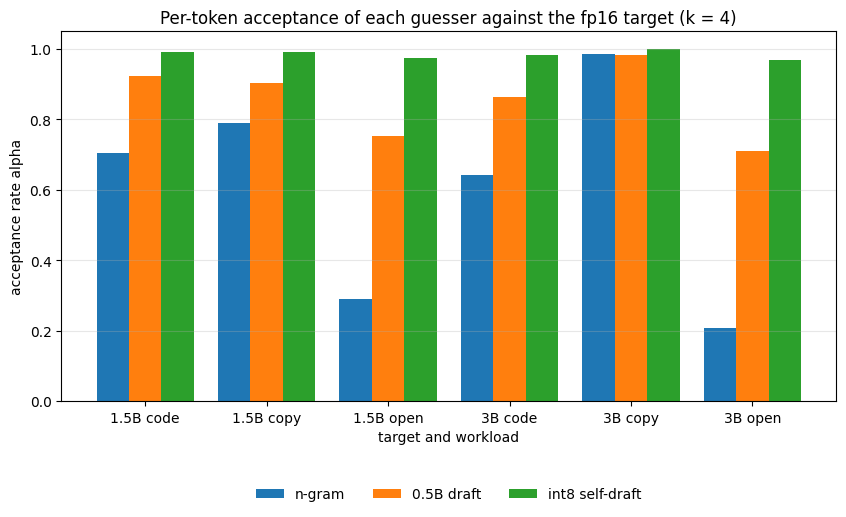

In [23]:
piv = acc_df.pivot_table(index=["target", "workload"], columns="proposer", values="alpha")
piv["self-draft minus 0.5B draft"] = piv["int8 self-draft"] - piv["0.5B draft"]
SELF_BETTER = bool((piv["self-draft minus 0.5B draft"] > 0).all())
print(piv.round(3).to_string())
print("\nThe int8 self-draft is accepted more often than the 0.5B draft on every workload and target:" if SELF_BETTER else
      "\nThe int8 self-draft is NOT accepted more often than the 0.5B draft everywhere (see the column above).")
labels = [f"{t} {w}" for t, w in piv.index]
grouped_bar(labels, {p: list(piv[p]) for p in ("n-gram", "0.5B draft", "int8 self-draft")},
            "Per-token acceptance of each guesser against the fp16 target (k = 4)", "acceptance rate alpha", xlabel="target and workload",
            figsize=(10, 4.8), save="stage9_acceptance")

**How to read it.**

- **`alpha` is the number that matters here.** The speedup column of this sweep is not: the int8 self-draft ran through the slow eager dequantize, so its time says nothing about the kernel. Compare `alpha` and tokens per round across the three guessers.
- **The self-draft against the 0.5B draft.** The column `self-draft minus 0.5B draft` is positive where the copy of the model guesses better. A small or negative value on `open` text would mean that rounding the weights changes the model's choices there about as much as being a different model does, and the idea would be dead before any kernel.
- **Why `alpha` and not the agreement of Stage 8.** Stage 8's top-1 agreement was measured with the *text* fed in (teacher forcing). Here the draft's own guesses are fed back, so one wrong guess ends the round. `alpha` is the quantity speculation actually pays for.
- **`exact`.** Outputs equal plain greedy up to fp16 near-ties (Stage 6); section 4 measures those ties instead of assuming them.

---
## 2. The kernel

**Goal:** a matrix-vector product that reads int8 weights as bytes, check that it is right, tune it, and find out whether it beats the fp16 layer.

**Concept.** A decode step multiplies a vector by each weight matrix once, so it is limited by how fast the weights stream from memory. Stage 8's eager dequantize writes and re-reads a full fp16 copy (five bytes per weight against fp16's two), the compiled one did not fuse the conversion well, and the built-in int8 matmul was slow on this GPU. The fix is to do the conversion where the bytes arrive: load a tile of int8 weights, convert it to fp16 in registers, multiply, accumulate in fp32, apply the scale to the fp32 result. Traffic is one byte per weight.

Two kernels, in `minivllm/int8_kernel.py`:

- **`gemv1`**, for one token. A program owns `BLOCK_N` output rows and walks along `K` in chunks of `BLOCK_K`: it loads a `[BLOCK_N, BLOCK_K]` tile of int8, multiplies it by the matching slice of `x` on the FMA units, and keeps the products in a `[BLOCK_N, BLOCK_K]` accumulator that is reduced once at the end.
- **`dot`**, for a block of tokens (a decode batch, a checking block of `k + 1` tokens, a prompt). The rows of `x` are tiled by `BLOCK_M` (16, as `tl.dot` needs, and 64 beyond), the int8 tile is converted and a tensor-core dot accumulates in fp32. It does more arithmetic than a vector needs (a one-row input is padded to 16), but the weights are read once, and a decode step does not have arithmetic to spare *in memory terms*.

The block sizes are compile-time constants. They are chosen by a **tuning run**: for each real layer shape, a small grid of `BLOCK_N`, `BLOCK_K` and `num_warps` is timed and the fastest is kept in a table. The table is explicit, not Triton's autotuner, because the autotuner launches candidates and so cannot run inside CUDA-graph capture, which the draft step uses. A shape that was not tuned falls back to a heuristic that sizes the tile so every multiprocessor of the T4 gets work.

Triton is an optional dependency of the package: `qlinear` imports the kernel only for a `QWeight` whose path is `"triton"`. On a machine without a GPU the same kernels run in Triton's interpreter, which is how the unit tests check them.

**The gate.** Correctness first, with a control that must fail (a wrong scale). Then one linear layer at the real Qwen2.5 shapes, at 1 token, 5 tokens (a checking block) and 16 tokens, against the measured copy bandwidth and against the fp16 layer and the three ways of Stage 8, run again in this session.

> **Predict** (written before running anything below).
>
> - **Correct:** the kernel agrees with the dequantize path to within fp16 output rounding (a relative error of order 1e-4 to 1e-3), at every shape and batch size, and a wrong scale is off by far more.
> - **Faster than fp16 on the large layers:** if the kernel reaches 55% to 75% of the copy bandwidth on the large layers (the fp16 layer reached 76% to 84% in Stage 8), the int8 layer should be roughly 1.3 to 1.8 times faster than the fp16 layer at one token. The ceiling is two times, at equal bandwidth efficiency. I do not know whether Triton reaches that on a T4, which has no asynchronous copies and a small memory system, so this is a gate and not a plan.
> - **Not faster on the small `k/v` layer**, where the fp16 layer is launch-bound (Stage 8): a layer that is one launch gains nothing from fewer bytes, and a Triton launch is slower than a cuBLAS launch, so it may lose.
> - **At 5 and 16 tokens** the tensor-core kernel should stay near the one-token result, because the weights are still read once; if it falls away, the padding or the tile shape is the limit.
> - The tuned block sizes should differ between shapes, with small tiles for the narrow layers.

In [24]:
# 1. tune the block sizes for every distinct shape of every model size (one token, and a checking block of five)
tune_table, tune_rows = tune_int8_kernel(ALL_SHAPES, ms=(1, 5), device=device, dtype=dtype, iters=10)
tune_df = pd.DataFrame(tune_rows)
tune_df["share_of_copy"] = tune_df.gbps / COPY_BW
tune_df[["layer", "out", "in", "batch", "cfg_variant", "cfg_BLOCK_N", "cfg_BLOCK_K", "cfg_num_warps", "median_ms", "gbps", "share_of_copy", "candidates", "failed"]].round(3)

,layer,out,in,batch,cfg_variant,cfg_BLOCK_N,cfg_BLOCK_K,cfg_num_warps,median_ms,gbps,share_of_copy,candidates,failed
0,mlp gate/up,4864,896,1,gemv1,8,256,2,0.074,58.884,0.242,48,0
1,mlp gate/up,4864,896,5,dot,128,64,4,0.627,6.963,0.029,12,0
2,mlp down,896,4864,1,gemv1,8,128,8,0.070,61.858,0.254,48,0
3,mlp down,896,4864,5,dot,64,64,4,0.498,8.749,0.036,12,0
4,attn q/o,896,896,1,gemv1,8,512,8,0.065,12.397,0.051,48,0
5,attn q/o,896,896,5,dot,64,64,4,0.114,7.048,0.029,12,0
6,attn k/v,128,896,1,gemv1,2,512,2,0.064,1.798,0.007,48,0
7,attn k/v,128,896,5,dot,32,64,4,0.103,1.117,0.005,12,0
8,lm_head,151936,896,1,gemv1,16,512,4,0.575,237.136,0.976,48,0
9,lm_head,151936,896,5,dot,128,64,4,6.681,20.423,0.084,12,0


In [25]:
# 2. correctness with the tuned table, and a control that must fail: a wrong scale
CHECK = []
for name, n, k in ALL_SHAPES:
    w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
    qw = quantize_weight(w)
    ref_w = dequantize(qw).float()
    for m in (1, 5, 16, 37):
        x = torch.randn(m, k, device=device, dtype=dtype)
        ref = x.float() @ ref_w.T
        rel = lambda y: ((y.float() - ref).abs().max() / ref.abs().max()).item()
        CHECK.append({"layer": name, "out": n, "in": k, "batch": m, "rel_err": rel(int8_matmul(x, qw.q, qw.scale)),
                      "wrong_scale_rel_err": rel(int8_matmul(x, qw.q, torch.roll(qw.scale, 1)))})
    del w, qw, ref_w
    gc.collect(); torch.cuda.empty_cache()
check_df = pd.DataFrame(CHECK)
print(f"largest relative error of the kernel {check_df.rel_err.max():.2e}; smallest error with a wrong scale {check_df.wrong_scale_rel_err.min():.2e}")
assert check_df.rel_err.max() < 2e-3, "the kernel does not agree with the dequantize path"
assert check_df.wrong_scale_rel_err.min() > 0.05, "a wrong scale was not caught, so the correctness check cannot be trusted"

largest relative error of the kernel 4.94e-04; smallest error with a wrong scale 1.45e-01


In [26]:
# 3. the gate: one layer, each way, against the fp16 layer
gate_rows = linear_gate(GATE_SHAPES, batches=GATE_BATCHES, device=device, dtype=dtype, iters=ITERS, compile_paths=True, include_triton=True)
gate_df = pd.DataFrame(gate_rows)
gate_df["share_of_copy"] = gate_df.gbps / COPY_BW
gate_df[["layer", "batch", "variant", "ok", "median_ms", "spread", "gbps", "share_of_copy", "vs_fp", "rel_err", "error"]].round(3)

W1013 20:50:57.072000 117 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


,layer,batch,variant,ok,median_ms,spread,gbps,share_of_copy,vs_fp,rel_err,error
0,mlp gate/up,1,fp,True,0.211,0.130,130.665,0.538,1.000,NaN,None
1,mlp gate/up,1,"int8 dequant, eager",True,0.503,0.110,27.398,0.113,0.419,NaN,None
2,mlp gate/up,1,"int8 dequant, compiled",True,0.458,0.045,30.118,0.124,0.460,NaN,None
3,mlp gate/up,1,int8 intpack,True,1.675,0.049,8.228,0.034,0.126,NaN,None
4,mlp gate/up,1,int8 triton,True,0.175,0.431,78.728,0.324,1.203,0.001,None
...,...,...,...,...,...,...,...,...,...,...,...
70,lm_head,16,fp,True,2.041,0.008,228.739,0.941,1.000,NaN,None
71,lm_head,16,"int8 dequant, eager",True,7.983,0.055,29.273,0.120,0.256,NaN,None
72,lm_head,16,"int8 dequant, compiled",True,5.218,0.020,44.787,0.184,0.391,NaN,None
73,lm_head,16,int8 intpack,True,66.401,0.001,3.519,0.014,0.031,NaN,None


In [27]:
def pick(df, layer, variant, col, batch=1):
    r = df[(df.layer == layer) & (df.variant == variant) & (df.batch == batch)]
    v = r[col].iloc[0] if len(r) else None
    return float("nan") if v is None or v != v else float(v)

LAYERS = list(dict.fromkeys(gate_df[gate_df.batch == 1].layer))
WAYS = ["int8 dequant, eager", "int8 dequant, compiled", "int8 intpack", "int8 triton"]

big = gate_df[gate_df.layer.isin(LARGE) & gate_df.ok & (gate_df.variant == "int8 triton")]
by_batch = big.groupby("batch").vs_fp.mean()
print("the Triton kernel against the fp16 layer on the large layers, mean by batch (above 1 is faster):")
print(by_batch.round(2).to_string() if len(by_batch) else "  the kernel did not run")
for _, r in gate_df[~gate_df.ok].iterrows():
    print(f"  not available: {r.layer} batch {r.batch} {r.variant}: {r.error}")
best_ratio = float(by_batch.get(1, float("nan")))
KERNEL_GO = best_ratio == best_ratio and best_ratio > 1.1
if KERNEL_GO:
    print(f"\nGATE: GO. The kernel reads int8 weights faster than the fp16 layer reads its own: {best_ratio:.2f}x on the large layers at one token. Continue.")
else:
    print("\nGATE: NO-GO on this GPU: the kernel is not more than 10% faster than the fp16 layer on the large layers at one token. "
          "The rest of the notebook still measures what it gives, and explains the loss.")

the Triton kernel against the fp16 layer on the large layers, mean by batch (above 1 is faster):
batch
1     1.70
5     0.13
16    0.13

GATE: GO. The kernel reads int8 weights faster than the fp16 layer reads its own: 1.70x on the large layers at one token. Continue.


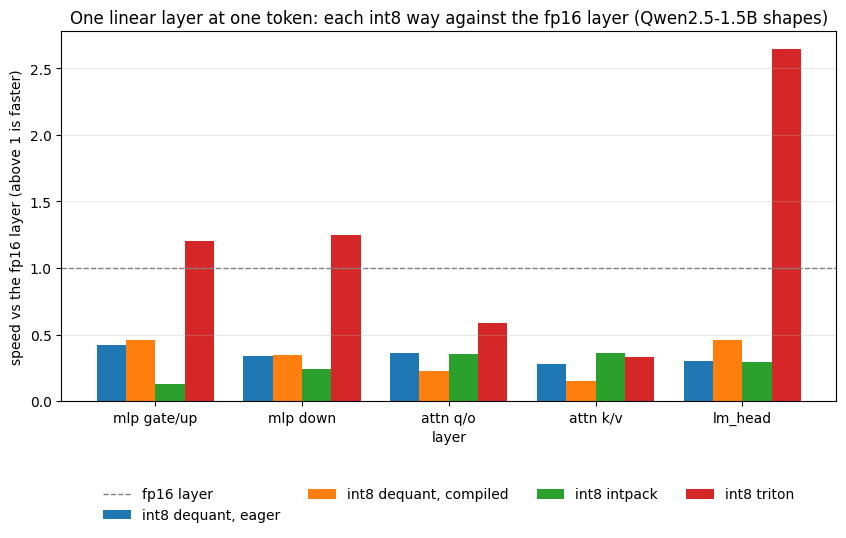

In [28]:
grouped_bar(LAYERS, {w: [pick(gate_df, l, w, "vs_fp") for l in LAYERS] for w in WAYS},
            f"One linear layer at one token: each int8 way against the fp16 layer ({MODEL_IDS[GATE_SIZE].split('/')[-1]} shapes)",
            "speed vs the fp16 layer (above 1 is faster)", hline=1.0, hline_label="fp16 layer", xlabel="layer", figsize=(10, 4.8), save="stage9_gate_speed")

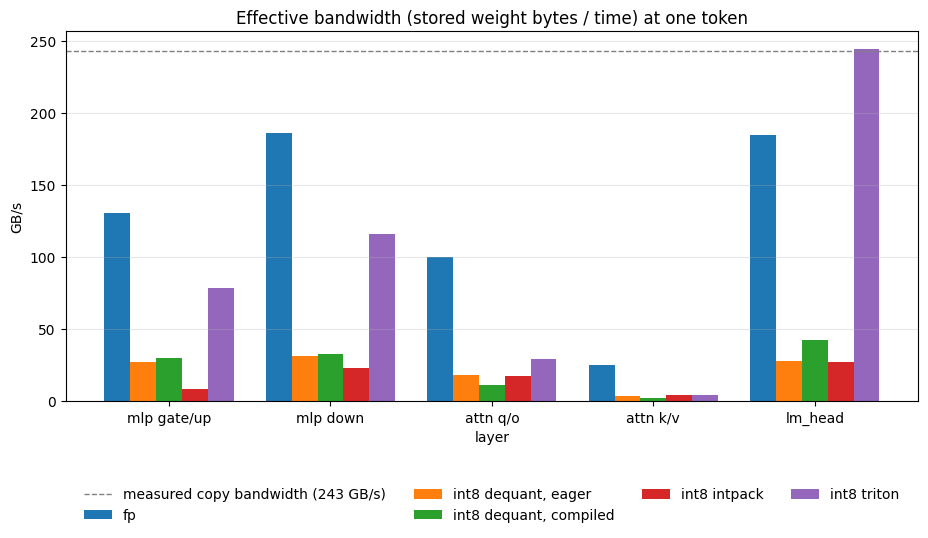

In [29]:
grouped_bar(LAYERS, {w: [pick(gate_df, l, w, "gbps") for l in LAYERS] for w in ["fp"] + WAYS},
            "Effective bandwidth (stored weight bytes / time) at one token", "GB/s", hline=COPY_BW, hline_label=f"measured copy bandwidth ({COPY_BW:.0f} GB/s)",
            xlabel="layer", figsize=(11, 4.8), save="stage9_gate_bandwidth")

**How to read it.**

- **The tuning table.** `share_of_copy` is the bandwidth the best configuration reaches for the stored bytes. The large layers should be far above the small ones. If the best configuration of a large layer sits at the edge of the grid (the largest `BLOCK_K`, or the most warps), the grid was too small and the kernel could go faster. `failed` counts candidates that did not compile or launch.
- **The correctness check** is a precondition, not a result: the notebook stops if the kernel disagrees with the dequantize path or if a wrong scale is not caught. The error column is the largest difference relative to the largest output, so a value of order 1e-4 is fp16 rounding of the output.
- **The gate.** `vs_fp` above one means the way is faster than the fp16 layer. Compare the Triton row with the three Stage 8 ways in the same run. A ratio near two means the layer is fully bandwidth-bound at one byte per weight; a ratio between one and two means some of the time is not weight traffic.
- **Batch 5 and 16.** These use the tensor-core kernel. The weights are still read once, so a kernel that keeps its ratio there is bandwidth-bound and one that loses it is limited by the conversion or the tile shape.
- **The verdict is about one layer.** A step also has norms, attention, the KV cache and launches (Triton launches are slower than cuBLAS ones). Section 3 measures the step.

---
## 3. The decode step

**Goal:** measure what the kernel does to a whole decode step, in eager mode and in a CUDA graph, and check that it did not change what the model computes.

**Setup.** As in Stage 8: a step is one token for each of `B` sequences on top of `CTX` cached tokens, argmax included, the median of `ITERS` repeated steps with the spread, against the **floor** (bytes read per token over the measured copy bandwidth). New here:

- the **graph** mode, the single-token step captured in a CUDA graph and replayed (`DraftModel`'s step), which removes the launch cost that Triton makes larger in eager mode;
- the **checking pass**: the time of feeding 5 tokens against feeding 1, which is the `v` of the cost model (speculation needs it near one);
- an attempt at `torch.compile` for the int8 model, which may or may not trace a hand-written Triton kernel; a failure is reported.

**Accuracy** is unchanged by construction (the same int8 weights as Stage 8), but it is checked: the logit error and perplexity of the Triton path against fp16 and against the dequantize path.

> **Predict** (written before running anything below).
>
> - **Accuracy:** the Triton path has the same perplexity as the dequantize path to within fp16 noise, and both are within about half a percent of fp16 (Stage 8).
> - **Eager step, 3B:** if the gate is a go, the int8 step is faster than the fp16 step, by up to about 1.5 times (the fp16 step is mostly bandwidth, so halving the bytes helps; Triton's launch cost keeps it from the 2 times ceiling).
> - **Eager step, 1.5B and 0.5B:** a smaller gain at 1.5B (more of the step is launches and other work), and about none at 0.5B, whose step is mostly launches (Stages 2, 7 and 8).
> - **Graph mode:** the int8 step falls to roughly the bandwidth part of the step, so the int8 graph step is faster than the fp16 graph step at 1.5B and 3B and about equal at 0.5B.
> - **The checking pass:** feeding 5 tokens costs only a little more than feeding 1 for both weight formats; for int8 it should not be worse than for fp16.
> - **No step reaches its floor.**

In [30]:
ACC_L, ACC_P = [], []
CORPUS = [tok(t).input_ids for t in corpus()]


def all_logits(m):
    return torch.cat([m.forward(torch.tensor([ids], device=device), all_logits=True)[0].float().cpu() for ids in CORPUS])


for size in ACC_SIZES:
    fp, _ = load_model(size)
    ref_logits = all_logits(fp)
    ACC_P.append({"model": size, "variant": "fp16", "ppl": perplexity(fp, CORPUS)[0]})
    for vname, path in (("int8 dequant", "dequant"), ("int8 triton", "triton")):
        qm = quantize_model(fp, path=path)
        lg = all_logits(qm)
        ACC_L.append({"model": size, "variant": vname, **logit_error(ref_logits, lg)})
        ACC_P.append({"model": size, "variant": vname, "ppl": perplexity(qm, CORPUS)[0]})
        del qm, lg
        gc.collect(); torch.cuda.empty_cache()
    del fp, ref_logits
    gc.collect(); torch.cuda.empty_cache()
    print(f"{size} done")
logits_df, ppl_df = pd.DataFrame(ACC_L), pd.DataFrame(ACC_P)
print(ppl_df.round(4).to_string(index=False))
logits_df.round(4)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

0.5B done


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

1.5B done
model      variant    ppl
 0.5B         fp16 5.1163
 0.5B int8 dequant 5.1362
 0.5B  int8 triton 5.1402
 1.5B         fp16 4.4649
 1.5B int8 dequant 4.4632
 1.5B  int8 triton 4.4626


,model,variant,max_abs,mean_abs,kl,top1
0,0.5B,int8 dequant,6.5469,0.1078,0.0042,0.9762
1,0.5B,int8 triton,6.7090,0.1077,0.0042,0.9802
2,1.5B,int8 dequant,4.2617,0.0748,0.0018,0.9802
3,1.5B,int8 triton,4.2480,0.0748,0.0018,0.9828


In [31]:
SPEED, CHECK_COST, WARMUP_S = [], [], {}


def speed_row(size, variant, mode, batch, st, bytes_read, ok=True, error=None):
    floor_ms = 1000 * bytes_read / (COPY_BW * 1e9)
    row = {"model": size, "variant": variant, "mode": mode, "batch": batch, "ok": ok, "error": error, "bytes_read": bytes_read, "floor_ms": floor_ms}
    if st is not None:
        row.update(st, share=floor_ms / st["median_ms"])
    return row


def time_model(size, vname, m, compile_it):
    # eager steps at every batch size, the single-token step in a CUDA graph, the cost of a 5-token checking pass, and an attempt at torch.compile
    nbytes = weight_bytes_read(m)
    for b in EAGER_BATCHES:
        SPEED.append(speed_row(size, vname, "eager", b, decode_step_stats(m, b, CTX, iters=ITERS), nbytes))
    d = DraftModel(m, 512, mode="graph")                                   # captures the single-token step
    ms = d.time_step(CTX)
    SPEED.append(speed_row(size, vname, "graph", 1, {"median_ms": ms, "spread": None}, nbytes, ok=d.mode == "graph", error=d.graph_error))
    del d
    for r in verify_cost(m, [1], [1, 5], CTX):
        CHECK_COST.append({"model": size, "variant": vname, **r})
    if compile_it:
        fwd = None
        try:
            fwd = compile_forward(m)
            t0 = time.perf_counter()
            decode_step_stats(m, 1, CTX, forward=fwd, iters=1, warmup=1)       # the first call compiles
            WARMUP_S[f"{size} {vname}"] = time.perf_counter() - t0
            SPEED.append(speed_row(size, vname, "compiled", 1, decode_step_stats(m, 1, CTX, forward=fwd, iters=ITERS), nbytes))
        except Exception as e:                                                 # a compile that fails is a result
            SPEED.append(speed_row(size, vname, "compiled", 1, None, nbytes, ok=False, error=f"{type(e).__name__}: {str(e)[:140]}"))
        del fwd
        from torch import _dynamo
        _dynamo.reset()
        gc.collect(); torch.cuda.empty_cache()


for size in SIZES:
    m16, _ = load_model(size)
    q = quantize_model(m16, path="triton")           # shares the embedding table and the norms; the int8 matrices are new
    print(f"{size}: fp16 and int8 loaded, {gib():.2f} GiB in use")
    time_model(size, "fp16", m16, True)
    del m16                                          # not needed again: free the fp16 matrices before the int8 runs
    gc.collect(); torch.cuda.empty_cache()
    time_model(size, "int8 triton", q, True)
    print(f"{size} done")
    del q
    gc.collect(); torch.cuda.empty_cache()

speed_df, check_cost_df = pd.DataFrame(SPEED), pd.DataFrame(CHECK_COST)
speed_df[["model", "variant", "mode", "batch", "ok", "median_ms", "spread", "floor_ms", "share", "error"]].round(3)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

0.5B: fp16 and int8 loaded, 1.42 GiB in use
0.5B done


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

1.5B: fp16 and int8 loaded, 4.37 GiB in use
1.5B done


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

3B: fp16 and int8 loaded, 8.78 GiB in use
3B done


,model,variant,mode,batch,ok,median_ms,spread,floor_ms,share,error
0,0.5B,fp16,eager,1,True,22.255,0.067,4.065,0.183,None
1,0.5B,fp16,eager,4,True,22.621,0.054,4.065,0.180,None
2,0.5B,fp16,eager,16,True,24.588,0.251,4.065,0.165,None
3,0.5B,fp16,graph,1,True,9.345,NaN,4.065,0.435,None
4,0.5B,fp16,compiled,1,True,10.310,0.053,4.065,0.394,None
5,0.5B,int8 triton,eager,1,True,32.326,0.017,2.037,0.063,None
6,0.5B,int8 triton,eager,4,True,40.431,0.023,2.037,0.050,None
7,0.5B,int8 triton,eager,16,True,40.217,0.007,2.037,0.051,None
8,0.5B,int8 triton,graph,1,True,6.493,NaN,2.037,0.314,None
9,0.5B,int8 triton,compiled,1,True,7.921,0.036,2.037,0.257,None


In [32]:
check_cost_df[["model", "variant", "tokens_per_seq", "ms", "rel_to_one_token", "ms_per_token"]].round(3)

,model,variant,tokens_per_seq,ms,rel_to_one_token,ms_per_token
0,0.5B,fp16,1,22.117,1.000,22.117
1,0.5B,fp16,5,25.028,1.132,5.006
2,0.5B,int8 triton,1,33.696,1.000,33.696
3,0.5B,int8 triton,5,37.256,1.106,7.451
4,1.5B,fp16,1,28.859,1.000,28.859
5,1.5B,fp16,5,30.387,1.053,6.077
6,1.5B,int8 triton,1,38.581,1.000,38.581
7,1.5B,int8 triton,5,90.811,2.354,18.162
8,3B,fp16,1,35.138,1.000,35.138
9,3B,fp16,5,39.810,1.133,7.962


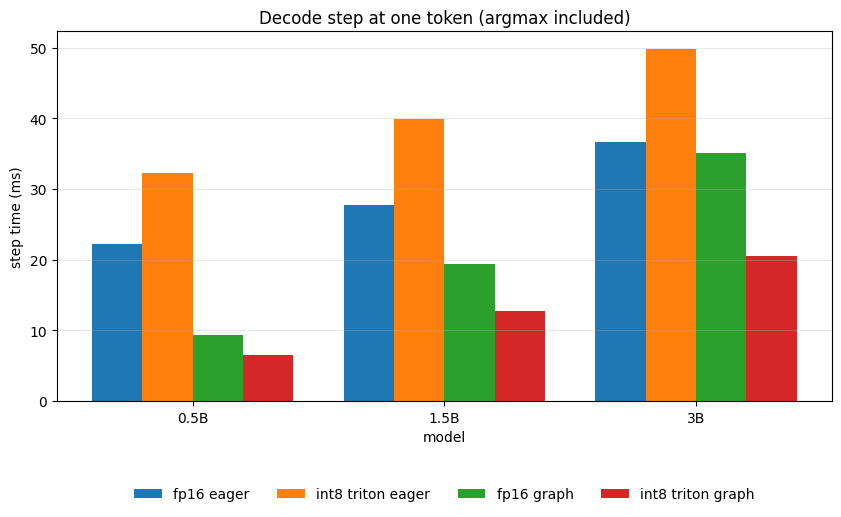

In [33]:
b1s = speed_df[(speed_df.batch == 1) & speed_df.ok]
def step(size, variant, mode, col="median_ms"):
    r = b1s[(b1s.model == size) & (b1s.variant == variant) & (b1s["mode"] == mode)]
    return float(r[col].iloc[0]) if len(r) else float("nan")

SERIES = [("fp16", "eager"), ("int8 triton", "eager"), ("fp16", "graph"), ("int8 triton", "graph")]
grouped_bar(SIZES, {f"{v} {m}": [step(s, v, m) for s in SIZES] for v, m in SERIES}, "Decode step at one token (argmax included)",
            "step time (ms)", xlabel="model", figsize=(10, 4.8), save="stage9_step_time")

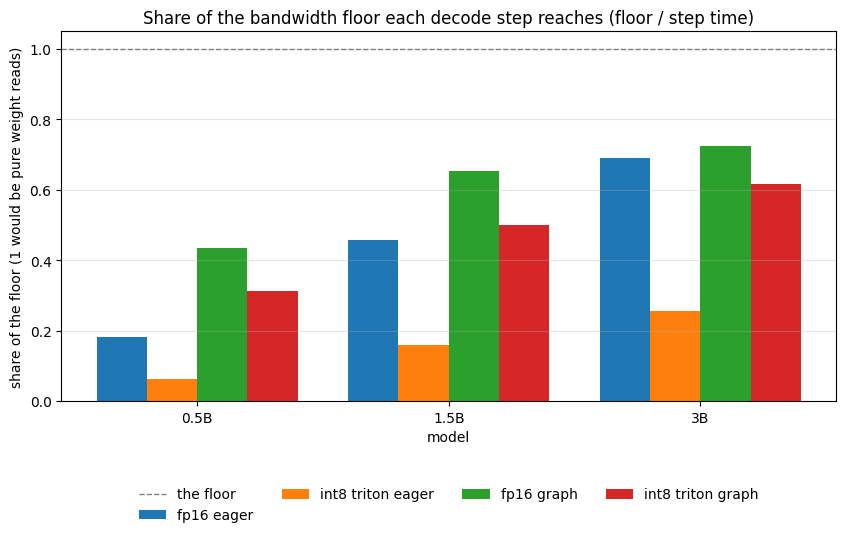

,model,mode,fp16 step (ms),int8 step (ms),fp16 / int8
0,0.5B,eager,22.255,32.326,0.688
1,0.5B,graph,9.345,6.493,1.439
2,0.5B,compiled,10.310,7.921,1.302
3,1.5B,eager,27.783,39.891,0.696
4,1.5B,graph,19.426,12.724,1.527
5,1.5B,compiled,18.085,11.593,1.560
6,3B,eager,36.718,49.819,0.737
7,3B,graph,35.039,20.594,1.701
8,3B,compiled,31.967,17.978,1.778


In [34]:
grouped_bar(SIZES, {f"{v} {m}": [step(s, v, m, "share") for s in SIZES] for v, m in SERIES},
            "Share of the bandwidth floor each decode step reaches (floor / step time)", "share of the floor (1 would be pure weight reads)",
            xlabel="model", hline=1.0, hline_label="the floor", figsize=(10, 4.8), save="stage9_bandwidth_share")
assert (speed_df[speed_df.ok].share.dropna() < 1.0).all(), "a decode step beat its own bandwidth floor: the byte count or the bandwidth is wrong"
ratio_rows = []
for size in SIZES:
    for mode in ("eager", "graph", "compiled"):
        a, b = step(size, "fp16", mode), step(size, "int8 triton", mode)
        ratio_rows.append({"model": size, "mode": mode, "fp16 step (ms)": a, "int8 step (ms)": b, "fp16 / int8": a / b if a == a and b == b else float("nan")})
pd.DataFrame(ratio_rows).round(3)

**How to read it.**

- **`fp16 / int8` in the last table** above one means the int8 step is faster. Read it by mode and by size: the prediction was a gain that grows with the model and is largest where the step is mostly weight reads (3B), with a graph removing the launch cost that eager Triton adds.
- **The share of the floor.** The int8 floor is half the fp16 floor, so reaching the same share as fp16 would halve the step. The gap between the two shares is what the kernel and the rest of the step still cost. A step far below its floor is limited by something other than weight reads, which no weight format changes.
- **The `graph` rows** are the single-token step replayed from a CUDA graph (the draft's step). The time there has no spread (it is a median of replays). A row marked not ok means the capture failed and the table says why.
- **`compiled`.** If `torch.compile` could not trace the kernel, the row says why and the step-level answer for this build is the eager and graph rows.
- **The checking pass.** `rel_to_one_token` is the time of feeding 5 tokens over feeding 1, the `v` of the cost model. Near one means the extra tokens are almost free, which speculation needs; compare the two weight formats.
- **Accuracy.** The Triton and dequantize rows should agree with each other to within fp16 noise; both should be as close to fp16 as in Stage 8.

---
## 4. Speculation with it

**Goal:** answer the two questions that motivated the kernel. Do an int8 target and speculation multiply? And can the int8 copy be a draft that beats the n-gram lookup?

**Concept.** For a round of speculation with `k` guesses, per-token acceptance `alpha` and cost ratio `c` (a guess's cost over a plain target step) and `v` (the checking pass over a plain step), Stage 7's cost model predicts

```
tokens per round  =  (1 - alpha^(k+1)) / (1 - alpha)
speedup           =  tokens per round / (k * c + v)
```

**Part (a): an int8 target with the n-gram lookup.** Speculation cuts the number of weight reads per token; int8 cuts the bytes per read. If a step is bandwidth-bound the two should multiply. The measurement: the speedup of the int8 target with the n-gram lookup over the *fp16 plain* decode, against the speedups of each alone.

**Part (b): the int8 copy as the draft of the fp16 target.** Same cost as a 0.5B draft in a CUDA graph if the kernel is as fast as hoped, and, from section 1, far better guesses. The measurement: `c` of each guesser (in graph mode and eager), then the speedup over fp16 plain decoding for the n-gram lookup, the 0.5B draft and the int8 self-draft, against the cost model.

Every speedup divides by a plain baseline that is **timed several times and the median taken** (`baseline_runs`), the weakness of Stage 7's single timing. The two targets are loaded one after the other, with the 0.5B draft and the int8 copy next to the fp16 target.

For reference, what the cost model says before any measurement (nothing here is measured):

In [35]:
grid = pd.DataFrame({f"c = {c}": [expected_tokens_per_round(a, 4) / (4 * c + 1.1) for a in (0.7, 0.8, 0.9, 0.95, 0.98)] for c in (0.3, 0.4, 0.5, 0.7, 1.0)},
                    index=[f"alpha = {a}" for a in (0.7, 0.8, 0.9, 0.95, 0.98)])
grid.round(2)

,c = 0.3,c = 0.4,c = 0.5,c = 0.7,c = 1.0
alpha = 0.7,1.21,1.03,0.89,0.71,0.54
alpha = 0.8,1.46,1.25,1.08,0.86,0.66
alpha = 0.9,1.78,1.52,1.32,1.05,0.80
alpha = 0.95,1.97,1.68,1.46,1.16,0.89
alpha = 0.98,2.09,1.78,1.55,1.23,0.94


> **Predict** (written before running anything below).
>
> - **(a) The gains multiply, roughly.** The int8 target with the n-gram lookup is faster than the fp16 target with the n-gram lookup by about the factor that int8 gives a plain step (section 3), on `copy` and `code`, where the n-gram lookup wins. On `open` text, where the lookup gains little, the int8 target's plain speed is most of the gain. If the kernel is a no-go this will show as a loss.
> - **(b) `c` of the int8 self-draft in graph mode** is about the int8 graph step over the fp16 target's eager step, which should be below the 0.5B draft's `c` for the 1.5B target if the int8 graph step is faster than the fp16 0.5B step (it reads the weights of a model three times larger, at half the bytes, so I do **not** expect that: probably above). Its `alpha` is higher, so the question is which wins.
> - **(b) Speedup:** with `alpha` near 0.9 or above (section 1) and `c` around 0.5, the cost-model grid above gives a speedup of about 1.5 to 2 times at `k = 4`. I expect the int8 self-draft to beat the 0.5B draft on every workload, and to beat the n-gram lookup on `open` text. Whether it beats the lookup on `copy` and `code` (where the lookup's guesses are free) I expect not.
> - **The cost model** should predict the measured speedup to within about a quarter once given the measured cost of a guess (Stage 7), and overstate the graph draft's gain because the first guess of every round is an eager pass.
> - **Exactness:** outputs equal plain greedy up to fp16 near-ties, and any difference has a small logit gap (the check of Stage 8, with the fp16 target as control).

In [36]:
SPEC_ROWS, C_ROWS, EXACT_ROWS = [], [], []
NEAR_TIE = 0.5      # the largest logit gap between two tokens that still counts as an fp16 tie


def near_tie_rows(tsize, setup, tm, make_prop):
    # first prompt of each workload, 32 tokens: speculative output against the same model's plain greedy output, with the logit gap at a difference
    out = []
    for name in ("copy", "code", "open"):
        ids = PROMPT_IDS[name][0]
        plain = generate_cached(tm, torch.tensor([ids], device=device), 32)[0][0, len(ids):].tolist()
        spec, _ = generate_speculative(tm, ids, 32, k=4, proposer=make_prop())
        i = first_mismatch(plain, spec)
        gap = None
        if i is not None:
            logits = tm.forward(torch.tensor([ids + plain[:i]], device=device))[0].float()
            gap = (logits[plain[i]] - logits[spec[i]]).abs().item()
        out.append({"target": tsize, "setup": setup, "workload": name, "first_mismatch": i, "logit_gap": gap})
    return out


for tsize in TARGETS:
    t16, _ = load_model(tsize)
    t8 = quantize_model(t16, path="triton")                 # the int8 copy: the int8 target of part (a) and the self-draft of part (b)
    d05, _ = load_model("0.5B")
    print(f"{tsize}: target, int8 copy and 0.5B draft loaded, {gib():.2f} GiB in use")
    t_ms = step_time_ms(t16, CTX)
    for label, dm, mode in (("0.5B draft", d05, "graph"), ("int8 self-draft", t8, "graph"), ("int8 self-draft", t8, "eager")):
        d = DraftModel(dm, 512, mode=mode)
        ms = d.time_step(CTX)
        C_ROWS.append({"target": tsize, "draft": label, "mode": d.mode, "requested": mode, "graph_error": d.graph_error if mode == "graph" else None,
                       "draft_ms": ms, "target_ms": t_ms, "c": ms / t_ms})
        del d
    props = {"n-gram": PromptLookup(), "0.5B draft (graph)": DraftModel(d05, 512, "graph"), "int8 self-draft (graph)": DraftModel(t8, 512, "graph"),
             "int8 self-draft (eager)": DraftModel(t8, 512, "eager")}
    SPEC_ROWS += [{"target": tsize, "weights": "fp16", **r} for r in sweep_proposers(t16, PROMPT_IDS, MAX_NEW, KS, props, verbose=False, baseline_runs=BASELINE_RUNS)]
    print(f"  {tsize}: fp16 target done")
    SPEC_ROWS += [{"target": tsize, "weights": "int8 triton", **r} for r in
                  sweep_proposers(t8, PROMPT_IDS, MAX_NEW, KS, {"n-gram": PromptLookup()}, verbose=False, baseline_runs=BASELINE_RUNS)]
    print(f"  {tsize}: int8 target done")
    EXACT_ROWS += near_tie_rows(tsize, "fp16 target, int8 self-draft", t16, lambda: DraftModel(t8, 512, "graph"))
    EXACT_ROWS += near_tie_rows(tsize, "int8 target, n-gram", t8, PromptLookup)
    del props, t16, t8, d05
    gc.collect(); torch.cuda.empty_cache()

c_df, exact_df = pd.DataFrame(C_ROWS), pd.DataFrame(EXACT_ROWS)
SPEC_EXACT = all(r["first_mismatch"] is None or r["logit_gap"] < NEAR_TIE for r in EXACT_ROWS)
c_df[["target", "draft", "mode", "draft_ms", "target_ms", "c", "graph_error"]].round(3)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

1.5B: target, int8 copy and 0.5B draft loaded, 5.32 GiB in use
  1.5B: fp16 target done
  1.5B: int8 target done


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

3B: target, int8 copy and 0.5B draft loaded, 11.61 GiB in use
  3B: fp16 target done
  3B: int8 target done


,target,draft,mode,draft_ms,target_ms,c,graph_error
0,1.5B,0.5B draft,graph,9.384,28.155,0.333,None
1,1.5B,int8 self-draft,graph,12.362,28.155,0.439,None
2,1.5B,int8 self-draft,eager,38.754,28.155,1.376,None
3,3B,0.5B draft,graph,9.291,35.632,0.261,None
4,3B,int8 self-draft,graph,20.024,35.632,0.562,None
5,3B,int8 self-draft,eager,50.305,35.632,1.412,None


In [37]:
spec_df = pd.DataFrame(SPEC_ROWS)
# every speedup against the FP16 plain decoding of the same target and workload, and the cost model's prediction from this row's own numbers
plain16 = spec_df[(spec_df.weights == "fp16") & (spec_df.proposer == "plain")].set_index(["target", "workload"]).tok_s
plain_ms = spec_df[spec_df.proposer == "plain"].set_index(["target", "weights", "workload"]).target_ms
spec_df["vs_fp16_plain"] = [r.tok_s / plain16[(r.target, r.workload)] for r in spec_df.itertuples()]
spec_df["pred_x"] = [float("nan") if r.proposer == "plain" else r.expected_tokens * plain_ms[(r.target, r.weights, r.workload)] / (r.guess_ms + r.target_ms)
                     for r in spec_df.itertuples()]
spec_df["setup"] = spec_df.weights + " " + spec_df.proposer
view = spec_df[spec_df.proposer != "plain"][["target", "workload", "setup", "k", "alpha", "tokens_per_step", "guess_ms", "target_ms", "speedup_x", "vs_fp16_plain", "pred_x", "n_exact", "n_prompts"]]
view.round(2)

,target,workload,setup,k,alpha,tokens_per_step,guess_ms,target_ms,speedup_x,vs_fp16_plain,pred_x,n_exact,n_prompts
1,1.5B,copy,fp16 n-gram,4,0.79,2.48,0.03,29.17,2.30,2.30,3.13,3,3
2,1.5B,copy,fp16 n-gram,6,0.80,2.71,0.04,30.67,2.38,2.38,3.56,3,3
3,1.5B,copy,fp16 0.5B draft (graph),4,0.90,4.01,51.62,31.55,1.32,1.32,1.37,3,3
4,1.5B,copy,fp16 0.5B draft (graph),6,0.90,5.00,68.68,31.92,1.36,1.36,1.44,3,3
5,1.5B,copy,fp16 int8 self-draft (graph),4,0.99,4.83,202.86,31.92,0.57,0.57,0.58,3,3
6,1.5B,copy,fp16 int8 self-draft (graph),6,0.99,6.63,307.94,31.79,0.54,0.54,0.56,3,3
7,1.5B,copy,fp16 int8 self-draft (eager),4,0.99,4.83,281.59,31.05,0.43,0.43,0.43,3,3
8,1.5B,copy,fp16 int8 self-draft (eager),6,0.99,6.63,430.96,30.42,0.40,0.40,0.41,3,3
10,1.5B,code,fp16 n-gram,4,0.70,2.18,0.03,28.85,2.00,2.00,2.62,3,3
11,1.5B,code,fp16 n-gram,6,0.71,2.36,0.03,29.69,2.10,2.10,2.86,3,3


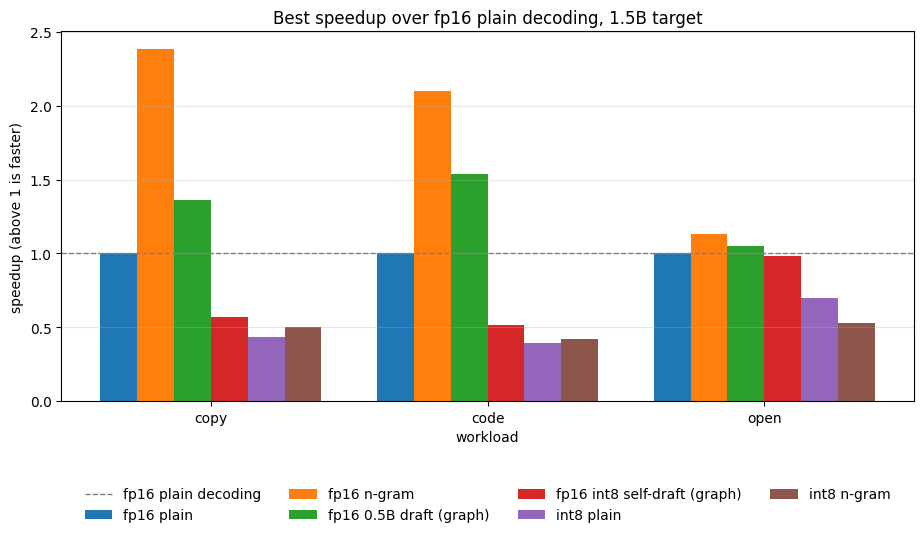

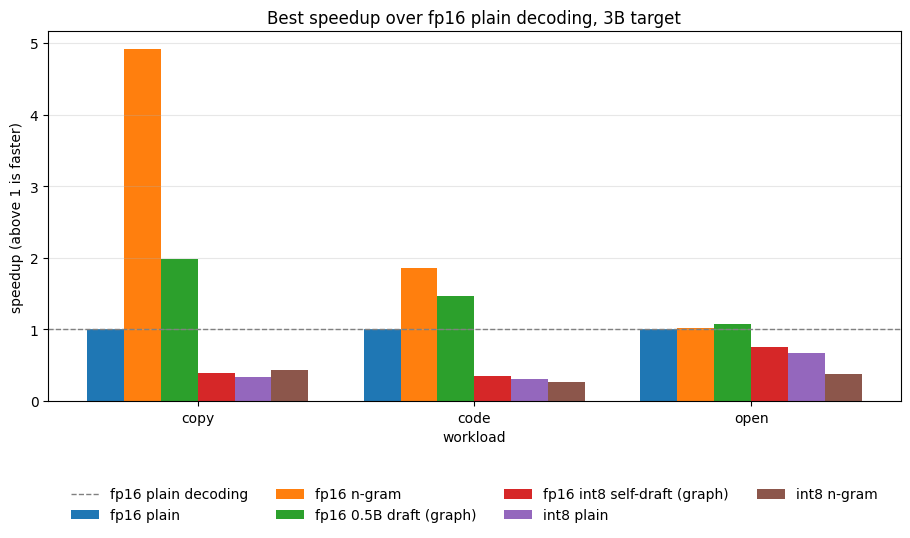

,target,workload,setup,k,vs_fp16_plain,alpha,tokens_per_step
0,1.5B,code,fp16 0.5B draft (graph),6,1.54,0.94,5.70
2,1.5B,code,fp16 int8 self-draft (graph),4,0.52,0.99,4.91
3,1.5B,code,fp16 n-gram,6,2.10,0.71,2.36
4,1.5B,code,fp16 plain,0,1.00,0.00,1.00
5,1.5B,code,int8 n-gram,6,0.42,0.69,2.34
6,1.5B,code,int8 plain,0,0.39,0.00,1.00
7,1.5B,copy,fp16 0.5B draft (graph),6,1.36,0.90,5.00
9,1.5B,copy,fp16 int8 self-draft (graph),4,0.57,0.99,4.83
10,1.5B,copy,fp16 n-gram,6,2.38,0.80,2.71
11,1.5B,copy,fp16 plain,0,1.00,0.00,1.00


In [38]:
idx = spec_df.groupby(["target", "workload", "setup"])["vs_fp16_plain"].idxmax()       # the best draft length of each setup
best = spec_df.loc[idx].reset_index(drop=True)
best["setup"] = best.setup.str.replace("int8 triton plain", "int8 plain").str.replace("int8 triton n-gram", "int8 n-gram")
ORDER = ["fp16 plain", "fp16 n-gram", "fp16 0.5B draft (graph)", "fp16 int8 self-draft (graph)", "int8 plain", "int8 n-gram"]
WL = ["copy", "code", "open"]
for tsize in TARGETS:
    b = best[best.target == tsize].set_index(["setup", "workload"]).vs_fp16_plain
    grouped_bar(WL, {s: [float(b.get((s, w), float("nan"))) for w in WL] for s in ORDER},
                f"Best speedup over fp16 plain decoding, {tsize} target", "speedup (above 1 is faster)", hline=1.0, hline_label="fp16 plain decoding",
                xlabel="workload", figsize=(11, 4.8), save=f"stage9_speedup_{tsize.replace('.', 'p').lower()}")
best[best.setup.isin(ORDER)][["target", "workload", "setup", "k", "vs_fp16_plain", "alpha", "tokens_per_step"]].round(2)

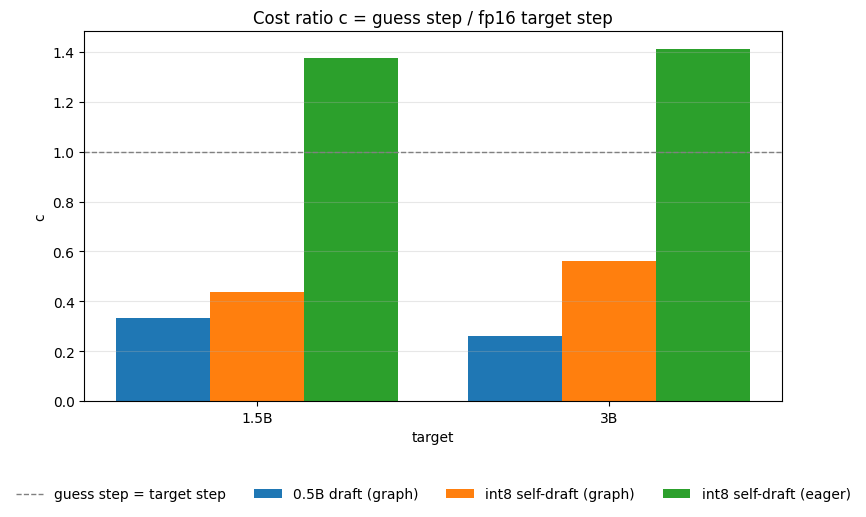

target                        setup workload  first_mismatch  logit_gap
  1.5B fp16 target, int8 self-draft     copy             NaN        NaN
  1.5B fp16 target, int8 self-draft     code             NaN        NaN
  1.5B fp16 target, int8 self-draft     open             NaN        NaN
  1.5B          int8 target, n-gram     copy             NaN        NaN
  1.5B          int8 target, n-gram     code             2.0      0.008
  1.5B          int8 target, n-gram     open             NaN        NaN
    3B fp16 target, int8 self-draft     copy             NaN        NaN
    3B fp16 target, int8 self-draft     code             NaN        NaN
    3B fp16 target, int8 self-draft     open             6.0      0.000
    3B          int8 target, n-gram     copy             NaN        NaN
    3B          int8 target, n-gram     code            28.0      0.000
    3B          int8 target, n-gram     open             NaN        NaN
every speculative difference is a near-tie: True


In [39]:
C_KINDS = [("0.5B draft", "graph"), ("int8 self-draft", "graph"), ("int8 self-draft", "eager")]
def c_of(t, d, m):
    r = c_df[(c_df.target == t) & (c_df.draft == d) & (c_df.requested == m)]
    return float(r.c.iloc[0]) if len(r) else float("nan")
grouped_bar(TARGETS, {f"{d} ({m})": [c_of(t, d, m) for t in TARGETS] for d, m in C_KINDS}, "Cost ratio c = guess step / fp16 target step", "c",
            hline=1.0, hline_label="guess step = target step", xlabel="target", figsize=(9, 4.8), save="stage9_cost_ratio")
print(exact_df.round(3).to_string(index=False))
print("every speculative difference is a near-tie:", SPEC_EXACT)
assert SPEC_EXACT, f"a speculative output differs from plain greedy where the two tokens are not nearly tied (logit gap of {NEAR_TIE} or more): that is not fp16 rounding"

**How to read it.**

- **Part (a), do the gains multiply?** In the best-speedup chart, compare `int8 plain` and `fp16 n-gram` with `int8 n-gram`, all against `fp16 plain`. If the int8 plain bar is above one, int8 helps a plain step; if `int8 n-gram` is about the product of the two, the gains compose. If `int8 plain` is below one the kernel is a loss at step level and the product is a loss too.
- **Part (b), `c` and `alpha`.** The `c` table gives the cost of one guess against the fp16 target's step, per guesser and mode. Compare `0.5B draft (graph)` with `int8 self-draft (graph)`: `alpha` is higher for the second (section 1), `c` probably is too. The speedup chart says which wins, per workload. The eager self-draft shows what the launches cost without a graph.
- **`pred_x` against `speedup_x`.** The cost model fed with this row's own measured guess time, checking time and acceptance. A large gap means the model's assumptions (independent acceptance, a fixed cost per guess) do not hold for that guesser; Stage 7 found the n-gram lookup's acceptance is not independent.
- **Noise.** The baseline is the median of several timings; the rows of one workload and target share it. The speculative rows are single passes, so read differences of a few percent as noise.
- **Exactness.** `n_exact` counts outputs identical to plain greedy for each row. Differences are fp16 near-ties (the check above reads the logit gap at the first difference of a few prompts, and stops the notebook if one is not a tie). Each setup is checked against *its own* plain greedy decoding: speculation keeps a model's output, and does not make int8 match fp16.

---
## 5. Save results

`results/stage9.json` holds everything needed to re-plot without re-running:

- `env` and `config`: GPU, library versions, model revisions, and every experiment parameter,
- `acceptance`: section 1,
- `tuning`, `kernel_check` and `gate`: section 2 (the tuned block sizes, correctness and the one-layer gate with the measured copy bandwidth),
- `accuracy`, `speed`, `check_cost` and `compile_warmup_s`: section 3,
- `speculation`, `cost_ratio` and `exactness`: section 4.

Final published numbers should come from one consistent environment.

In [40]:
def records(df):
    # JSON has no NaN: missing values become null
    return df.round(5).astype(object).where(pd.notnull(df), None).to_dict(orient="records")

ENV["model"] = ", ".join(MODEL_IDS[s] for s in SIZES)
ENV["model_revision"] = "; ".join(f"{m.split('/')[-1]} {str(h)[:8]}" for m, h in ENV.get("revisions", {}).items())
out = {
    "env": {**ENV, "max_pos": MAX_POS},
    "config": {
        "seed": SEED, "quick": QUICK, "sizes": SIZES, "targets": TARGETS, "models": {s: MODEL_IDS[s] for s in SIZES}, "context": CTX, "iters": ITERS,
        "gate": {"batches": GATE_BATCHES, "model": MODEL_IDS[GATE_SIZE]},
        "speed": {"context": CTX, "batches": EAGER_BATCHES},
        "speculation": {"max_new": MAX_NEW, "prompts_per_workload": N_PROMPTS, "ks": KS, "baseline_runs": BASELINE_RUNS, "near_tie_gap": NEAR_TIE},
    },
    "acceptance": records(acc_df[["target", "workload", "proposer", "k", "alpha", "tokens_per_step", "acceptance", "exact", "n_exact", "n_prompts"]]),
    "self_draft_better": SELF_BETTER,
    "tuning": records(tune_df),
    "kernel_check": records(check_df),
    "gate": {"copy_bw_gbps": COPY_BW, "spec_bw_gbps": SPEC_BW, "go": bool(KERNEL_GO), "best_ratio": None if best_ratio != best_ratio else best_ratio,
             "rows": records(gate_df)},
    "accuracy": {"logits": records(logits_df), "perplexity": records(ppl_df)},
    "speed": records(speed_df),
    "check_cost": records(check_cost_df),
    "compile_warmup_s": WARMUP_S,
    "cost_ratio": records(c_df),
    "speculation": records(spec_df),
    "exactness": {"rows": records(exact_df), "speculative_exact": SPEC_EXACT},
}
save_results("results/stage9.json", out)

saved results/stage9.json


### Figure inventory

Every figure was written to `results/` by the cell that produced it. This cell lists them and fails if one is missing.

In [41]:
FIGURES = {
    "stage9_acceptance.png": "Per-token acceptance of the n-gram lookup, the 0.5B draft and the int8 self-draft (section 1)",
    "stage9_gate_speed.png": "Speed of each int8 way of computing one layer against the fp16 layer, the Triton kernel included (section 2)",
    "stage9_gate_bandwidth.png": "Effective bandwidth of each way against the measured copy bandwidth (section 2)",
    "stage9_step_time.png": "Decode step at one token, fp16 and int8, eager and in a CUDA graph (section 3)",
    "stage9_bandwidth_share.png": "Share of the bandwidth floor each decode step reaches (section 3)",
    "stage9_cost_ratio.png": "Cost ratio c of the 0.5B draft and the int8 self-draft against the fp16 target (section 4)",
}
for t in TARGETS:
    FIGURES[f"stage9_speedup_{t.replace('.', 'p').lower()}.png"] = f"Best speedup over fp16 plain decoding by workload and setup, {t} target (section 4)"
missing = [f for f in FIGURES if not os.path.exists(f"results/{f}")]
assert not missing, f"missing figures: {missing}"
pd.DataFrame({"file": list(FIGURES), "what it shows": list(FIGURES.values())})

,file,what it shows
0,stage9_acceptance.png,"Per-token acceptance of the n-gram lookup, the..."
1,stage9_gate_speed.png,Speed of each int8 way of computing one layer ...
2,stage9_gate_bandwidth.png,Effective bandwidth of each way against the me...
3,stage9_step_time.png,"Decode step at one token, fp16 and int8, eager..."
4,stage9_bandwidth_share.png,Share of the bandwidth floor each decode step ...
5,stage9_cost_ratio.png,Cost ratio c of the 0.5B draft and the int8 se...
6,stage9_speedup_1p5b.png,Best speedup over fp16 plain decoding by workl...
7,stage9_speedup_3b.png,Best speedup over fp16 plain decoding by workl...


---
## Publish results (and code, if this is the newest notebook) to GitHub (optional)

Set `PUSH = True` to push this run to your repo. The cell below is identical in every notebook of the series except `PUSH` and `COMMIT_MSG`. It calls `publish()` from `bench/publish.py`, which clones the repo, pulls, copies `results/` in, and copies `minivllm/` and `bench/` in only if this notebook's stage is at least the stage recorded in the repo (`minivllm/STAGE`). It then commits and pushes, printing git's output and raising an error if any git step fails. This is the newest notebook, so it publishes code as well as results. An older notebook rerun later pushes results only and cannot overwrite this code.

It needs a Kaggle secret named `minivllm-github-token` holding a GitHub token with write access. The repo name and git identity are constants at the top of `bench/publish.py`. The token is used only for the clone, pull and push commands and is not stored in the repo's git config.

In [43]:
PUSH = True                              # True: publish to GitHub at the end of the run
COMMIT_MSG = "Stage 9: fused int8 kernel and quantized self-speculation"   # the only other line that differs between notebooks
FORCE_CODE = False                       # leave False: code is published automatically from the newest stage

if PUSH:
    from kaggle_secrets import UserSecretsClient
    from bench.publish import publish, SECRET_NAME
    publish(token=UserSecretsClient().get_secret(SECRET_NAME), message=COMMIT_MSG, force_code=FORCE_CODE)

Cloning into 'mini-vllm'...
remote: Enumerating objects: 1206, done.        
remote: Counting objects: 100% (51/51), done.        
remote: Compressing objects: 100% (31/31), done.        
remote: Total 1206 (delta 24), reused 27 (delta 19), pack-reused 1155 (from 1)        
Receiving objects: 100% (1206/1206), 24.33 MiB | 25.47 MiB/s, done.
Resolving deltas: 100% (662/662), done.
Already up to date.
From https://github.com/chizkidd/minivllm
 * branch            HEAD       -> FETCH_HEAD
notebook stage 9, repo code stage 9: publishing code and results
[main fa2f871] Stage 9: fused int8 kernel and quantized self-speculation
 9 files changed, 5270 insertions(+)
 create mode 100644 results/stage9.json
 create mode 100644 results/stage9_acceptance.png
 create mode 100644 results/stage9_bandwidth_share.png
 create mode 100644 results/stage9_cost_ratio.png
 create mode 100644 results/stage9_gate_bandwidth.png
 create mode 100644 results/stage9_gate_speed.png
 create mode 100644 results/stage9_

---
## 6. Summary and lessons

In [44]:
from IPython.display import Markdown, display

def show_table(rows, headers=("Metric", "Result", "Note")):
    esc = lambda c: str(c).replace("|", "\\|")   # a literal | would break the table
    out_ = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    for r in rows:
        out_.append("| " + " | ".join([f"**{esc(r[0])}**"] + [esc(c) for c in r[1:]]) + " |")
    display(Markdown("\n".join(out_)))

rows = []
for t in TARGETS:
    a = acc_df[acc_df.target == t].groupby("proposer").alpha.mean()
    rows.append((f"Acceptance, {t} target", ", ".join(f"{p} {a[p]:.2f}" for p in a.index), "mean over the three workloads, k = 4; self-draft better everywhere: " + str(SELF_BETTER)))
rows.append(("Kernel gate", f"{'GO' if KERNEL_GO else 'NO-GO'}: {best_ratio:.2f}x the fp16 layer on the large layers at one token", f"largest error {check_df.rel_err.max():.1e}; copy bandwidth {COPY_BW:.0f} GB/s"))
for r in ratio_rows:
    rows.append((f"Decode step, {r['model']}, {r['mode']}", f"fp16 {r['fp16 step (ms)']:.1f} ms, int8 {r['int8 step (ms)']:.1f} ms", f"fp16 / int8 = {r['fp16 / int8']:.2f}"))
for r in c_df.itertuples():
    rows.append((f"Cost ratio c, {r.target}", f"{r.draft} ({r.mode}) {r.c:.2f}", f"guess step {r.draft_ms:.1f} ms against target step {r.target_ms:.1f} ms"))
for t in TARGETS:
    b = best[(best.target == t) & best.setup.isin(ORDER)]
    for w in WL:
        s = b[b.workload == w].sort_values("vs_fp16_plain").iloc[-1]
        rows.append((f"Best speedup, {t}, {w}", f"{s.setup} (k = {int(s.k)}): {s.vs_fp16_plain:.2f}x fp16 plain", f"alpha {s.alpha:.2f}, {s.tokens_per_step:.2f} tokens per round"))
rows.append(("Exactness", f"every difference a near-tie: {SPEC_EXACT}", f"fp16 control included, gap bound {NEAR_TIE}"))
show_table(rows)

| Metric | Result | Note |
|---|---|---|
| **Acceptance, 1.5B target** | 0.5B draft 0.86, int8 self-draft 0.99, n-gram 0.59 | mean over the three workloads, k = 4; self-draft better everywhere: True |
| **Acceptance, 3B target** | 0.5B draft 0.85, int8 self-draft 0.98, n-gram 0.61 | mean over the three workloads, k = 4; self-draft better everywhere: True |
| **Kernel gate** | GO: 1.70x the fp16 layer on the large layers at one token | largest error 4.9e-04; copy bandwidth 243 GB/s |
| **Decode step, 0.5B, eager** | fp16 22.3 ms, int8 32.3 ms | fp16 / int8 = 0.69 |
| **Decode step, 0.5B, graph** | fp16 9.3 ms, int8 6.5 ms | fp16 / int8 = 1.44 |
| **Decode step, 0.5B, compiled** | fp16 10.3 ms, int8 7.9 ms | fp16 / int8 = 1.30 |
| **Decode step, 1.5B, eager** | fp16 27.8 ms, int8 39.9 ms | fp16 / int8 = 0.70 |
| **Decode step, 1.5B, graph** | fp16 19.4 ms, int8 12.7 ms | fp16 / int8 = 1.53 |
| **Decode step, 1.5B, compiled** | fp16 18.1 ms, int8 11.6 ms | fp16 / int8 = 1.56 |
| **Decode step, 3B, eager** | fp16 36.7 ms, int8 49.8 ms | fp16 / int8 = 0.74 |
| **Decode step, 3B, graph** | fp16 35.0 ms, int8 20.6 ms | fp16 / int8 = 1.70 |
| **Decode step, 3B, compiled** | fp16 32.0 ms, int8 18.0 ms | fp16 / int8 = 1.78 |
| **Cost ratio c, 1.5B** | 0.5B draft (graph) 0.33 | guess step 9.4 ms against target step 28.2 ms |
| **Cost ratio c, 1.5B** | int8 self-draft (graph) 0.44 | guess step 12.4 ms against target step 28.2 ms |
| **Cost ratio c, 1.5B** | int8 self-draft (eager) 1.38 | guess step 38.8 ms against target step 28.2 ms |
| **Cost ratio c, 3B** | 0.5B draft (graph) 0.26 | guess step 9.3 ms against target step 35.6 ms |
| **Cost ratio c, 3B** | int8 self-draft (graph) 0.56 | guess step 20.0 ms against target step 35.6 ms |
| **Cost ratio c, 3B** | int8 self-draft (eager) 1.41 | guess step 50.3 ms against target step 35.6 ms |
| **Best speedup, 1.5B, copy** | fp16 n-gram (k = 6): 2.38x fp16 plain | alpha 0.80, 2.71 tokens per round |
| **Best speedup, 1.5B, code** | fp16 n-gram (k = 6): 2.10x fp16 plain | alpha 0.71, 2.36 tokens per round |
| **Best speedup, 1.5B, open** | fp16 n-gram (k = 4): 1.13x fp16 plain | alpha 0.29, 1.14 tokens per round |
| **Best speedup, 3B, copy** | fp16 n-gram (k = 6): 4.91x fp16 plain | alpha 0.99, 5.94 tokens per round |
| **Best speedup, 3B, code** | fp16 n-gram (k = 6): 1.85x fp16 plain | alpha 0.65, 2.08 tokens per round |
| **Best speedup, 3B, open** | fp16 0.5B draft (graph) (k = 4): 1.07x fp16 plain | alpha 0.71, 2.77 tokens per round |
| **Exactness** | every difference a near-tie: True | fp16 control included, gap bound 0.5 |

### What we learned

#### Questions

- **Is the int8 copy a good draft for its own model?** (Section 1: acceptance, before any kernel.)
- **Does a fused kernel make int8 read fewer bytes per second than fp16?** (Section 2: the gate.)
- **Does it make a decode step faster, and where?** (Section 3: eager and graph, against the floor.)
- **Do int8 and speculation multiply, and can the int8 copy beat the n-gram lookup?** (Section 4.)

#### Answers

- **Is the int8 copy a good draft for its own model?** Yes. Its per-token acceptance is 0.97 to 1.00 on every workload and both targets, against 0.71 to 0.98 for the 0.5B draft and 0.21 to 0.99 for the n-gram lookup, with the widest margin on open text.
- **Does a fused kernel make int8 read fewer bytes per second than fp16?** At one token, yes: 1.2x on the MLP layers and 2.6x on `lm_head`, correct to 5e-4. No on the narrow `q/o` and `k/v` layers (0.6x, 0.3x), and no at 5 or 16 rows, where the tensor-core kernel is 6 to 12x slower than fp16.
- **Does it make a decode step faster?** Only without launches. In a CUDA graph and compiled, the int8 step is faster at every size (compiled: 1.3x, 1.6x, 1.8x at 0.5B, 1.5B, 3B, reaching 71% of its floor at 3B). Eagerly it is 1.4x slower.
- **Do int8 and speculation multiply, and can the int8 copy beat the n-gram lookup?** Not with this kernel. Feeding five tokens costs int8 2.4x (1.5B) to 3.5x (3B) one token, so an int8 target with the n-gram lookup runs at 0.3 to 0.5x fp16 plain. The self-draft has a cost ratio of 0.44 and 0.56 in a graph, but its first guess of each round runs the slow multi-token path, so it reaches only 0.35 to 0.98x. The cost model predicts every draft row to within 9%. A multi-row kernel is the next lever.

### Next: the engine outside the notebook

Nine stages built the engine one idea at a time: a KV cache, batching, continuous scheduling, a paged cache, two kinds of speculative guesser over one generic verifier, a weight format, and a kernel that reads it. Every `%%writefile` module is now the final source. The next step is to leave the notebook: package the engine, add what a server needs (a real request loop on a real clock, end-of-sequence stopping, sampling), run it on a bigger GPU, and compare it with an established serving system on the same traces and metrics.

### Exercises

1. **Split-K for the narrow layers.** The `k/v` projections have few output rows, so a one-token kernel gives the T4's multiprocessors little to do. Split the `K` loop across programs and reduce the partial sums, and see whether the narrow layers stop being launch-bound.
2. **A CUDA graph around the whole step.** Capture the entire int8 decode step, not only the draft's, and compare it with eager mode for the int8 and fp16 models. How much of the step is launch cost?
3. **Int4 with group scales.** Pack two 4-bit weights per byte with a scale per group of 128. The kernel unpacks in registers; what happens to perplexity, to the bandwidth the kernel reaches, and to the acceptance of a 4-bit self-draft?
4. **Tree speculation.** Let the int8 self-draft propose several candidates per position and check them in one pass with a tree mask. Does the higher acceptance still pay once the checking pass is wider?
5. **Quantize the activations too (W8A8).** Use the integer path of the tensor cores. When does the extra rounding show in perplexity and in acceptance?
6. **A model that does not fit.** Qwen2.5-7B in fp16 does not fit on a T4, and in int8 it does. Load it layer by layer and measure its decode step against its floor with this kernel.
7. **Quantize the KV cache.** At long contexts the cache, not the weights, is what a step reads. Quantize keys and values to int8 and measure the step time at a long context.
8. **Why is the kernel where it is?** Profile it (Nsight Compute or `triton.testing`) and find whether the conversion, the reduction or the memory system limits it, then change the tile shape or the loop to move it.

### References

- Leviathan, Kalman, Matias, *Fast Inference from Transformers via Speculative Decoding*: https://arxiv.org/abs/2211.17192
- Zhao et al., *QSpec: Speculative Decoding with Complementary Quantization Schemes*: https://arxiv.org/abs/2410.11305
- Frantar et al., *GPTQ: Accurate Post-Training Quantization for Generative Pre-trained Transformers*: https://arxiv.org/abs/2210.17323
- Lin et al., *AWQ: Activation-aware Weight Quantization for LLM Compression and Acceleration*: https://arxiv.org/abs/2306.00978
- Tillet, Kung, Cox, *Triton: An Intermediate Language and Compiler for Tiled Neural Network Computations*: https://dl.acm.org/doi/10.1145/3315508.3329973
- PyTorch, *gpt-fast* (weight-only int8 with `torch.compile`): https://github.com/pytorch-labs/gpt-fast
- Williams, Waterman, Patterson, *Roofline: An Insightful Visual Performance Model*: https://dl.acm.org/doi/10.1145/1498765.1498785